# Plot Sersic mixtures

This notebook loads and plots the Gaussian components of the Sersic approximation defined in gauss2d_fit.

In [1]:
# Import required packages
import lsst.gauss2d as g2d
import lsst.gauss2d.fit as g2f

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# galsim is used to plot differences with a true Sersic profile
try:
    import galsim as gs
    has_galsim = True
except ImportError:
    has_galsim = False

# seaborn only sets the style of the plots
try:
    import seaborn as sns
    has_seaborn = True
except ImportError:
    has_seaborn = False


In [2]:
# Plotting preferences
%matplotlib inline
mpl.rcParams['figure.dpi'] = 180
mpl.rcParams['image.origin'] = 'lower'
if has_seaborn:
    sns.set_style('darkgrid')
    sns.set(rc={'axes.facecolor': '0.85', 'figure.facecolor': 'w'})

In [3]:
# Define some convenience functions
def get_weights_sigmas(nsers: np.ndarray, interpolator: g2f.SersicMixInterpolator):
    integralsizes_n = [interpolator.integralsizes(n) for n in nsers]
    weights = np.array([
        [integralsizes[i].integral for i in range(order)]
        for integralsizes in integralsizes_n
    ])
    sigmas = np.array([
        [integralsizes[i].sigma*g2d.M_HWHM_SIGMA for i in range(order)]
        for integralsizes in integralsizes_n
    ])
    return weights, sigmas

def plot_weights(
    nsers: np.ndarray[float],
    weights: np.ndarray[float],
    nser_knots: np.ndarray[float],
    weights_knots: np.ndarray[float],
    sersic_ticks: np.ndarray[float],
    order: int,
):
    fig, ax = plt.subplots()
    weight_sums = np.sum(weights, axis=1)
    ax.loglog(nsers, weight_sums, 'k-', linewidth=3)
    for i_ord in range(order):
        ax.loglog(nsers, weights[:, i_ord], linewidth=2)
        ax.loglog(nser_knots, weights_knots[:, i_ord], 'kx', markersize=0.8)
    ax.set_xticks(sersic_ticks, labels=sersic_ticks)
    ax.set_xlabel('log10(n)')
    ax.set_ylabel('log10(weight)')
    ax.set_title(f"{order=} min, max (sum -1) = {np.min(weight_sums - 1):.3e},  {np.max(weight_sums - 1):.3e}")
    return fig, ax

def plot_weight_sigmas(
    weights: np.ndarray[float],
    sigmas: np.ndarray[float],
    weights_knots: np.ndarray[float],
    sigmas_knots: np.ndarray[float],
    order: int,
    weight_min: float = 5e-3,
    flip: bool = False,
):
    splines = [weights, sigmas]
    knot_values = [weights_knots, sigmas_knots]
    labels = ["weight", "$R_{eff}$"]
    if flip:
        splines.reverse()
        knot_values.reverse()
        labels.reverse()

    fig, ax = plt.subplots()
    for nser in (1, 2, 4, 6.3):
        x_n, y_n = get_weights_sigmas([nser], interpolator)
        if flip:
            y_n, x_n = x_n, y_n
        ax.loglog(x_n[0], y_n[0], 'k-', linewidth=1)

    for i in range(order):
        ax.loglog(splines[0], splines[1], linewidth=2)
        ax.loglog(knot_values[0], knot_values[1], 'kx', markersize=0.8)

    wlims = [weight_min, 1]
    if flip:
        ax.set_ylim(wlims)
    else:
        ax.set_xlim(wlims)
    ax.set_xlabel(f"log10({labels[0]})")
    ax.set_ylabel(f"log10({labels[1]})")
    return fig, ax

In [4]:
# Make gauss2d_fit models for convenient rendering
def get_gauss2d_fit_models(
    data,
    psfmodel_none: g2f.PsfModel,
    psfmodel_gauss: g2f.PsfModel,
    half_light_radius: float = 1.0,
    nx: int = 51,
    ny: int = 51,
    interpolator: g2f.SersicMixInterpolator = None,
):
    param_index = g2f.SersicMixComponentIndexParameterD(interpolator=interpolator)
    comp_sersic = g2f.SersicMixComponent(sersicindex=param_index)
    comp_sersic.ellipse.size_x = half_light_radius
    comp_sersic.ellipse.size_y = half_light_radius
    comp_sersic.centroid.x = nx/2
    comp_sersic.centroid.y = ny/2
    source_sersic = g2f.Source([comp_sersic])

    comp_gauss = g2f.GaussianComponent()
    comp_gauss.ellipse.sigma_x = half_light_radius*g2d.M_SIGMA_HWHM
    comp_gauss.ellipse.sigma_y = half_light_radius*g2d.M_SIGMA_HWHM
    comp_gauss.centroid.x = nx/2
    comp_gauss.centroid.y = ny/2
    source_gauss = g2f.Source([comp_gauss])

    model_gauss, model_sersic, model_sersic_conv = (
        g2f.ModelD(data=data, psfmodels=[psfmodel], sources=[source])
        for source, psfmodel in (
            (source_gauss, psfmodel_none),
            (source_sersic, psfmodel_none),
            (source_sersic, psfmodel_gauss),
        )
    )
    return model_gauss, model_sersic, model_sersic_conv

In [5]:
# Get an observation for use in models
def get_gauss2d_data(
    nx: int = 51,
    ny: int = 51,
):
    image = np.zeros((ny, nx), dtype=np.float64)
    mask_g2 = g2d.ImageB(ny, nx)
    image_g2 = g2d.ImageD(image)
    observation = g2f.ObservationD(image_g2, image_g2, mask_g2, g2f.Channel.NONE)
    data = g2f.DataD([observation])
    return data


In [6]:
# Plot images for Sersic mixtures of a given index
def plot_sersicmix(
    sersic_index: float,
    half_light_radius: float,
    model_sersic,
    model_sersic_conv,
    galsim_module=None,
    psf_galsim=None,
    vmax_resid: float = 1e-4,
    vmax_resid_conv: float = 5e-5,
    method_gs: str = "real_space",
    method_gs_conv: str = "no_pixel",
    shift_gs_kwargs: dict | None = None,
    scale_arcsinh: float | None = None,
):
    add_arcsinh_resid = scale_arcsinh is not None
    ncols = 1 + 2*has_galsim + add_arcsinh_resid
    nrows = 2

    fig, ax = plt.subplots(
        nrows=nrows, ncols=ncols, squeeze=False,
        figsize=(4*ncols, 8)
    )
    suffix_psf = " w/PSF"
    vmax_asinh = np.arcsinh(scale_arcsinh) if add_arcsinh_resid else None

    for idx, (model, suffix) in enumerate((
        (model_sersic, ""),
        (model_sersic_conv, suffix_psf),
    )):
        comp_sersic = model.sources[0].components[0]
        comp_sersic.sersicindex = sersic_index
        model.evaluate()
        order = comp_sersic.sersicindex_param.order
        image = model.outputs[0].data
        ax[idx, 0].imshow(np.log10(image), vmin=-7.5, vmax=-0.5, cmap="gray")
        ax[idx, 0].set_title(f"gauss2d_fit n={sersic_index}{suffix} {order=} sum={np.sum(image):.3e}")

    if galsim_module is not None:
        sersic_gs = galsim_module.Sersic(n=sersic_index, half_light_radius=half_light_radius)
        if shift_gs_kwargs:
            sersic_gs = sersic_gs.shift(**shift_gs_kwargs)
        sersic_conv_gs = galsim_module.Convolution(sersic_gs, psf_galsim)

        for idx, (object_gs, model, suffix, vmax_r, method) in enumerate((
            (sersic_gs, model_sersic, "", vmax_resid, method_gs),
            (sersic_conv_gs, model_sersic_conv, suffix_psf, vmax_resid_conv, method_gs_conv),
        )):
            image_gs = object_gs.drawImage(
                nx=nx, ny=ny, method=method, dtype=np.float64, scale=1.0,
            ).array
            ax[idx, 1].imshow(np.log10(image_gs), vmin=-7.5, vmax=-0.5, cmap="gray")
            ax[idx, 1].set_title(f"galsim n={sersic_index}{suffix} sum={np.sum(image_gs):.3e}")
            diff = image_gs - model.outputs[0].data
            sum_abs = np.sum(np.abs(diff))
            ax[idx, 2].imshow(diff, vmin=-vmax_r, vmax=vmax_r, cmap="gray")
            ax[idx, 2].set_title(f"galsim - gauss2d ±{vmax_r:.2e} {sum_abs=:.2e}")
            if add_arcsinh_resid:
                diff = np.arcsinh(scale_arcsinh*diff/vmax_r)
                ax[idx, 3].imshow(diff, vmin=-vmax_asinh, vmax=vmax_asinh, cmap="gray")
                ax[idx, 3].set_title(f"asinh((galsim - gauss2d)/{vmax_r:.2e})")

    return fig, ax

### Plotting component values and their interpolations

There are 4th and 8th order approximations.
The weights add up to unity by construction.
The knots at fixed Sersic indices are fit with a parameterization that guarantees normalization.
The interpolator also makes the last weight equal to 1 less the sum of the other weights, so any deviation from normalization is from floating point addition.


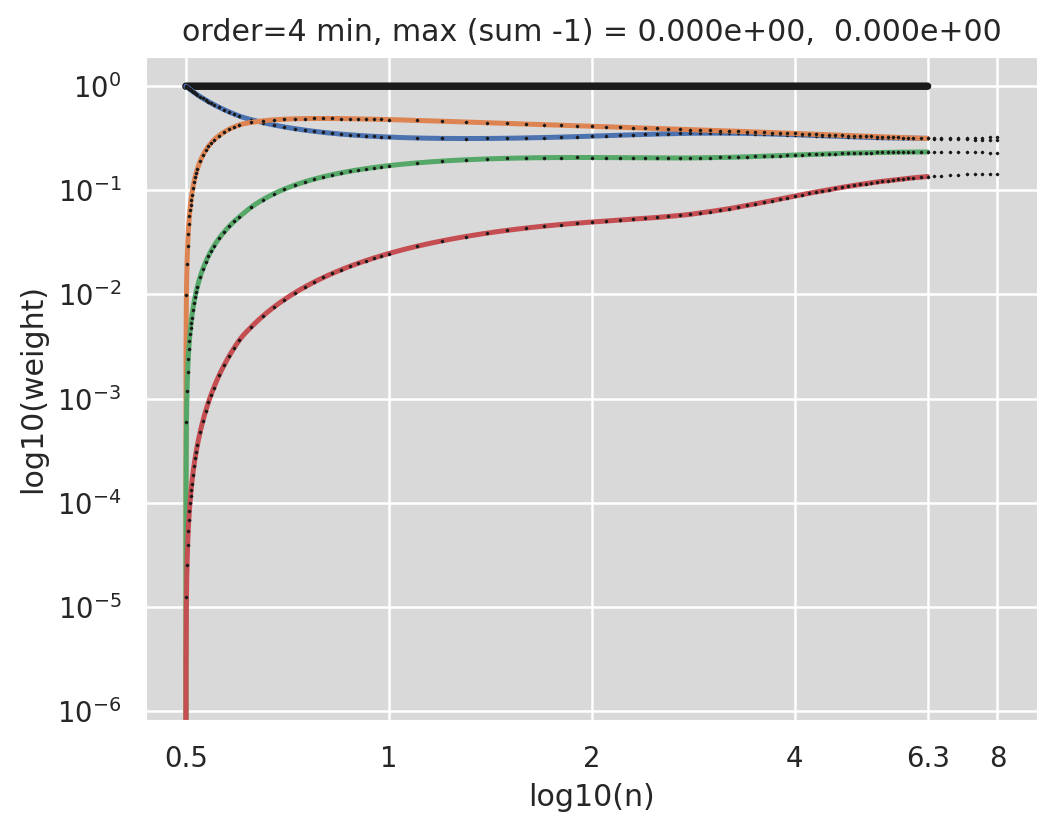

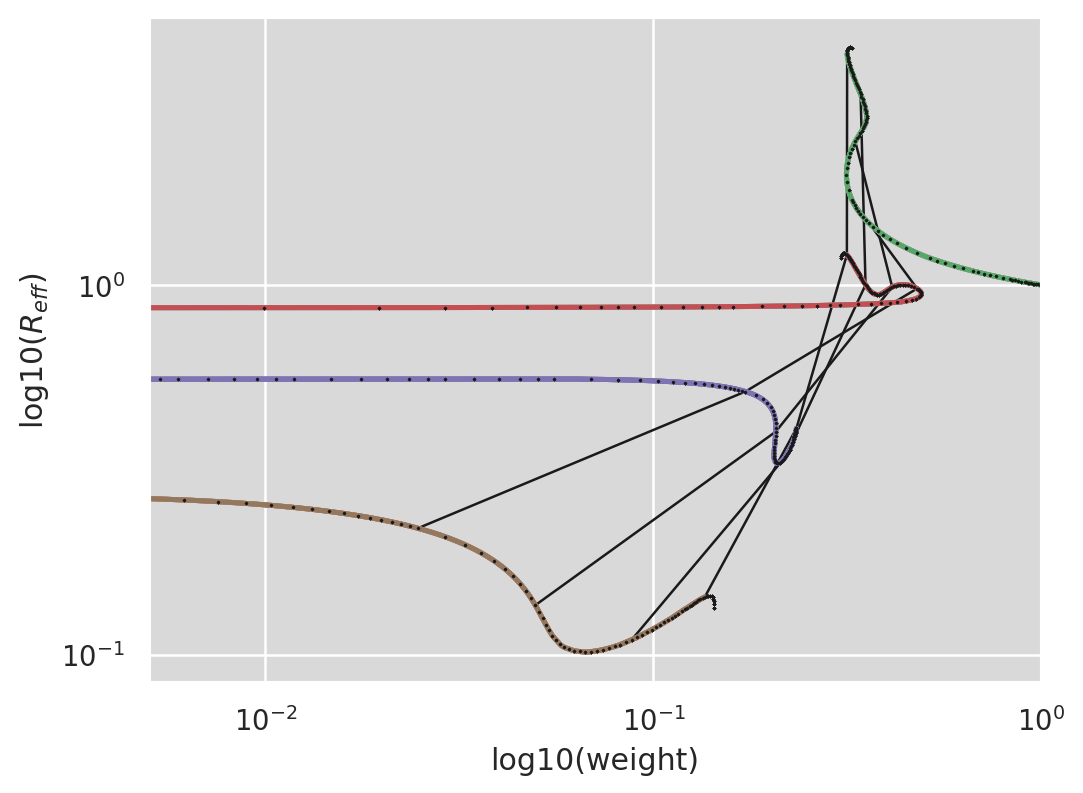

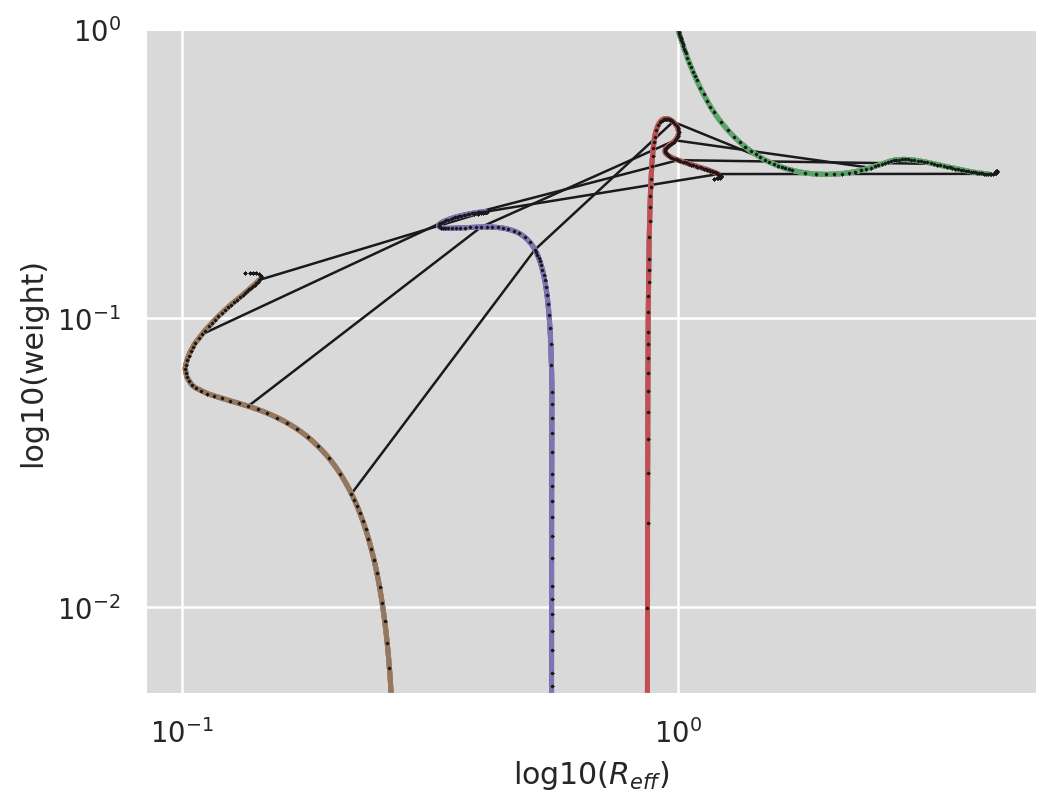

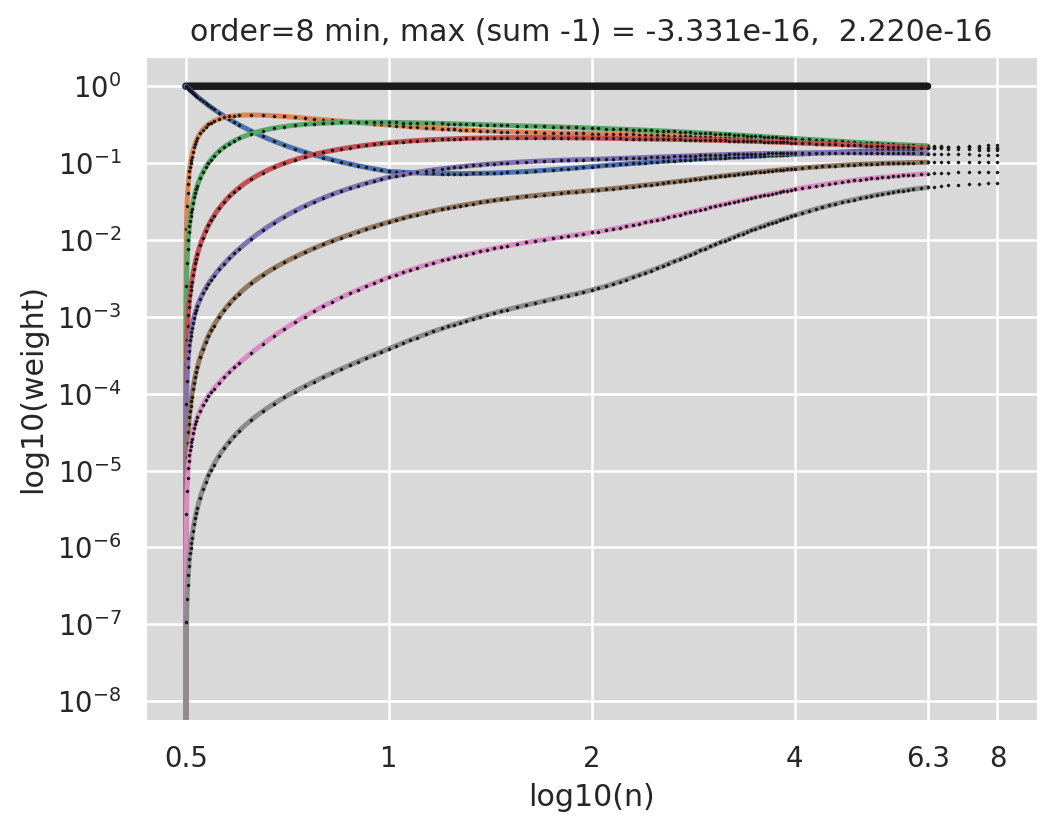

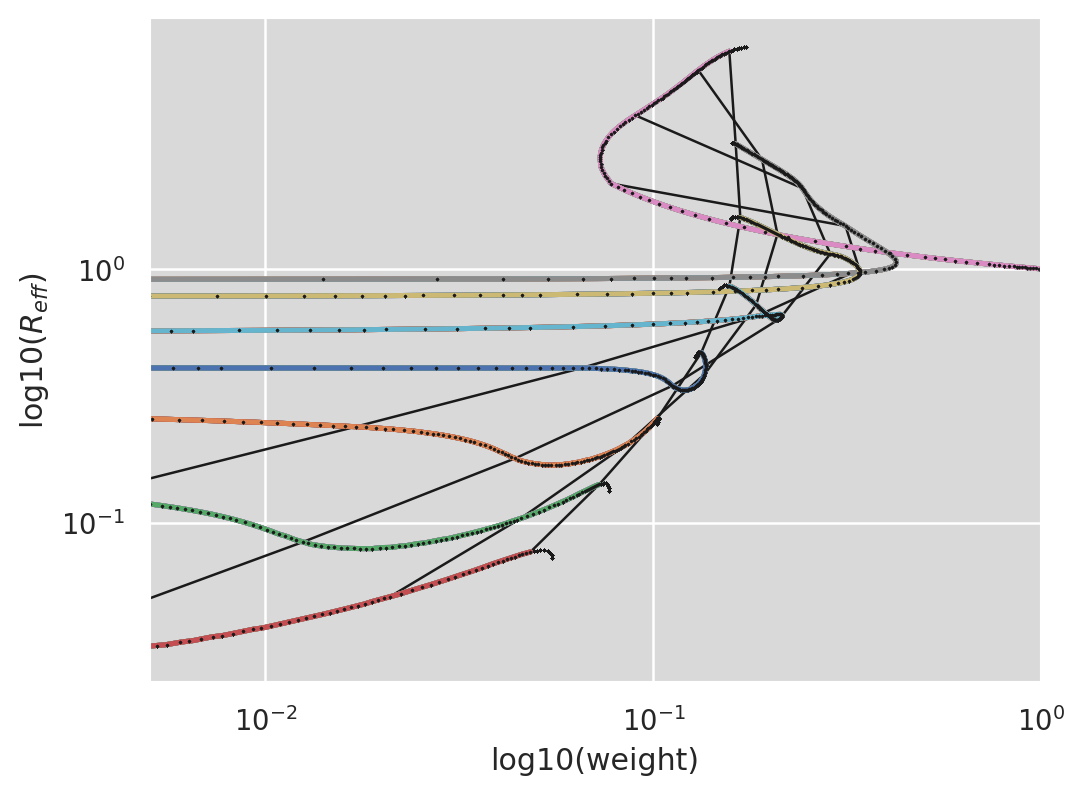

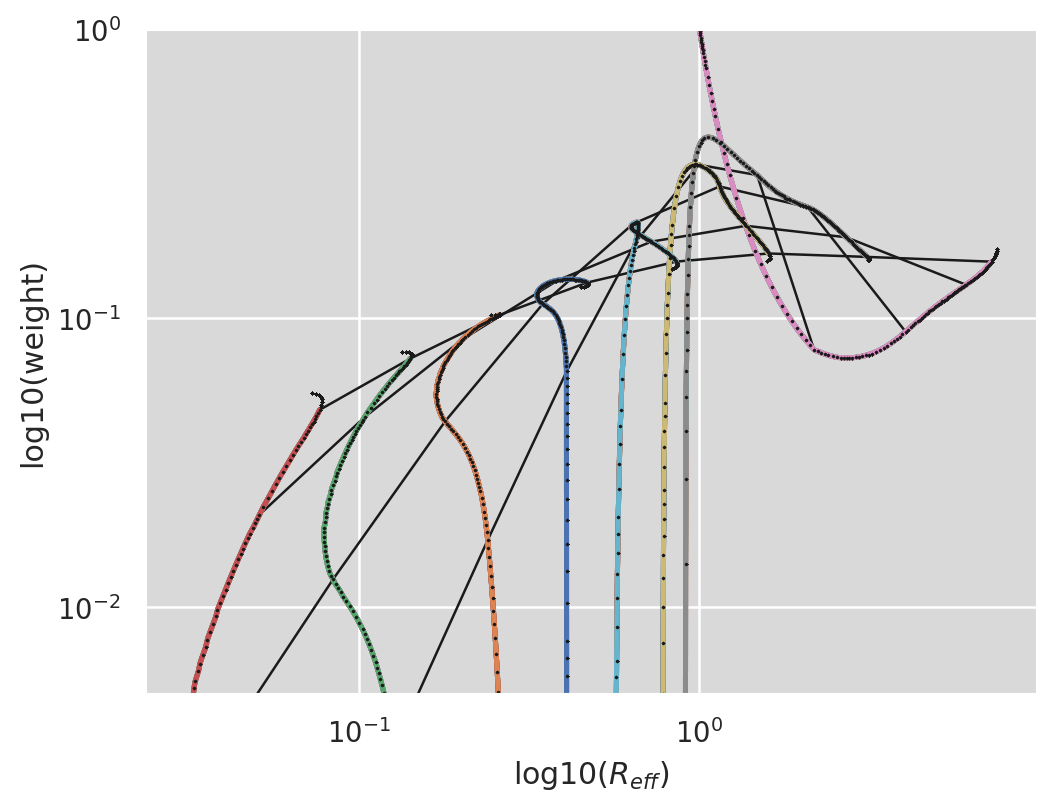

In [7]:
sersic_ticks = [0.5, 1, 2, 4, 6.3, 8]

nsers = 10**np.linspace(np.log10(0.5), np.log10(6.3), 10000)

for order in (4, 8):
    knots = g2f.sersic_mix_knots(order)
    interpolator = g2f.GSLSersicMixInterpolator(order)

    weights, sigmas = get_weights_sigmas(nsers, interpolator)
    nser_knots = np.array([knot.sersicindex for knot in knots])
    weights_knots = np.array([
        [integralsize.integral for integralsize in knot.values]
        for knot in knots
    ])
    sigmas_knots = np.array([
        [integralsize.sigma*g2d.M_HWHM_SIGMA for integralsize in knot.values]
        for knot in knots
    ])

    fig_weights, ax_weights = plot_weights(nsers, weights, nser_knots, weights_knots, sersic_ticks, order)

    for flip in (False, True):
        fig_ws, ax_ws = plot_weight_sigmas(
            weights, sigmas, weights_knots, sigmas_knots,
            order=order,
            flip=flip,
        )


In [8]:
# Verify that Sersic n=0.5 is the same as a Gaussian
ny, nx = 51, 51

data = get_gauss2d_data(nx=nx, ny=ny)

# 2.0 is just about the lowest value you can set this to without issues
# With sigma < 0.8 there is significant loss of precision without proper
# pixel integration
# 3.5 would be a 0.7" FWHM PSF with LSSTCam
fwhm_psf = 3.5
sigma_psf = 0.5*fwhm_psf*g2d.M_SIGMA_HWHM
half_light_radius = 5.0

psfmodel_none = g2f.PsfModel(components=[g2f.GaussianComponent()])
psfmodel_gauss = g2f.PsfModel(components=[
    g2f.GaussianComponent(g2f.GaussianParametricEllipse(sigma_x=sigma_psf, sigma_y=sigma_psf))
])

model_gauss, model_sersic, model_sersic_conv = get_gauss2d_fit_models(
    data,
    psfmodel_none,
    psfmodel_gauss,
    half_light_radius=half_light_radius,
    nx=nx,
    ny=ny,
    interpolator=g2f.GSLSersicMixInterpolator(4)
)
for model in model_sersic_conv, model_sersic, model_gauss:
    model.setup_evaluators(evaluatormode=g2f.EvaluatorMode.image)
    model.evaluate()

print(f"g2d sersic - g2d gaussian sum abs diff sq={np.sum((model_sersic.outputs[0].data - model_gauss.outputs[0].data)**2):.3e}")

if has_galsim:
    psf_gs = gs.Gaussian(sigma=sigma_psf)
    sersic_gs = gs.Sersic(n=0.5, half_light_radius=half_light_radius)
    sersic_conv_gs = gs.Convolution(sersic_gs, psf_gs)
    gauss_gs = gs.Gaussian(sigma=5*g2d.M_SIGMA_HWHM)
    image_gs_gauss, image_gs_sersic, image_gs_sersic_conv = (
        object_gs.drawImage(nx=nx, ny=ny, method="no_pixel", dtype=np.float64, scale=1.0).array
        for object_gs in (gauss_gs, sersic_gs, sersic_conv_gs)
    )
    print("galsim gauss - g2d gauss", np.sum((image_gs_gauss - model_gauss.outputs[0].data)**2))
    print("galsim sersic - galsim gauss", np.sum((image_gs_sersic - image_gs_gauss)**2))
    print("galsim sersic - g2d sersic", np.sum((image_gs_sersic - model_sersic.outputs[0].data)**2))
    print("galsim sersic - g2d sersic convolved", np.sum((image_gs_sersic_conv - model_sersic_conv.outputs[0].data)**2))
else:
    psf_gs = None


g2d sersic - g2d gaussian sum abs diff sq=0.000e+00
galsim gauss - g2d gauss 4.881852252918002e-34
galsim sersic - galsim gauss 2.445133697468332e-25
galsim sersic - g2d sersic 2.445303650859238e-25
galsim sersic - g2d sersic convolved 3.306429780057844e-14


### Plot images of the Sersic profile

Here we show the profile of a poorly-resolved galaxy (5 pixel = 1" effective radius) on its own, and convolved by a typical single Gaussian PSF.

If available, Galsim is shown for comparison.
Galsim uses the no_pixel method for the PSF-convolved profiles, i.e. no pixel integration and only evaluating the surface brightness profile at the center of each pixel.
These are guaranteed to be adequate to about 1e-6 for sigma > 0.8 pix.
This is not true without PSF convolution - for large Sersic indices, the parts of the profile with a steep slope are not well resolved.
For this reason, we use the real_space integration method with Galsim.
gauss2d does not yet support profile integration (because it is only analytic for a circular Gaussian) even through naive oversampling.
For large Sersic indices, this result in unconvolved fluxes generally being overestimated, and so some of the pre-convolution large-n images have sums greater than unity, even though some of the flux is outside the image bounds.
This is mitigated by the fact that the Gaussian mixture approximation deliberately excludes the steepest part of the core of n>2 profiles.

/tmp/ipykernel_34549/995233480.py:52: RuntimeWarning: invalid value encountered in log10
  ax[idx, 1].imshow(np.log10(image_gs), vmin=-7.5, vmax=-0.5, cmap="gray")
/tmp/ipykernel_34549/995233480.py:20: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(


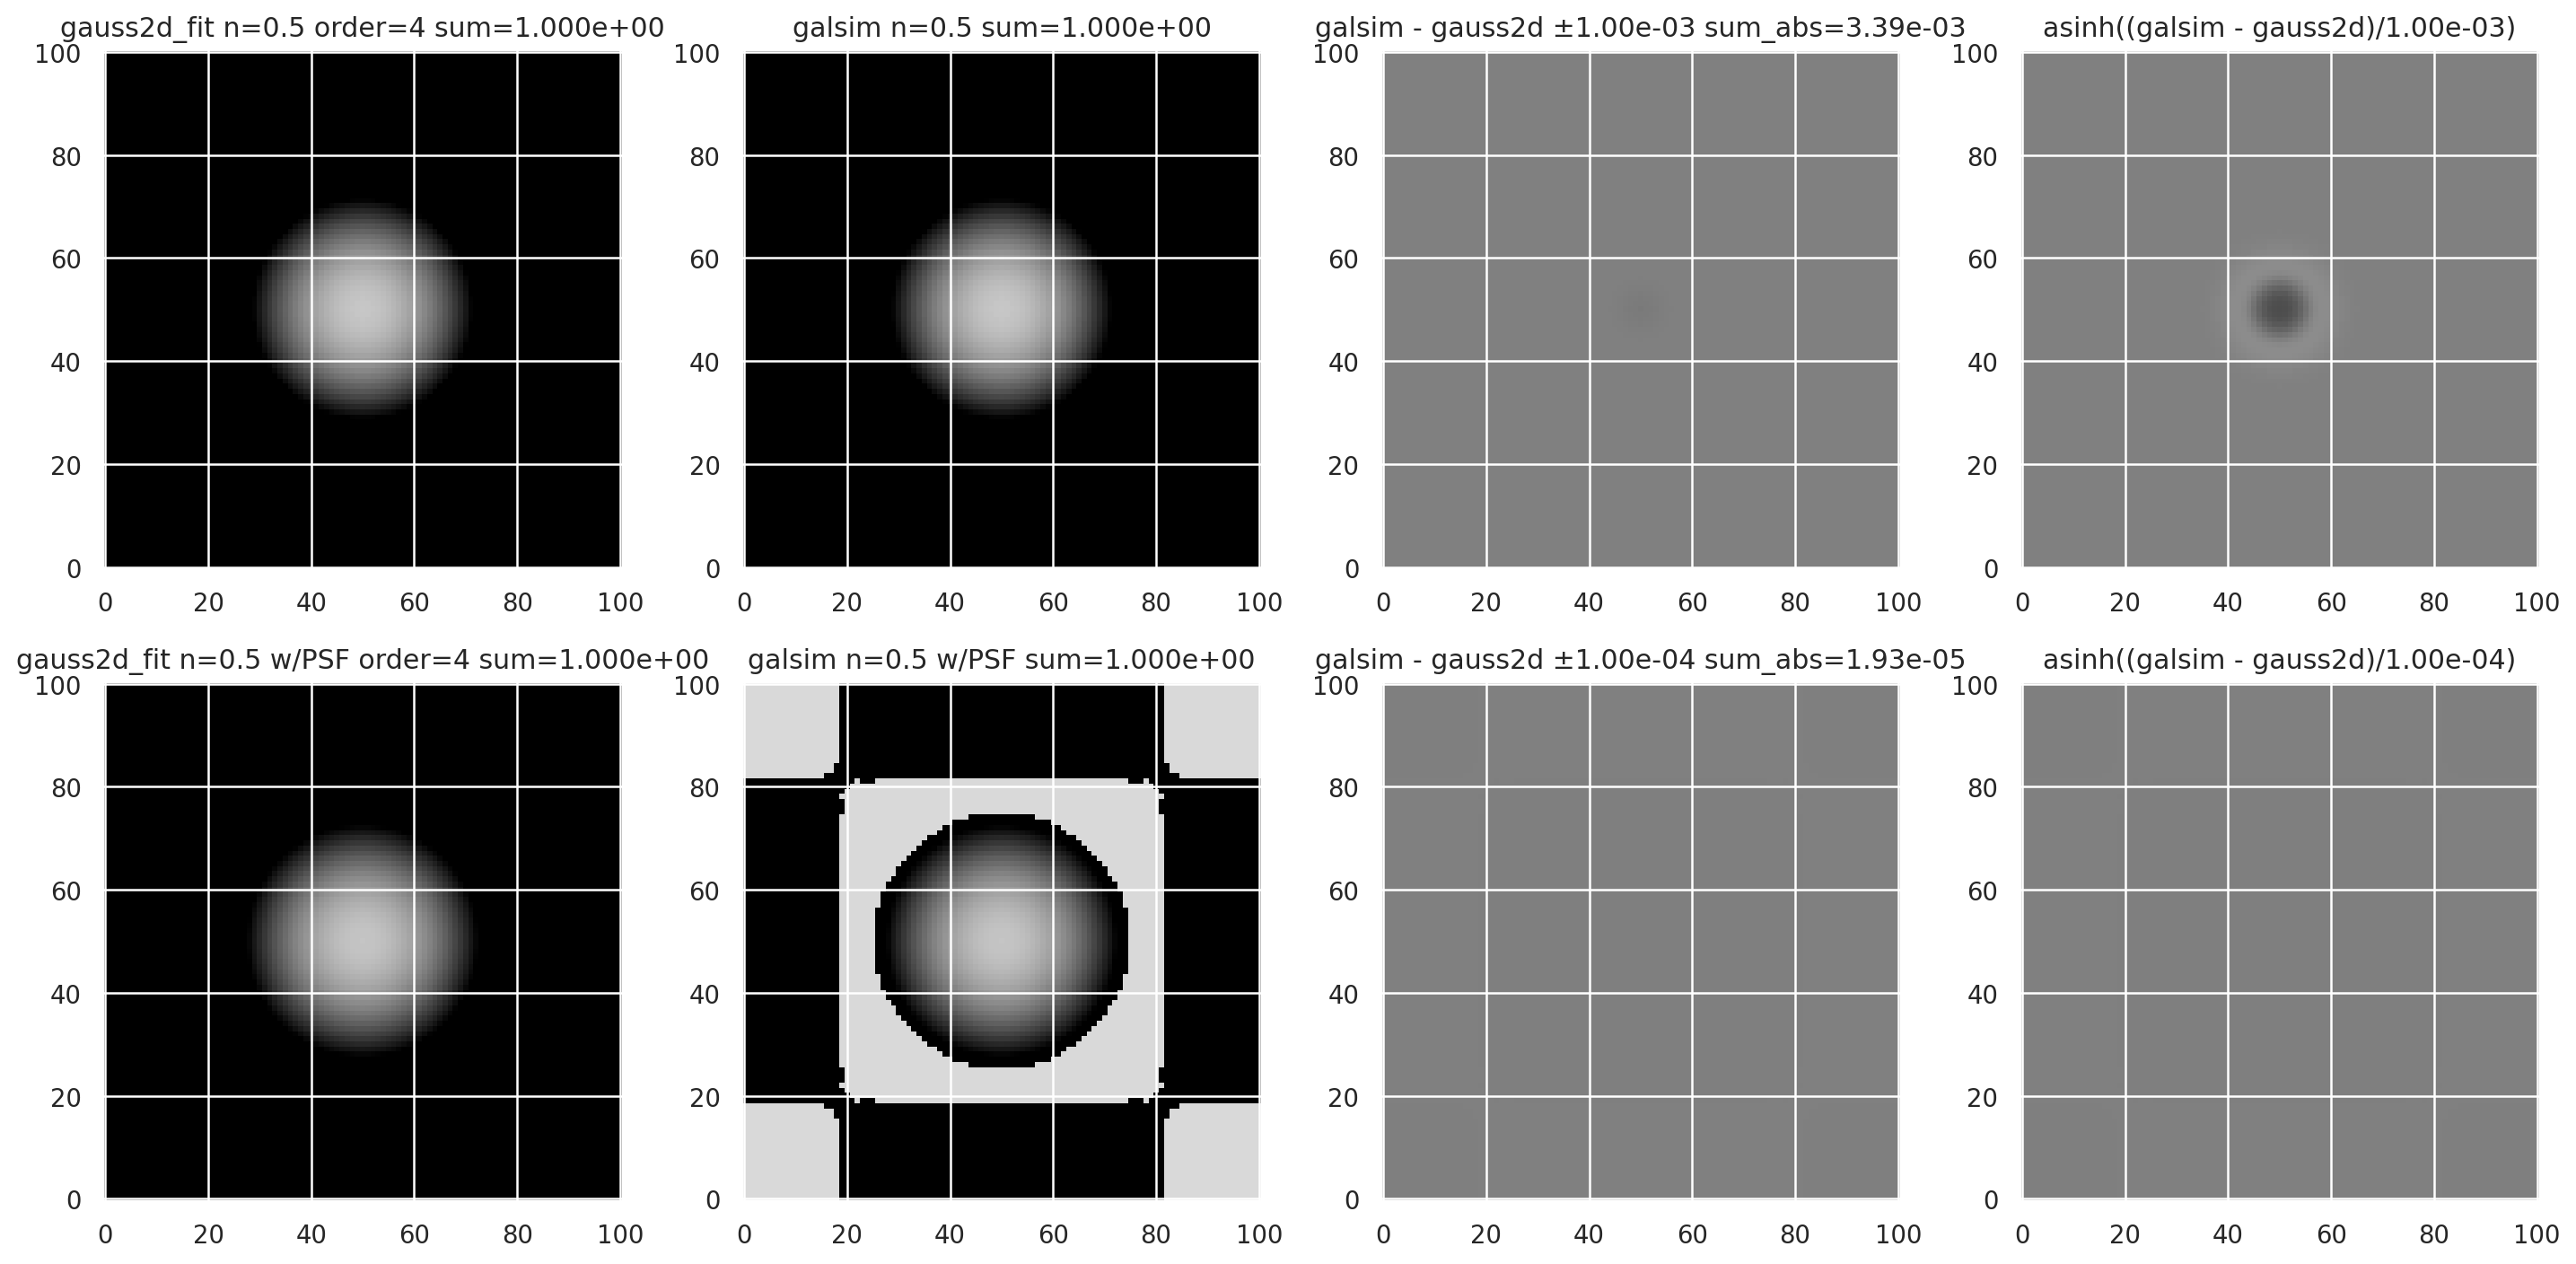

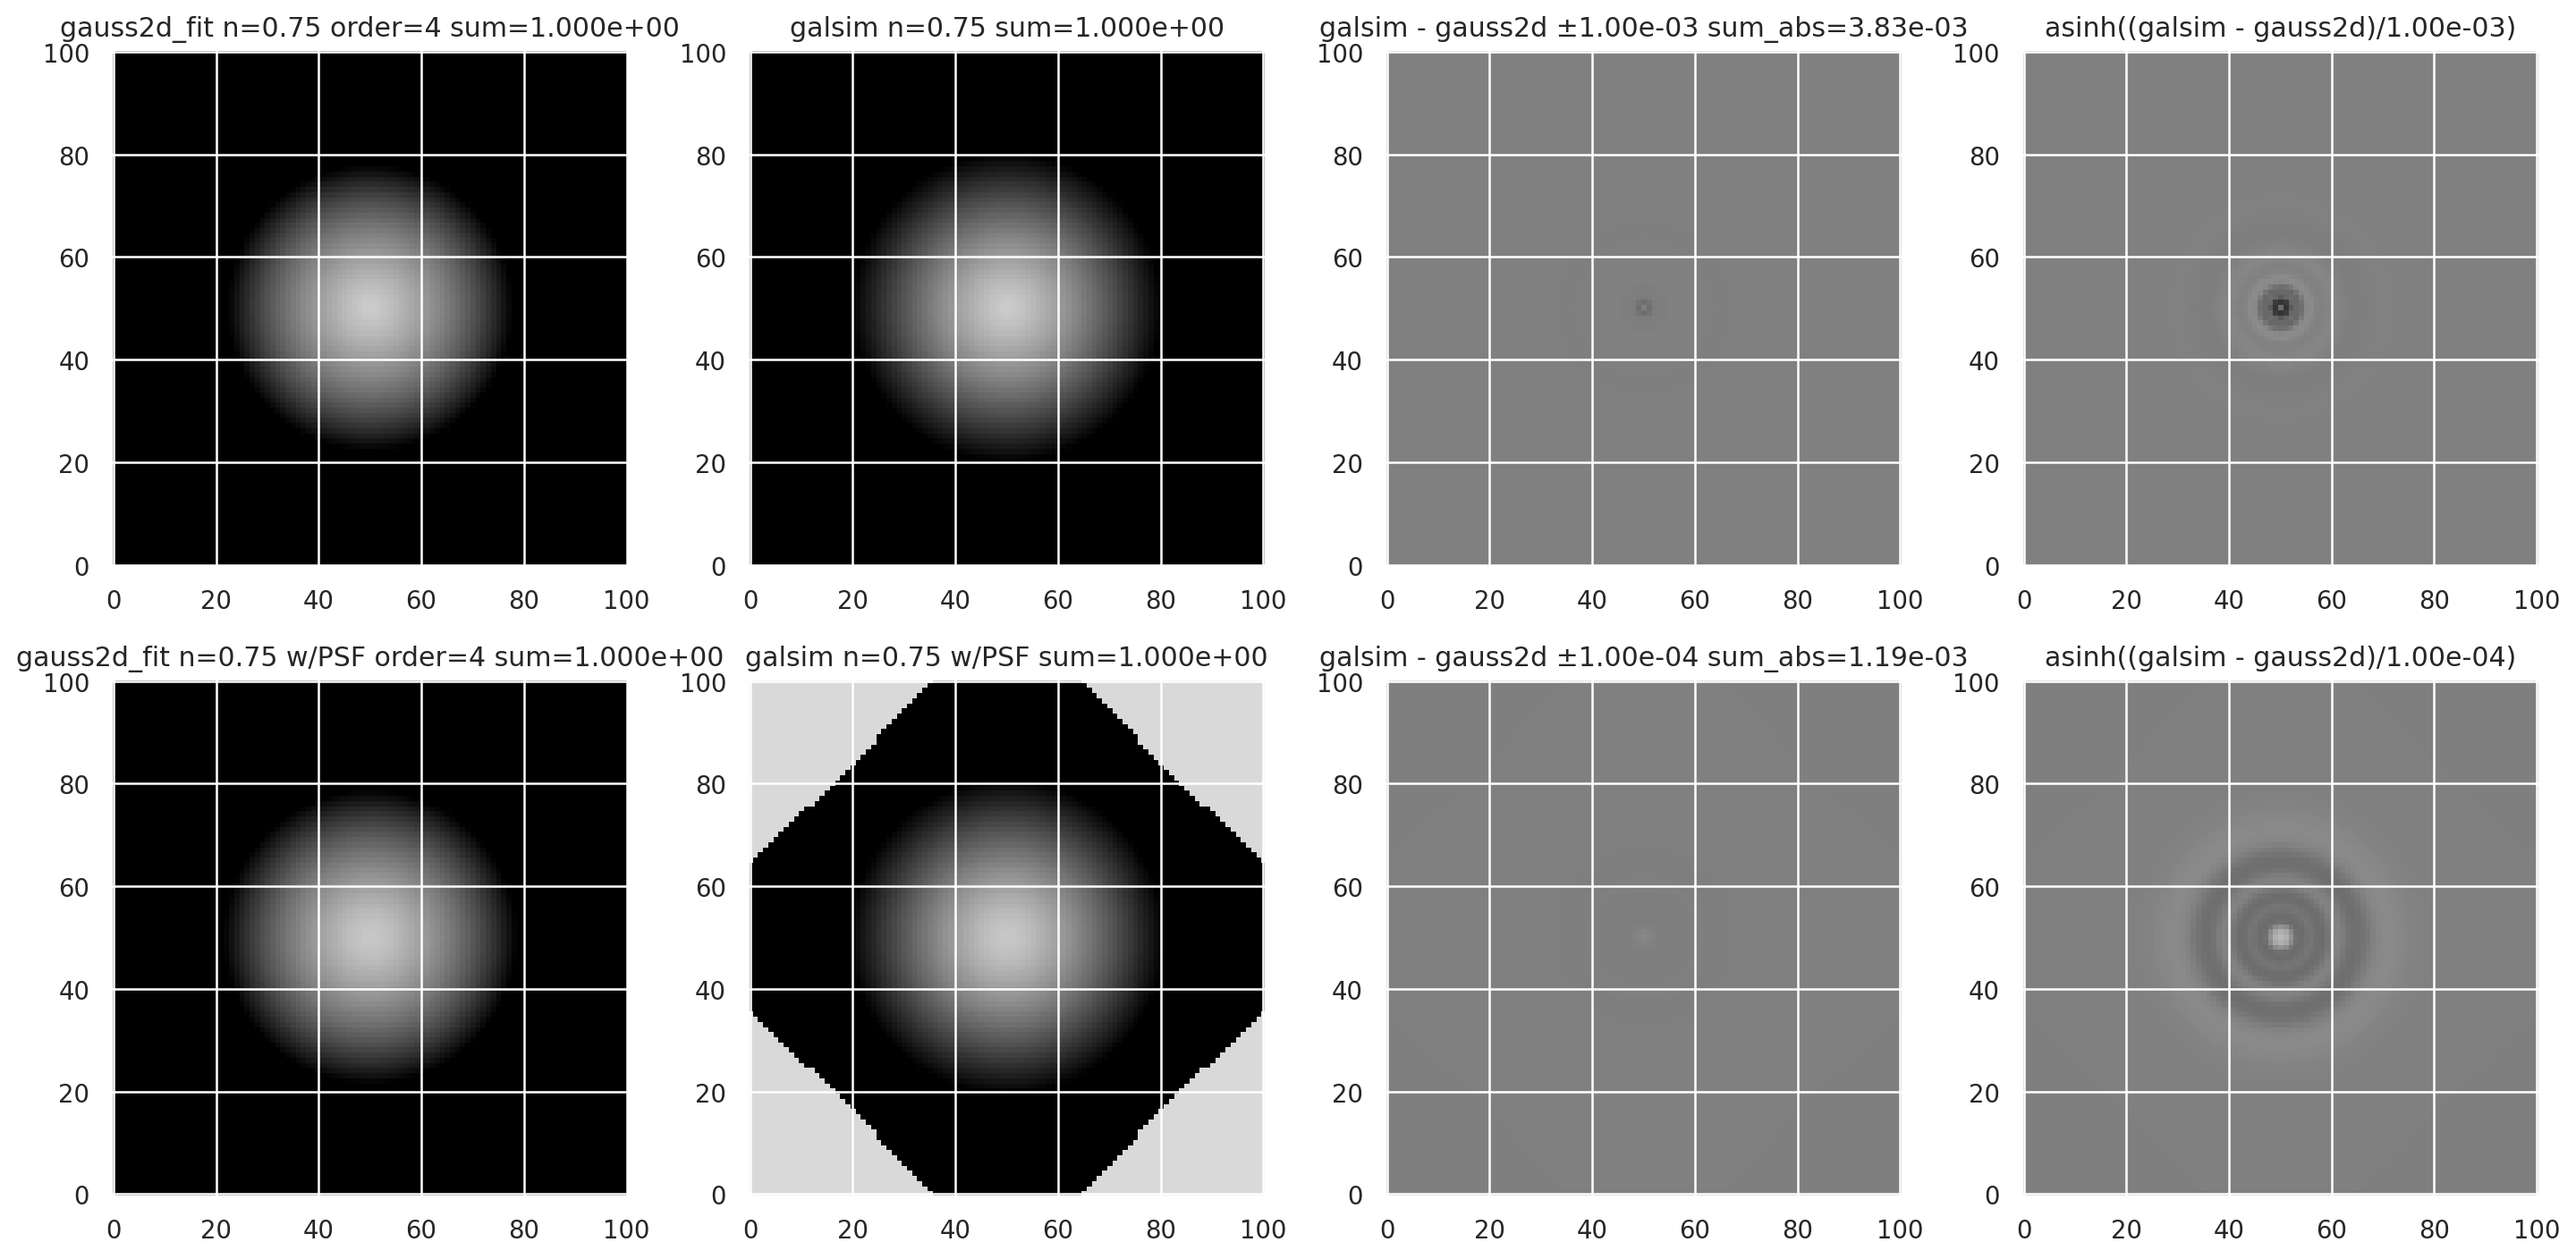

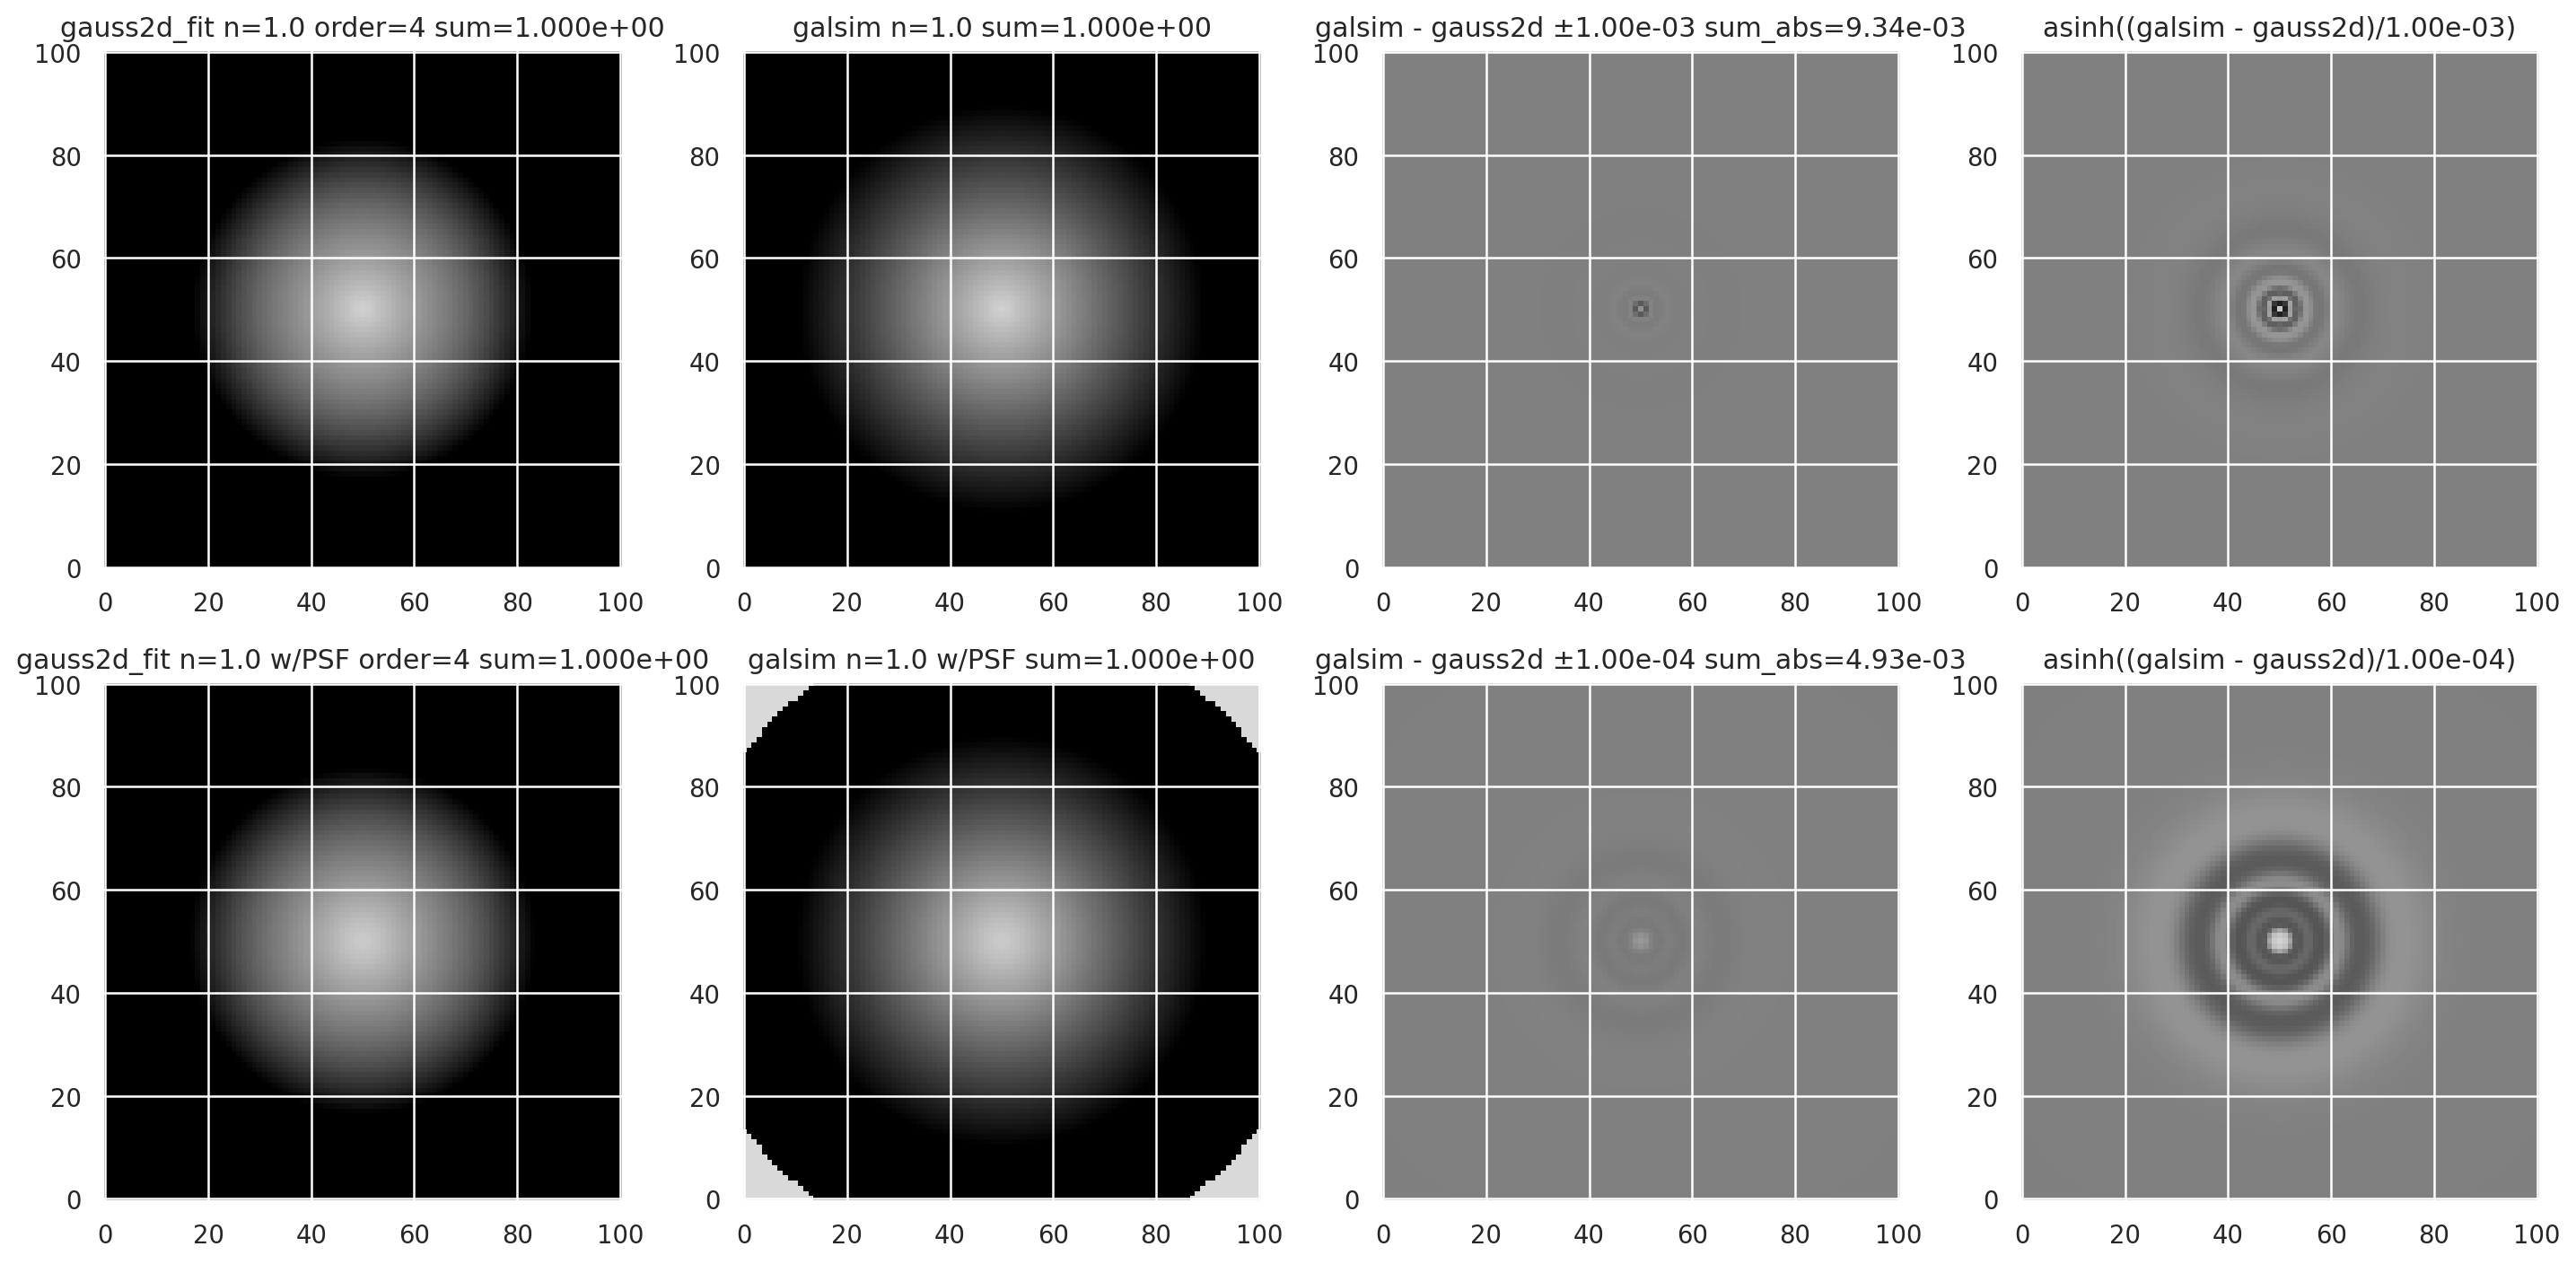

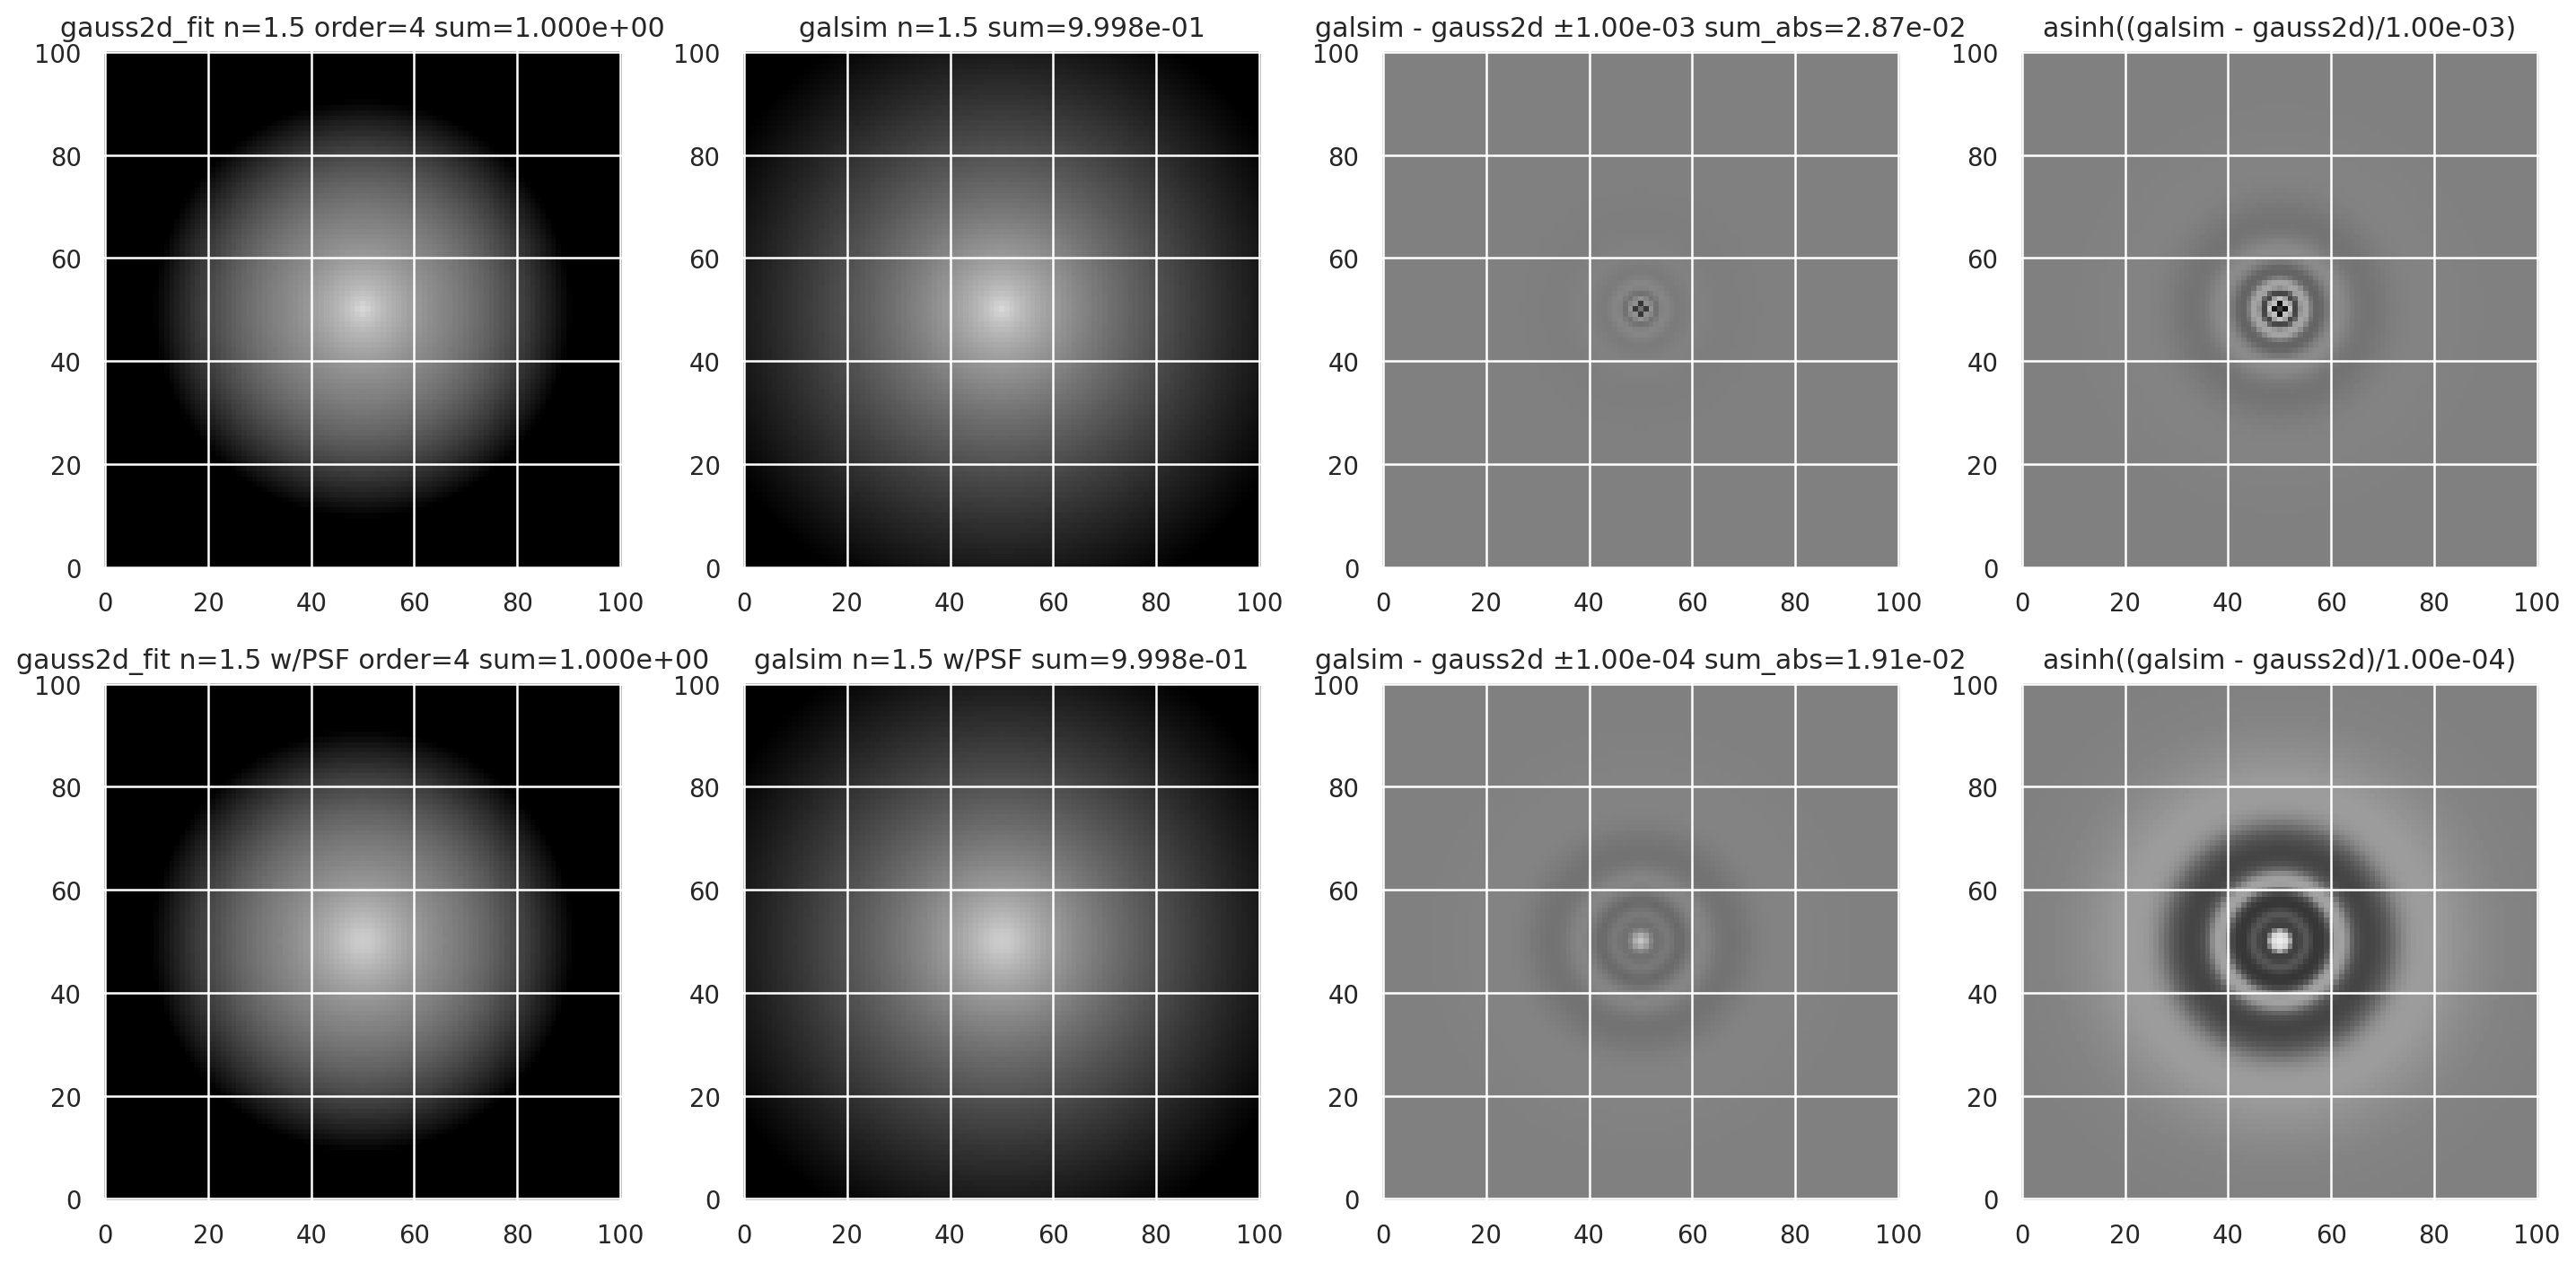

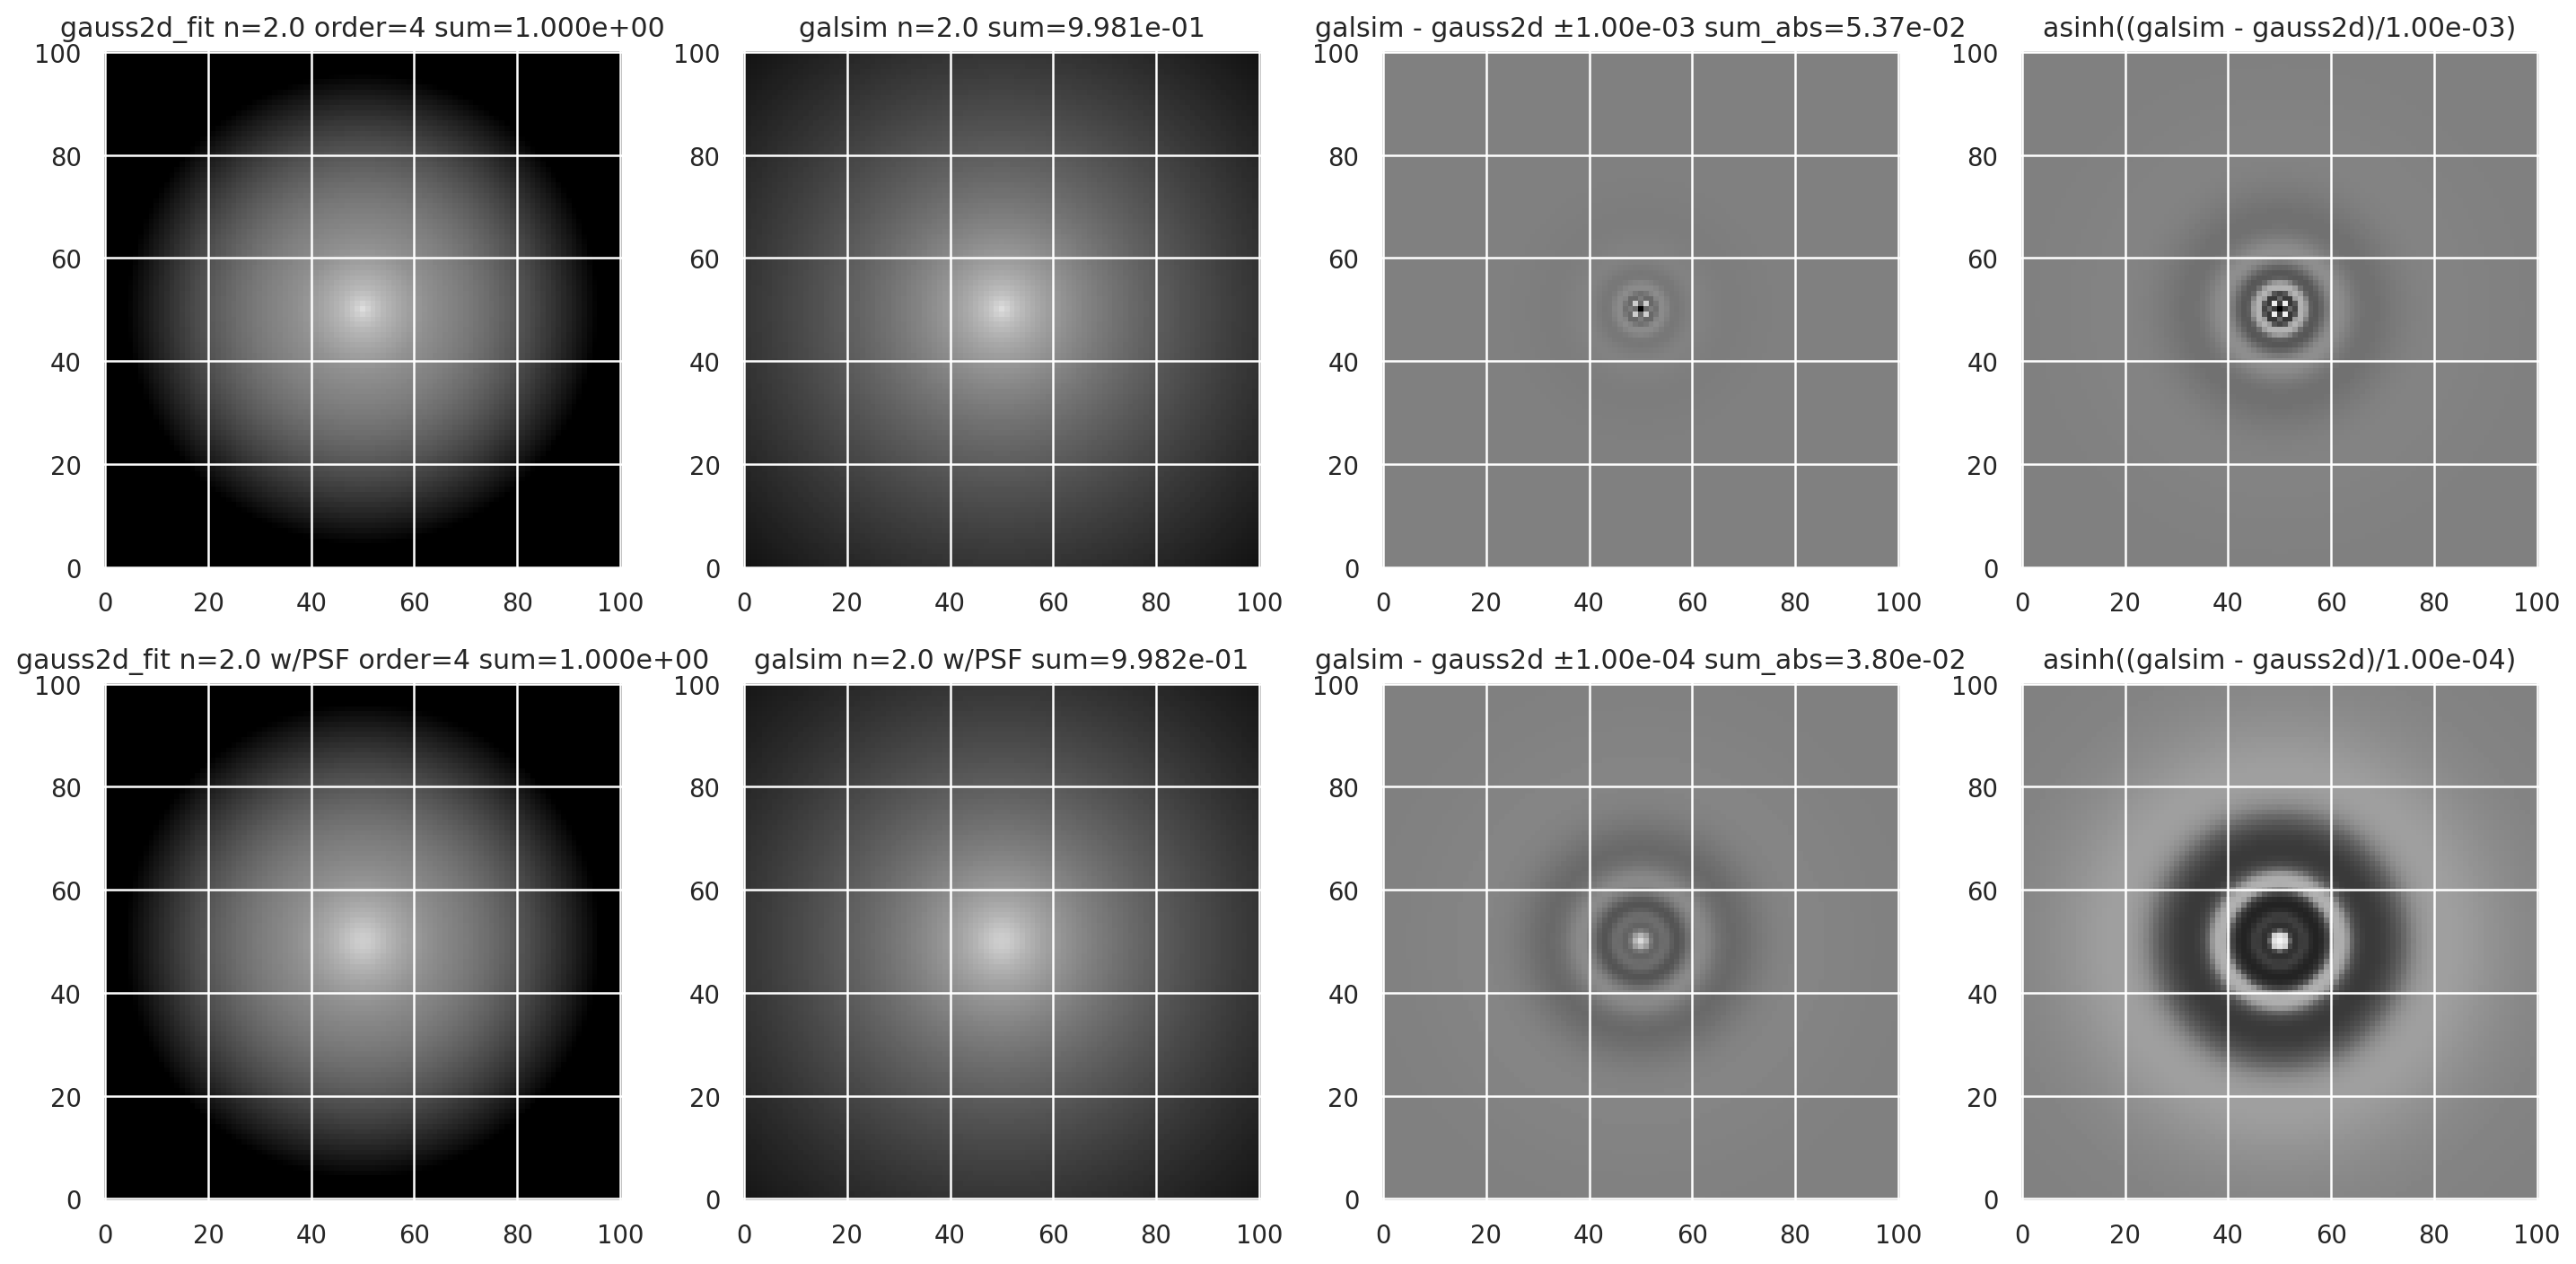

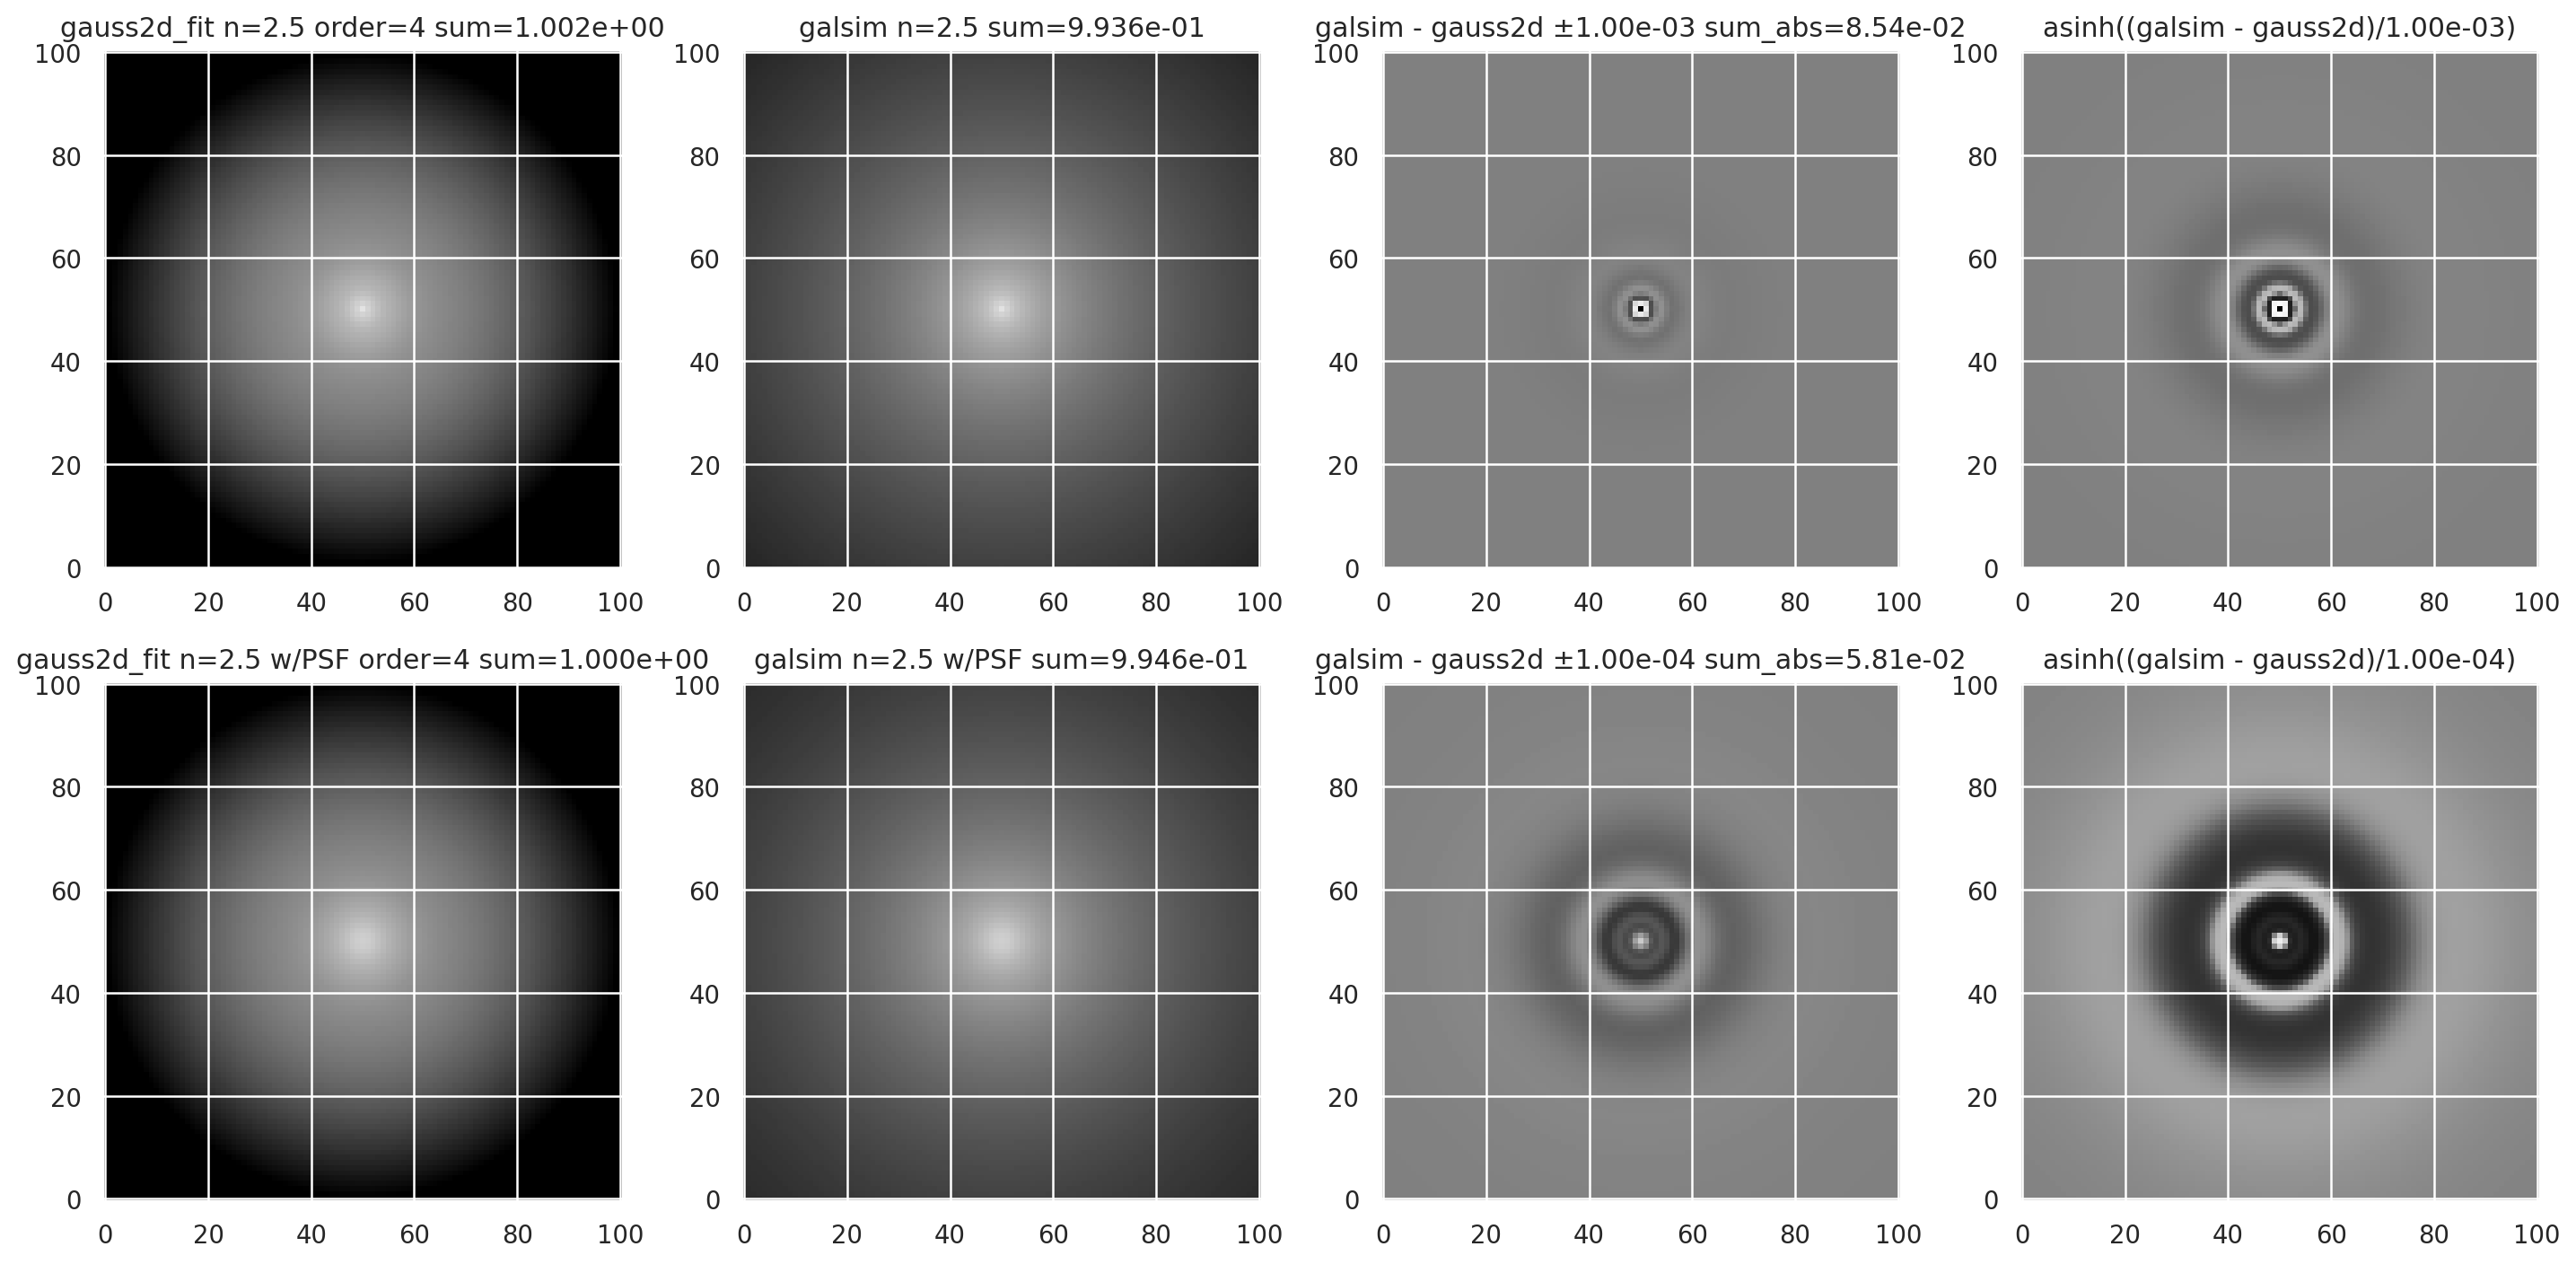

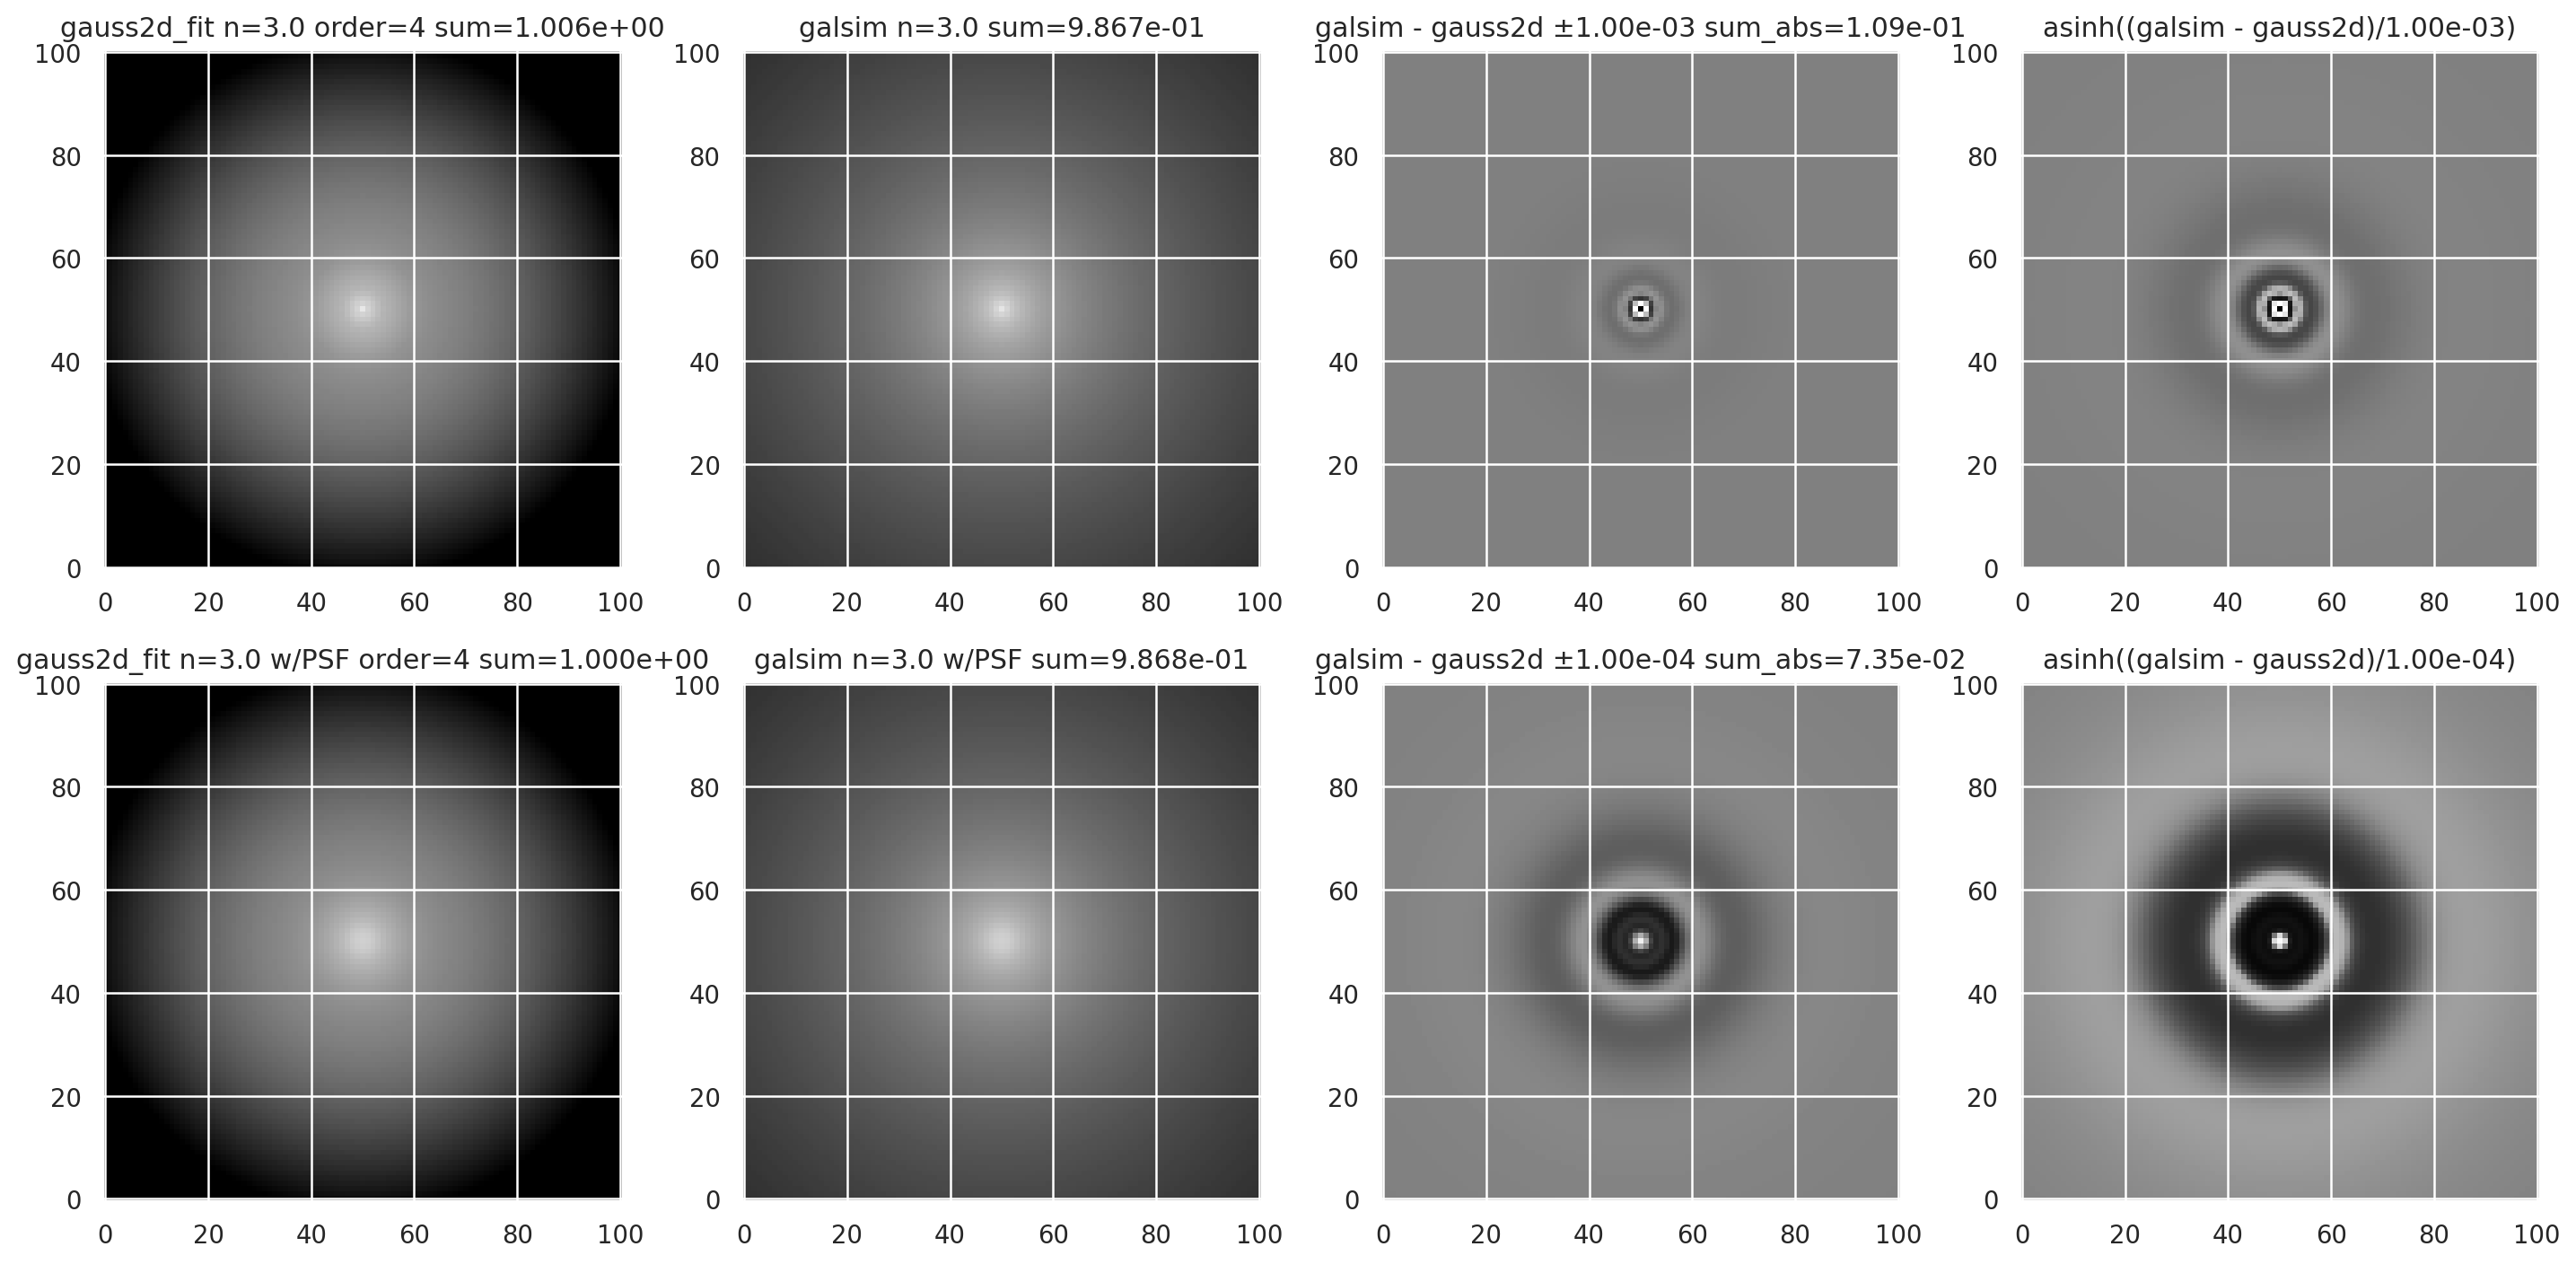

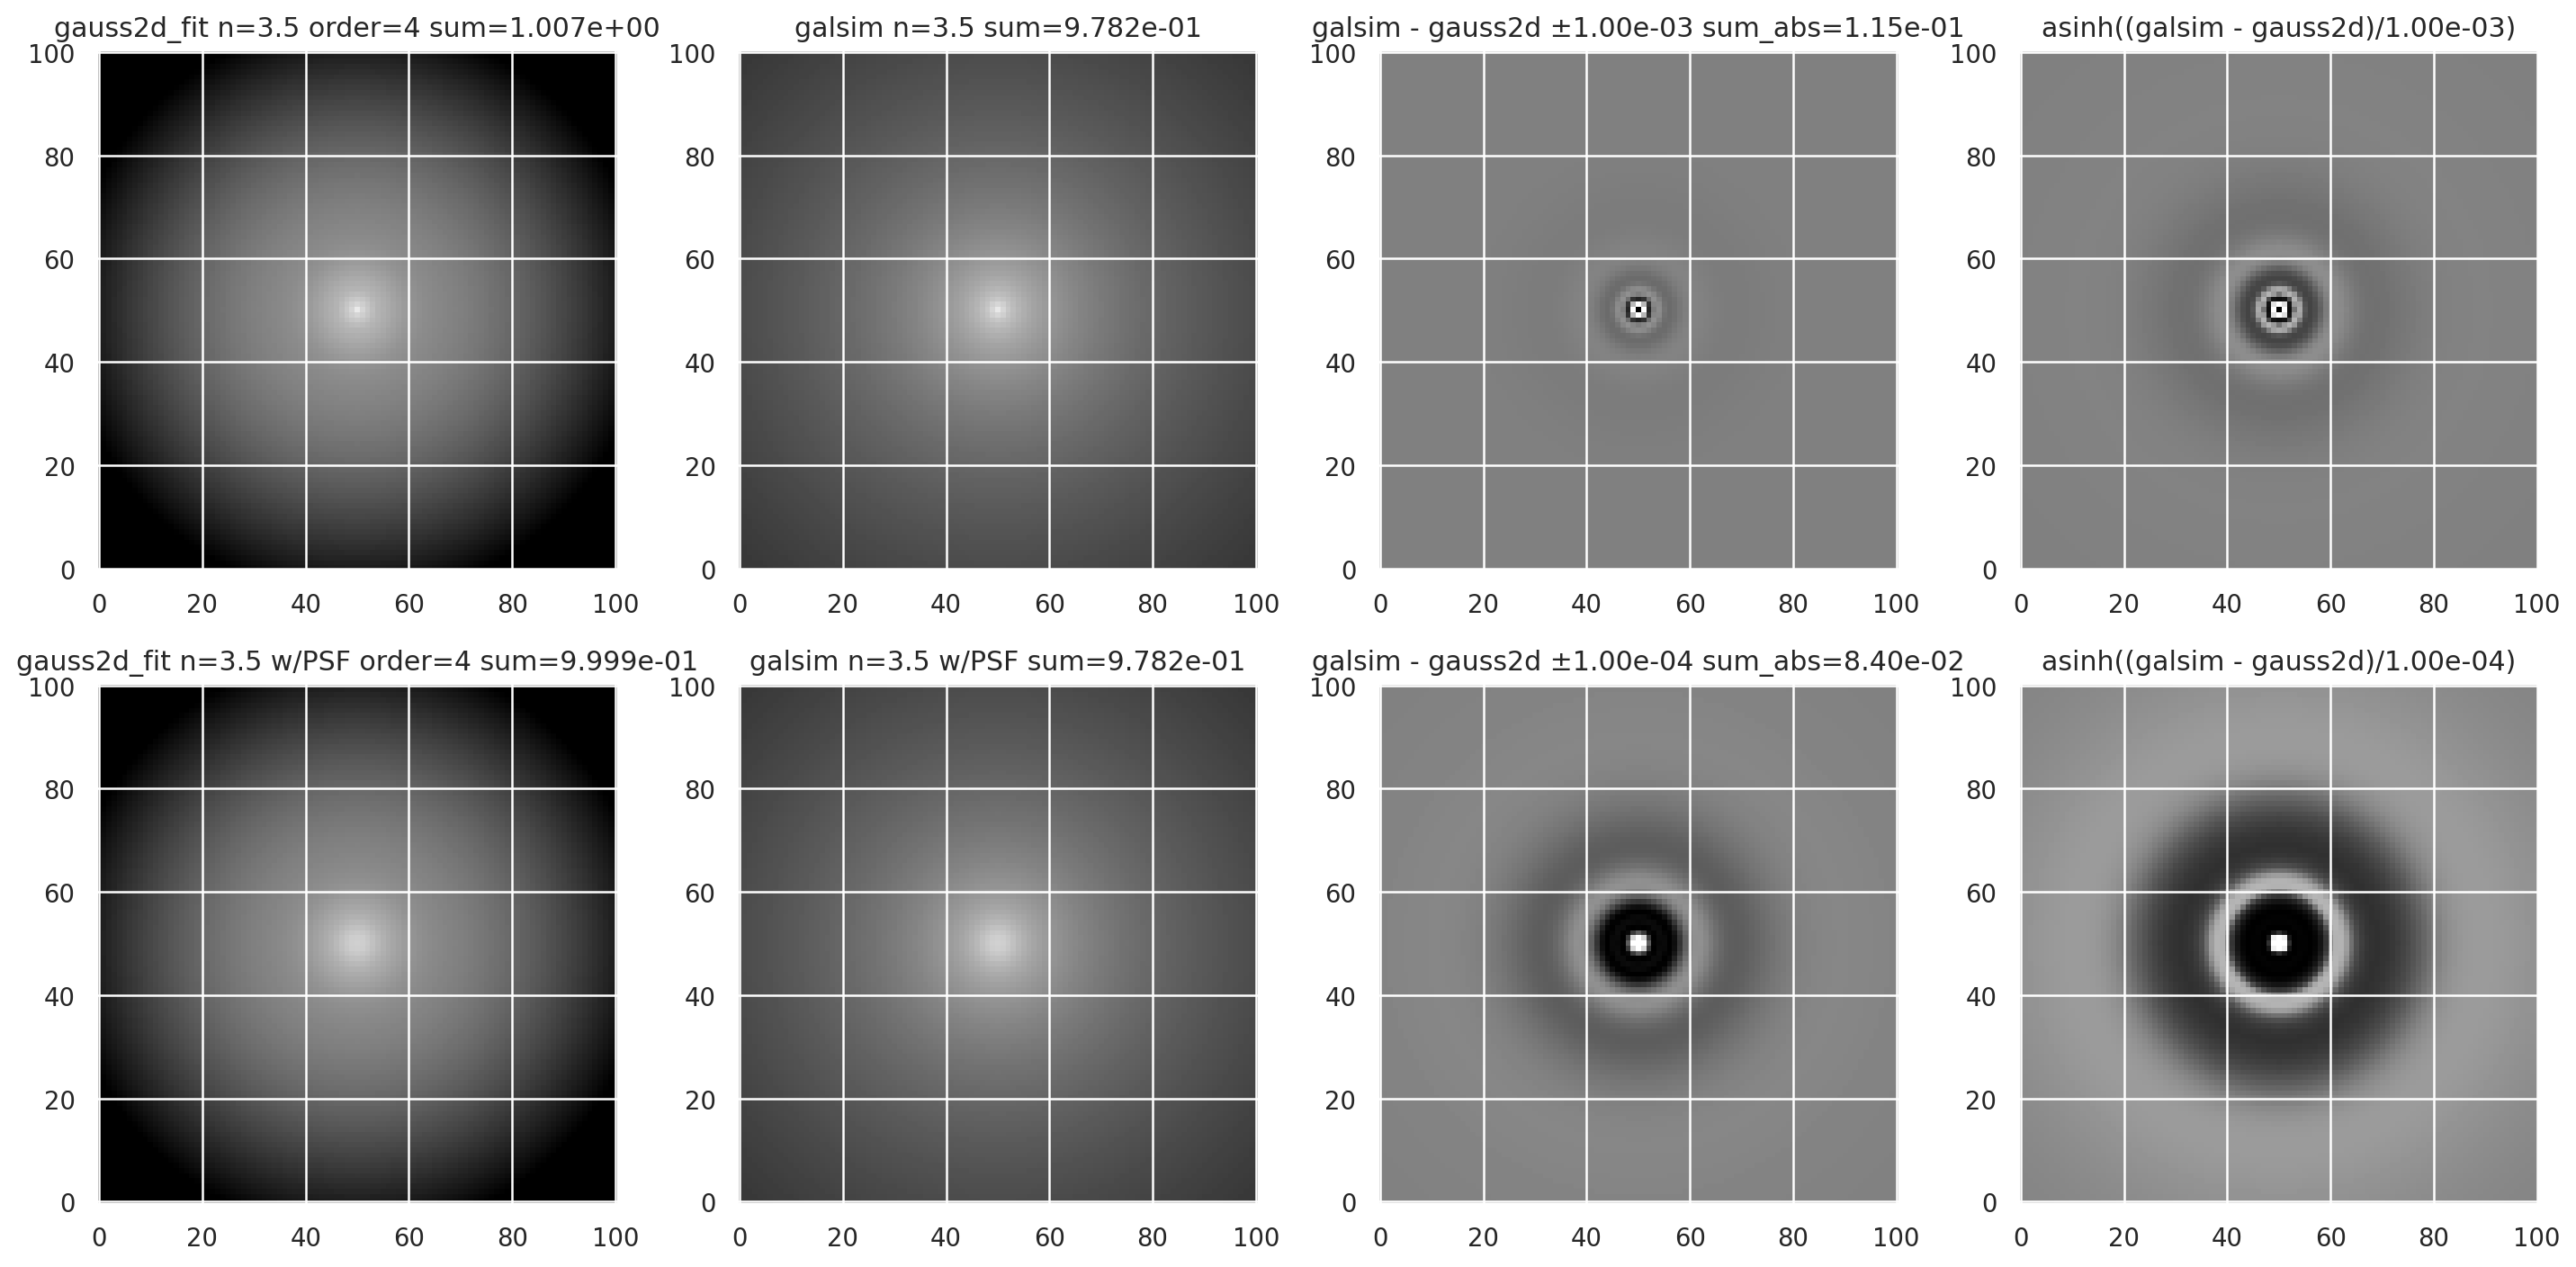

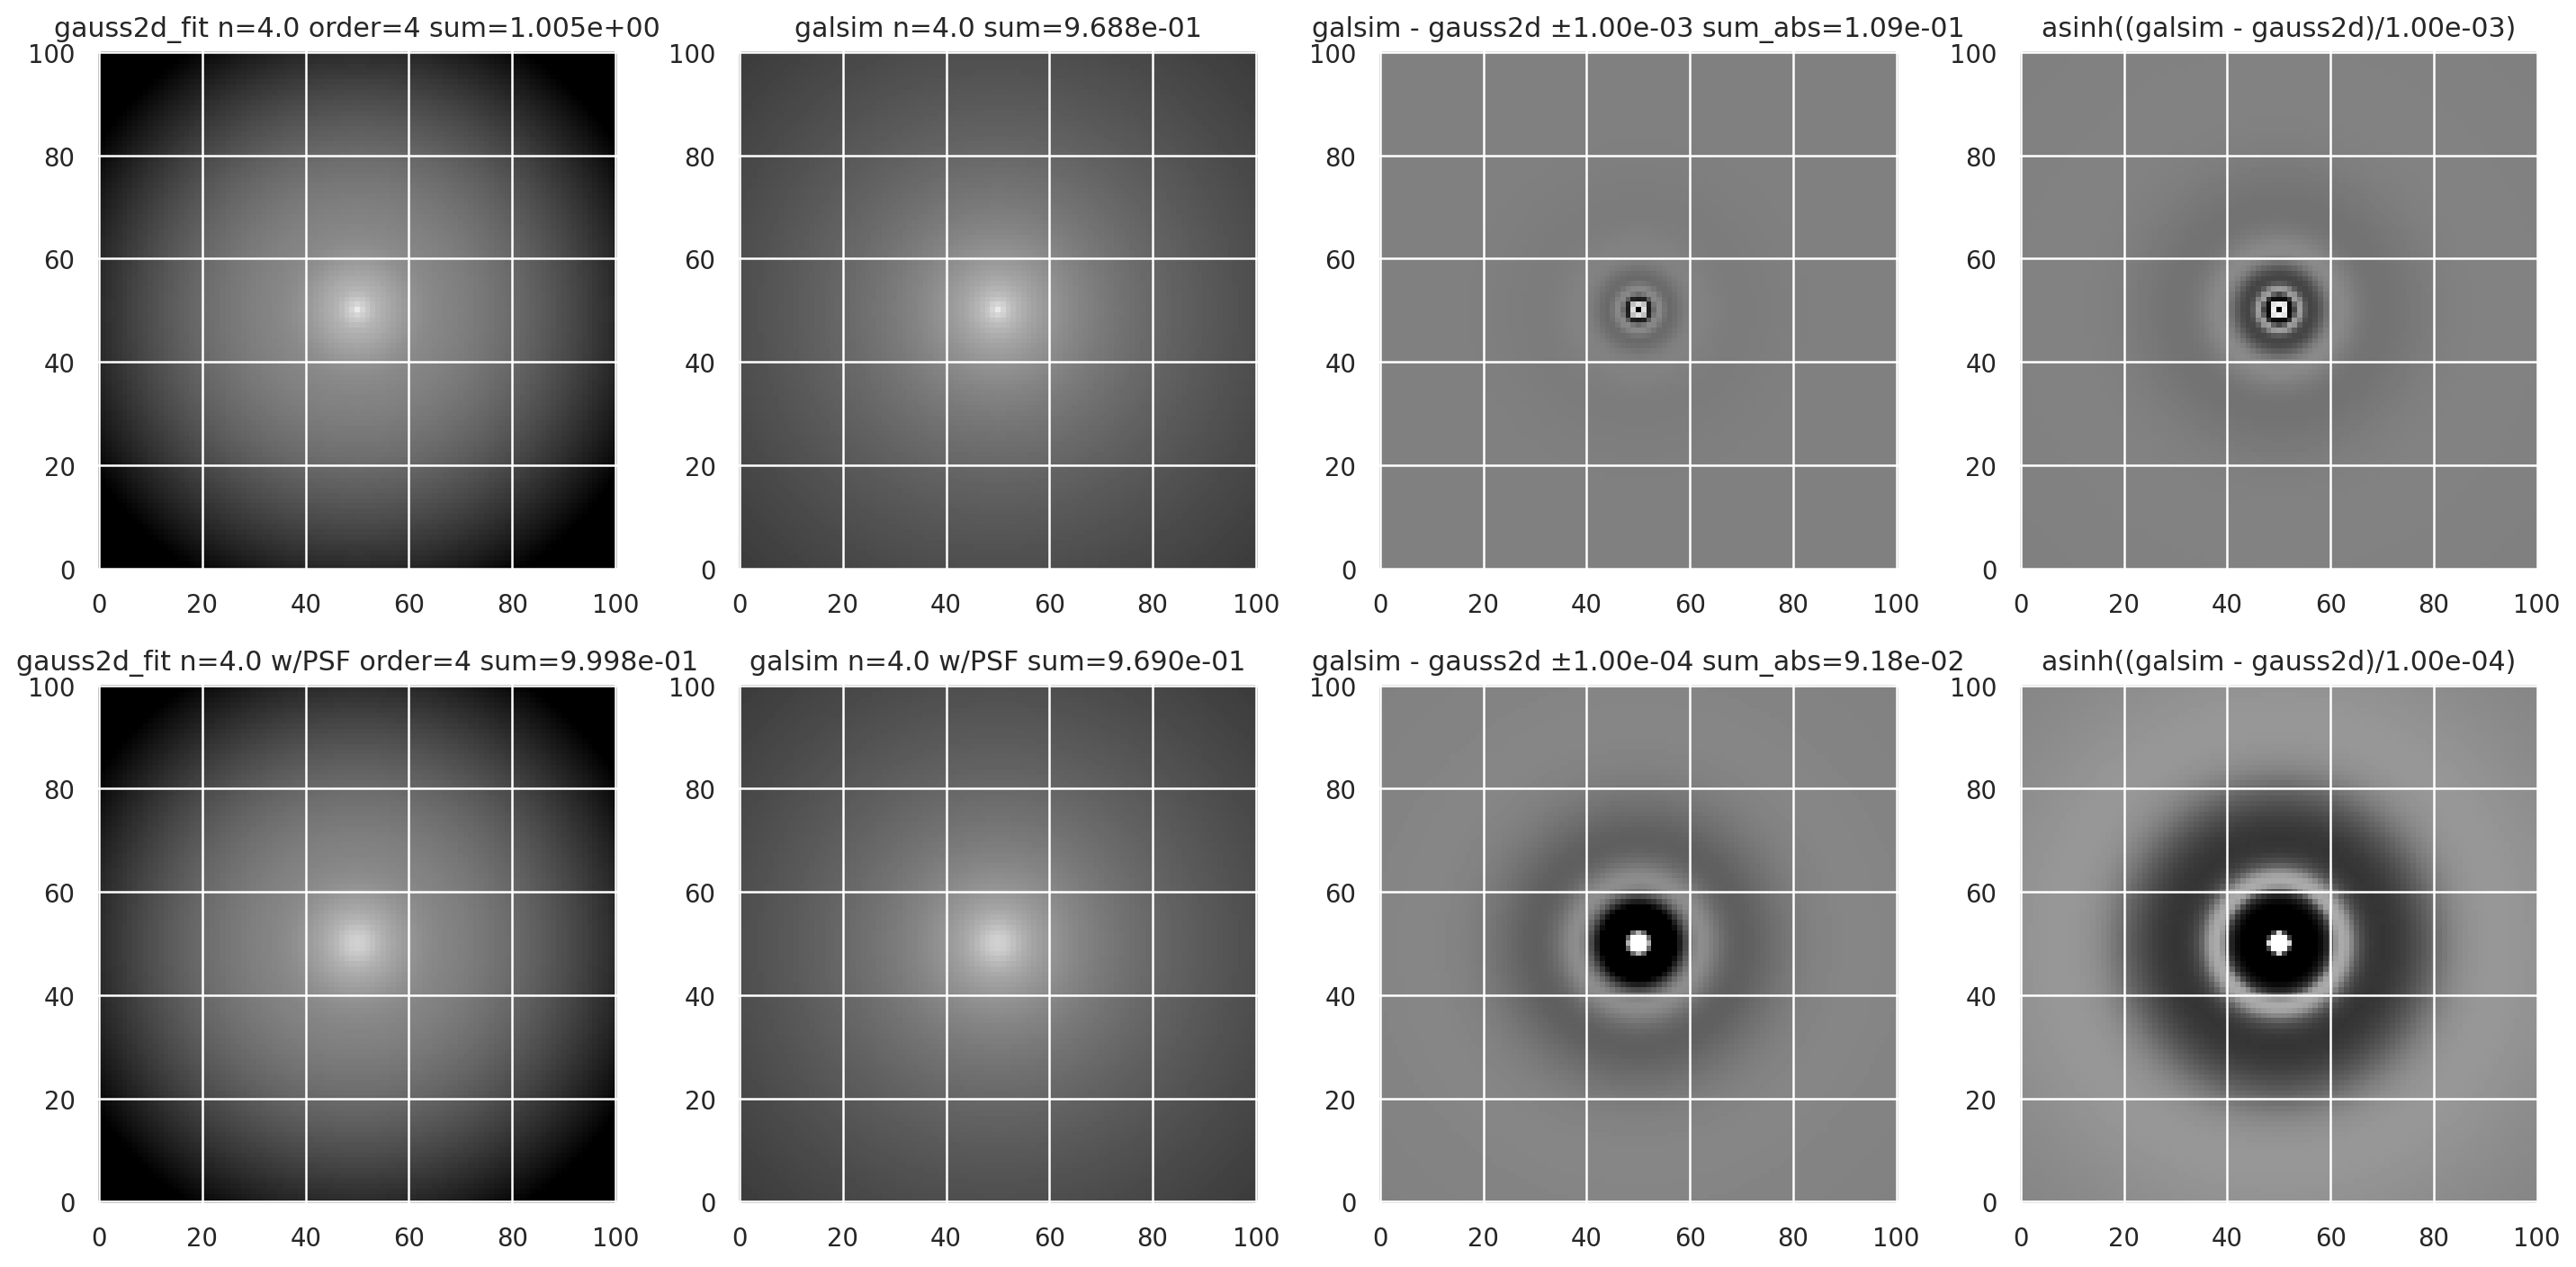

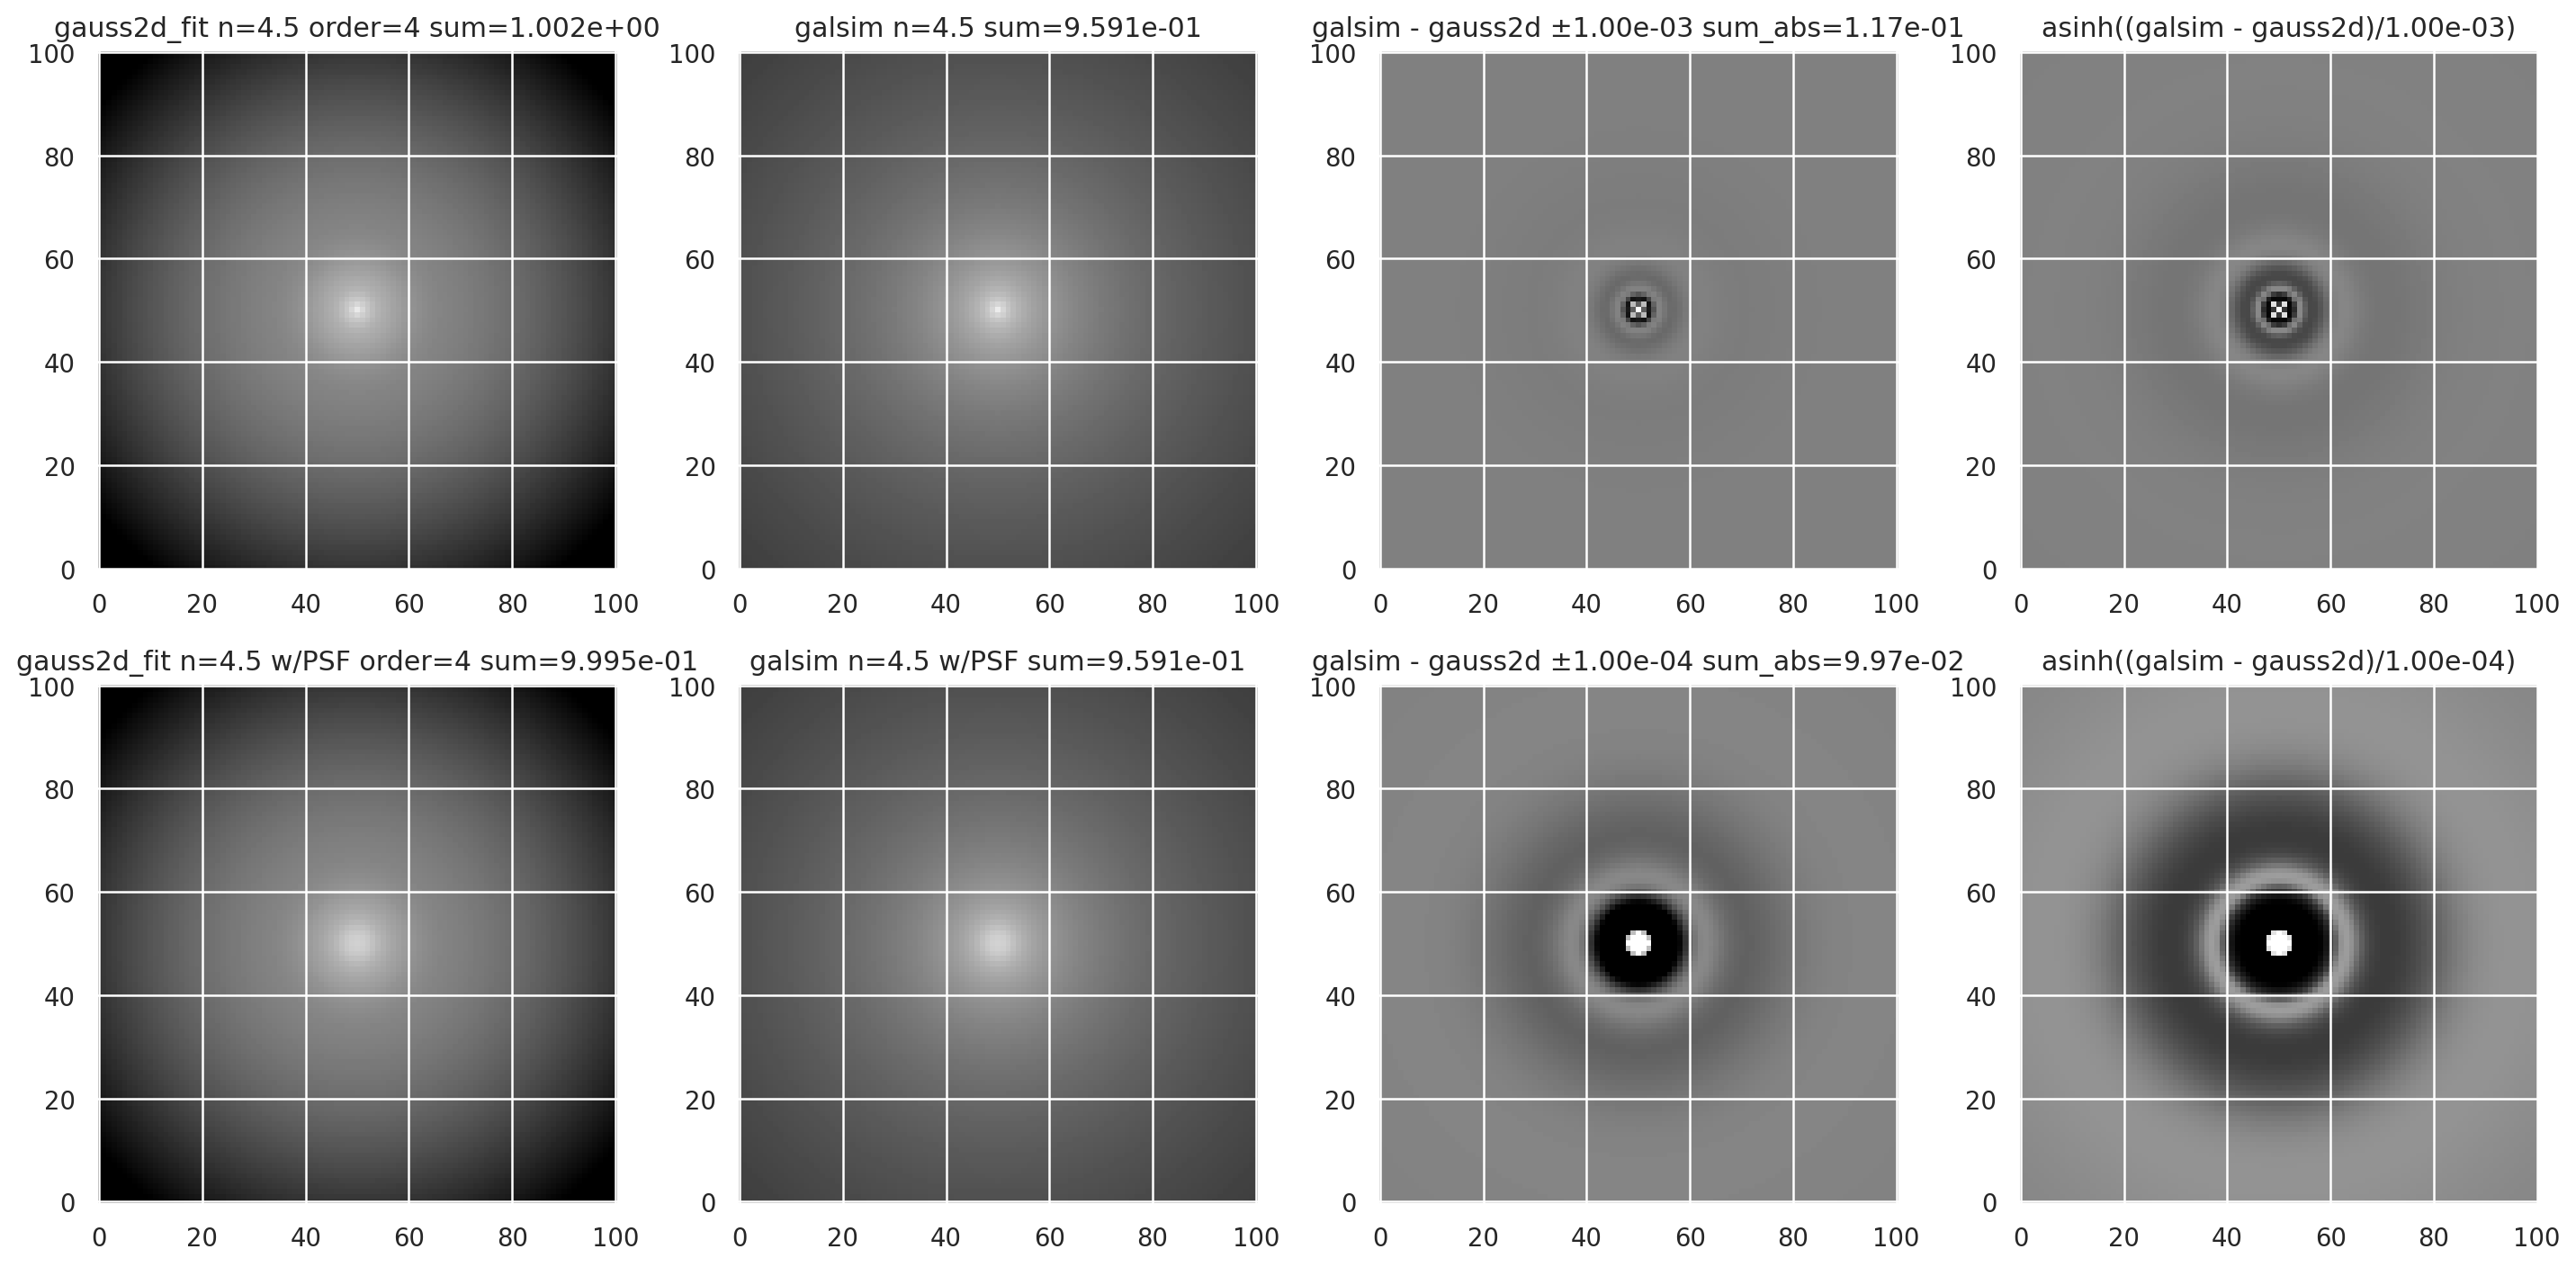

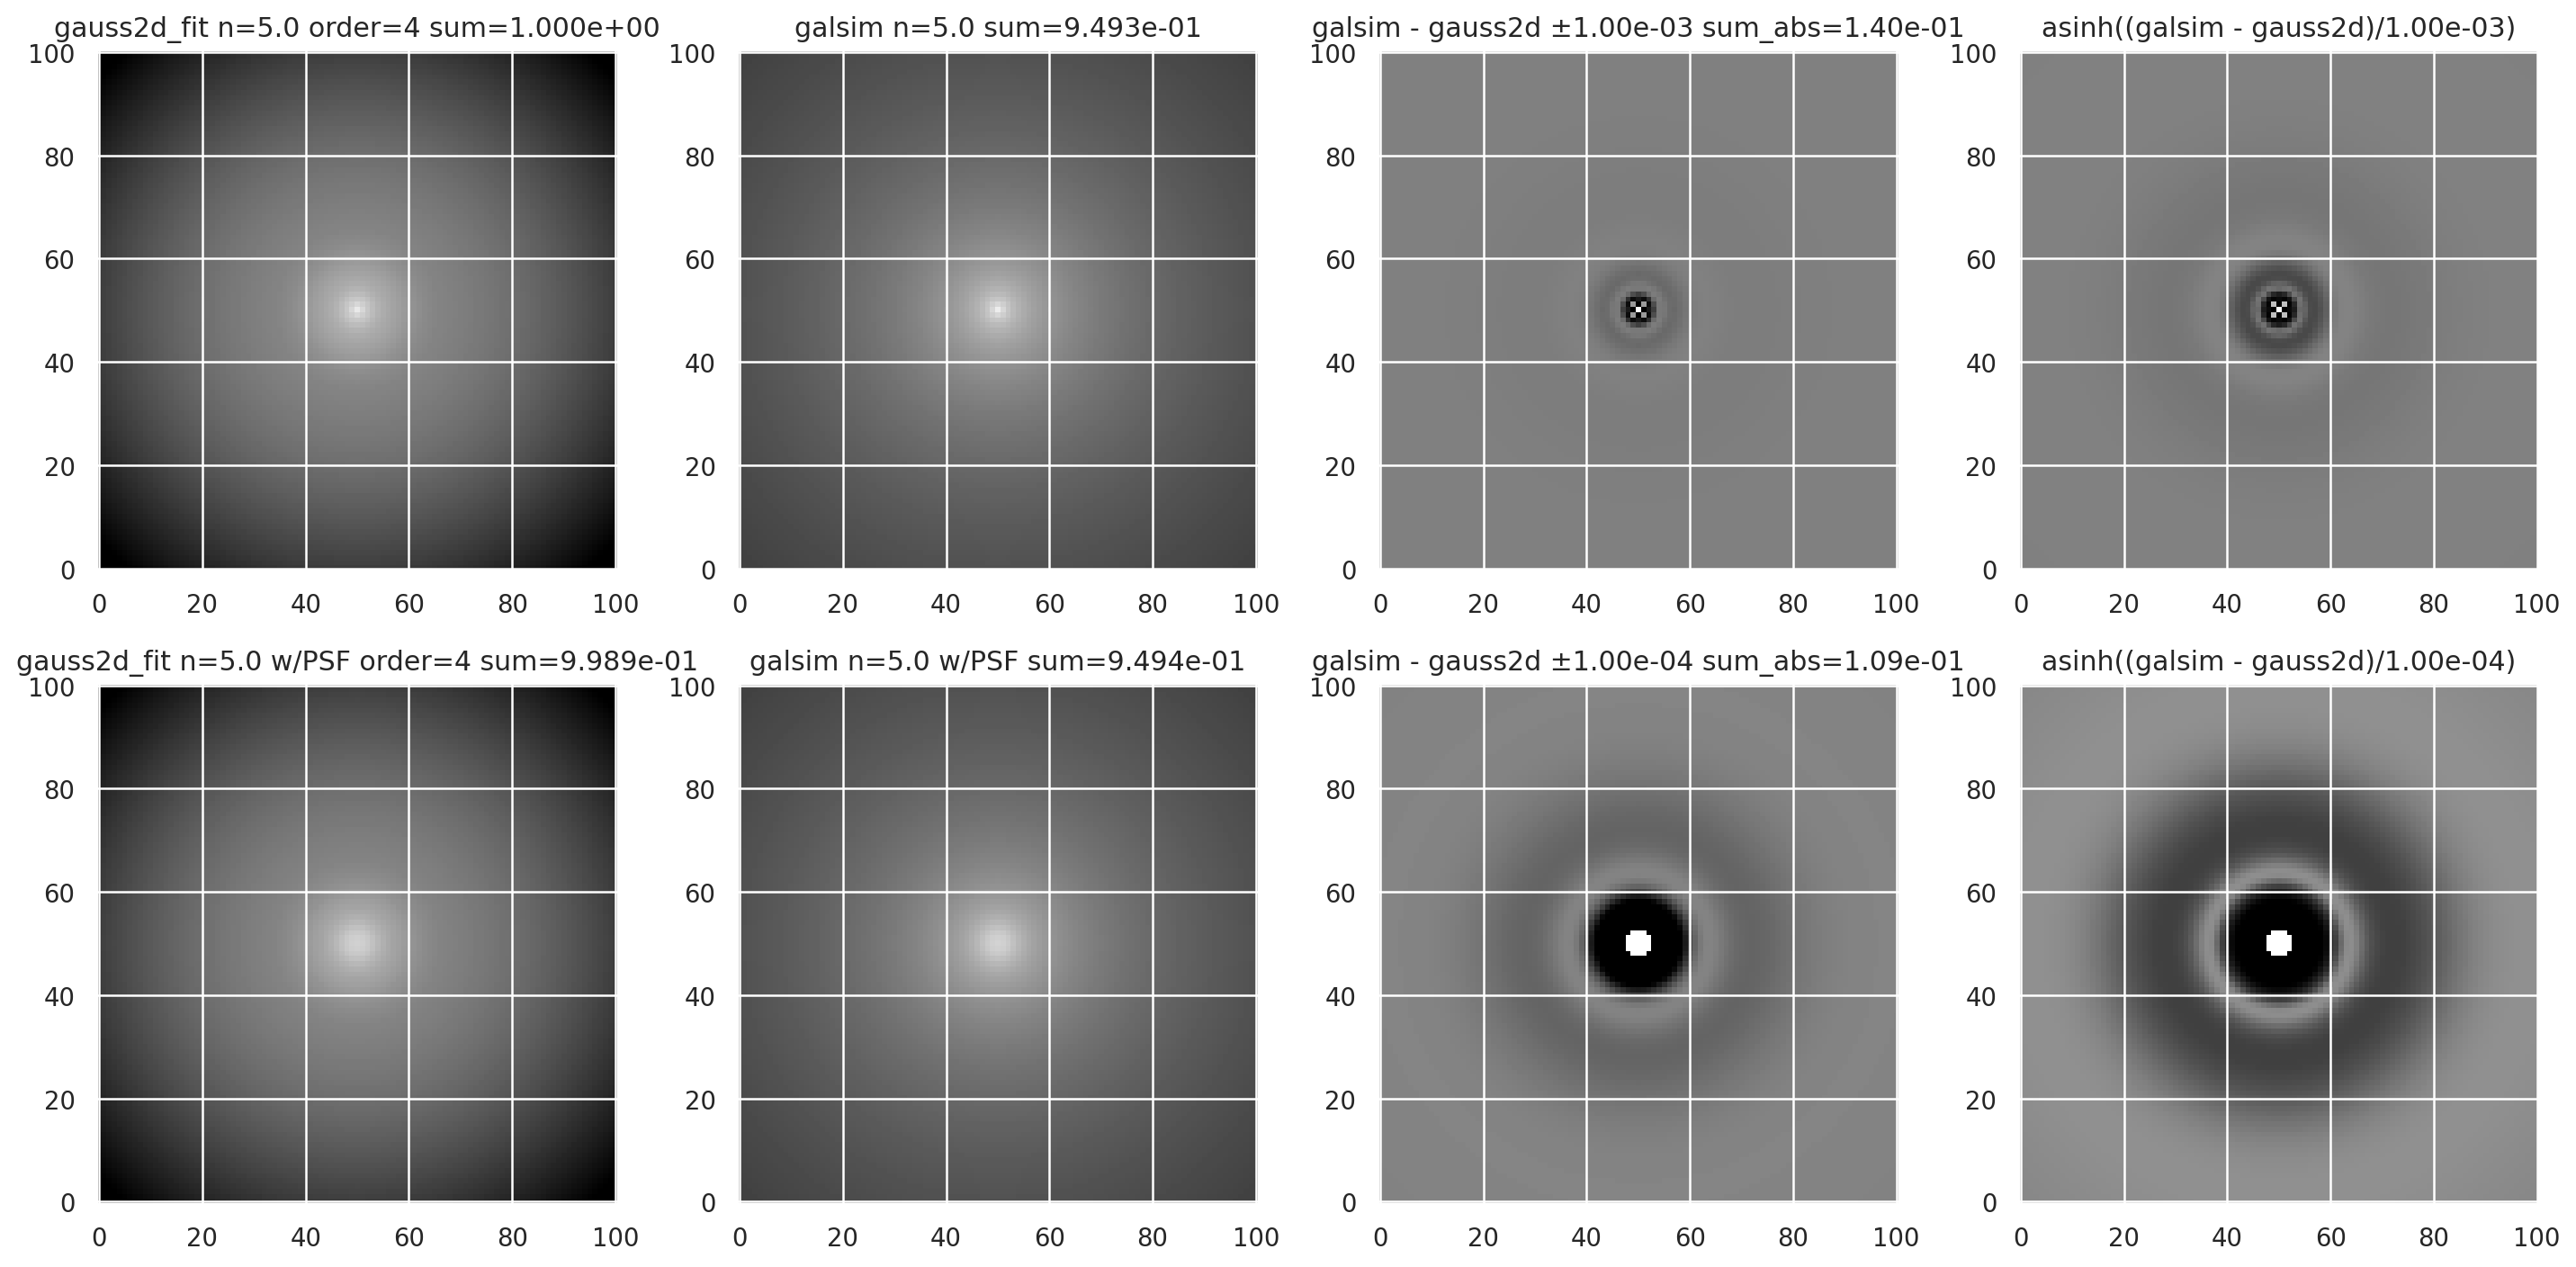

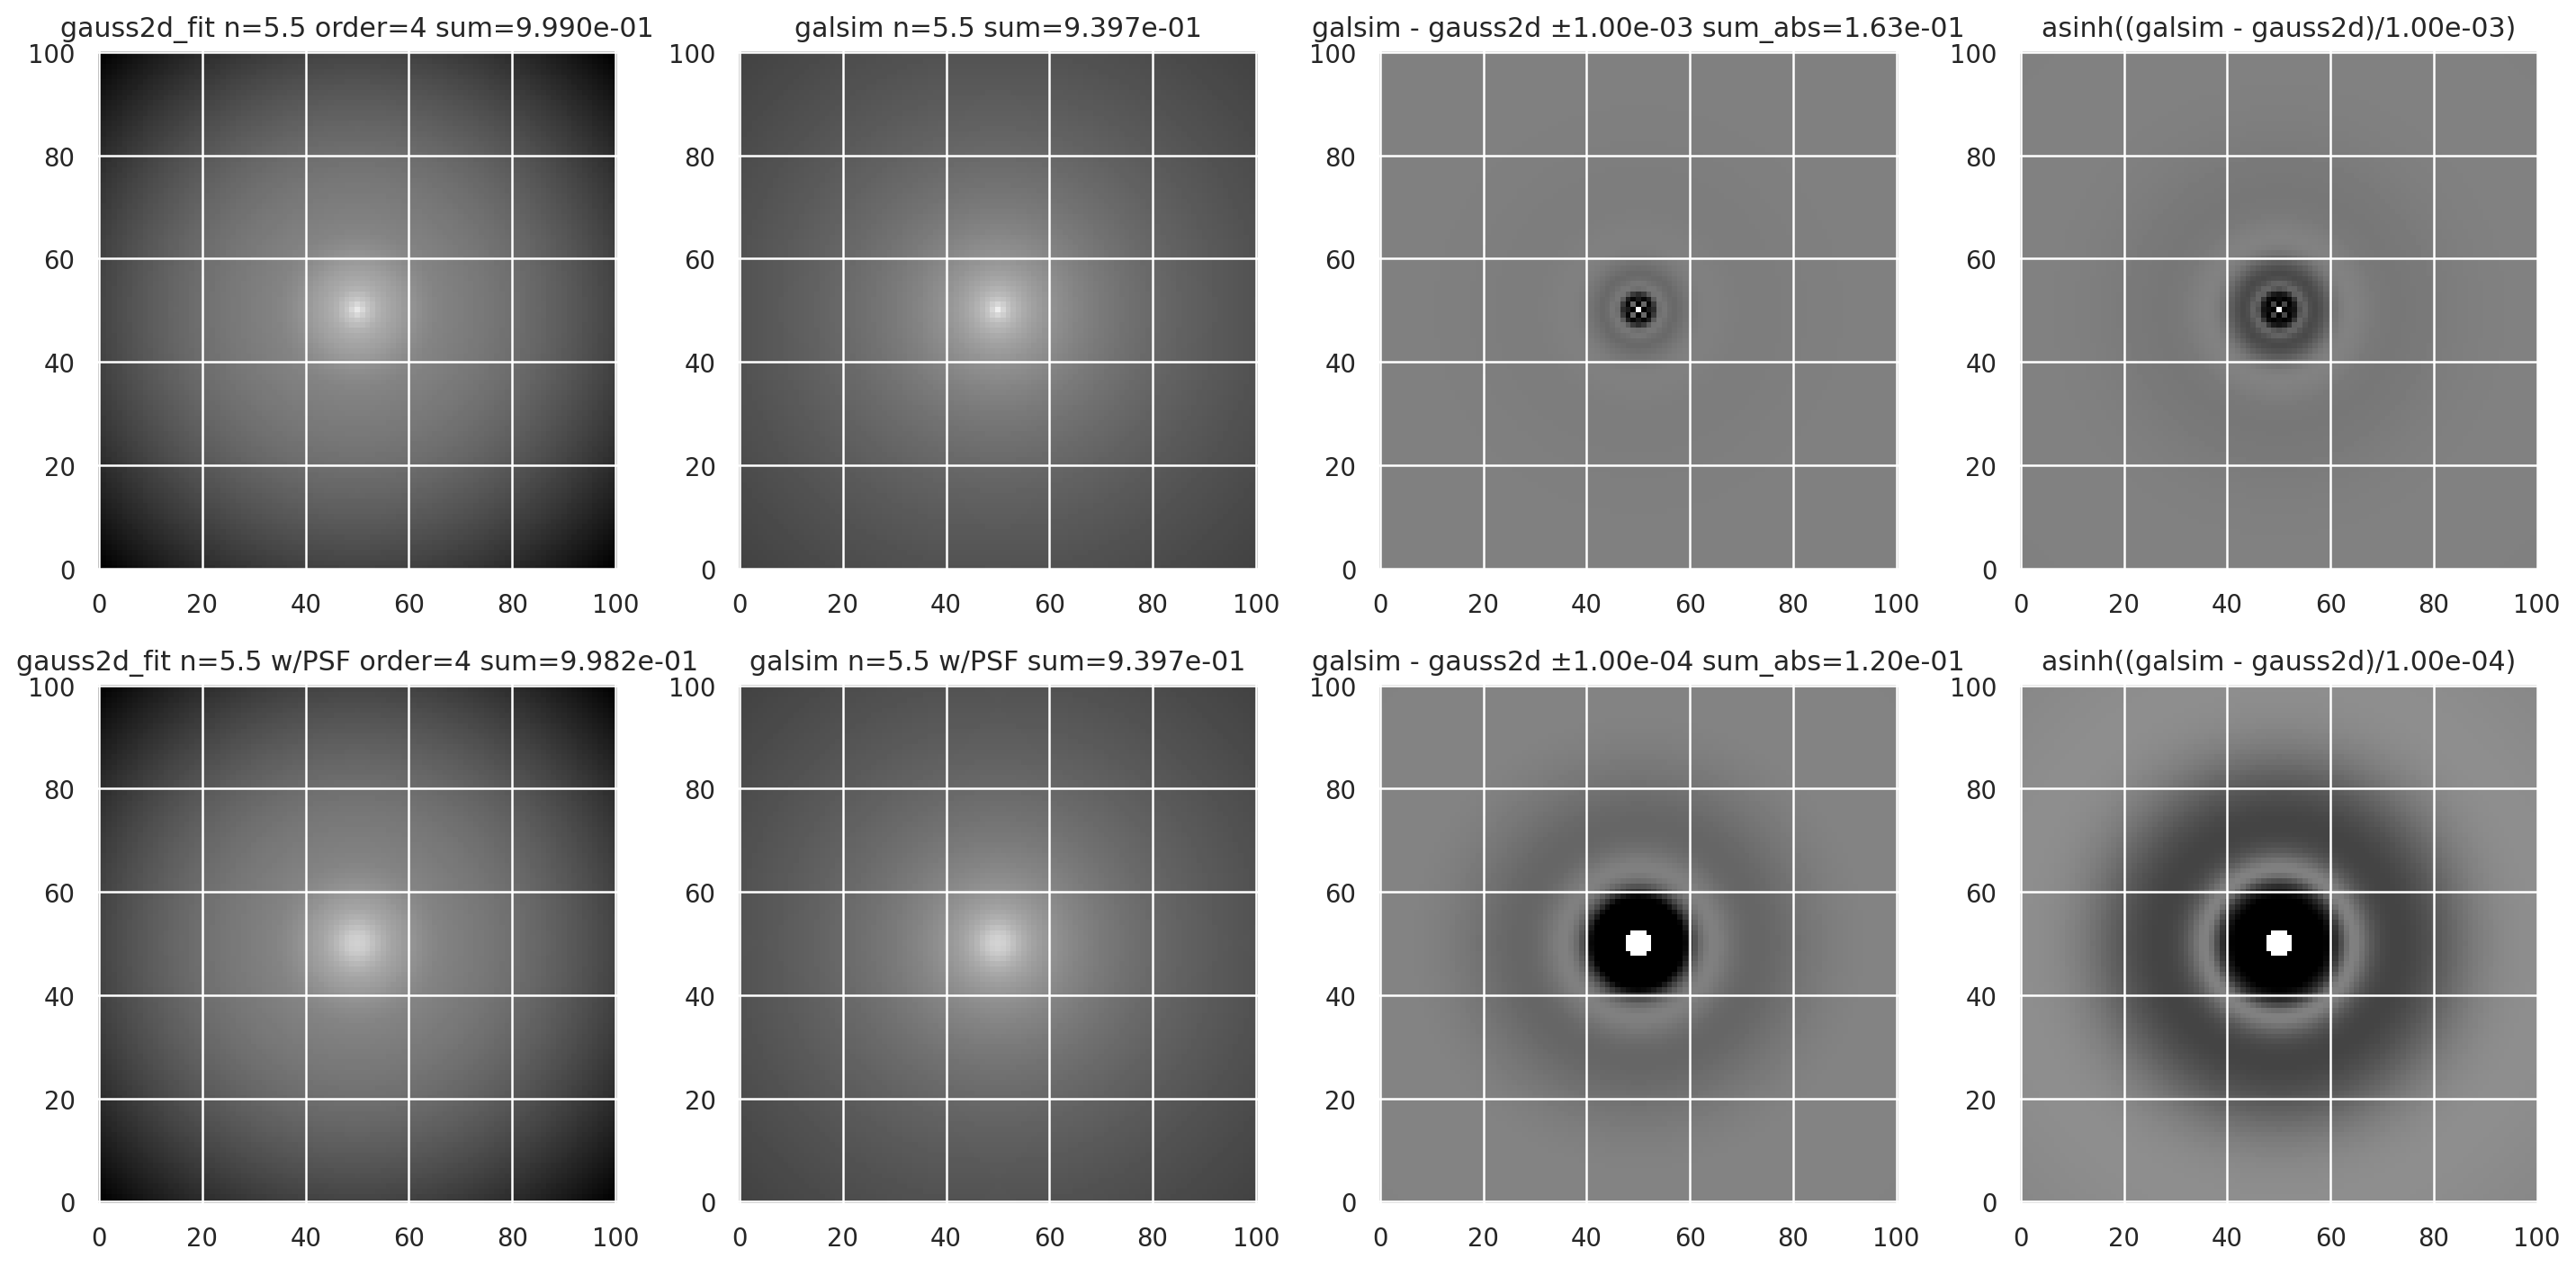

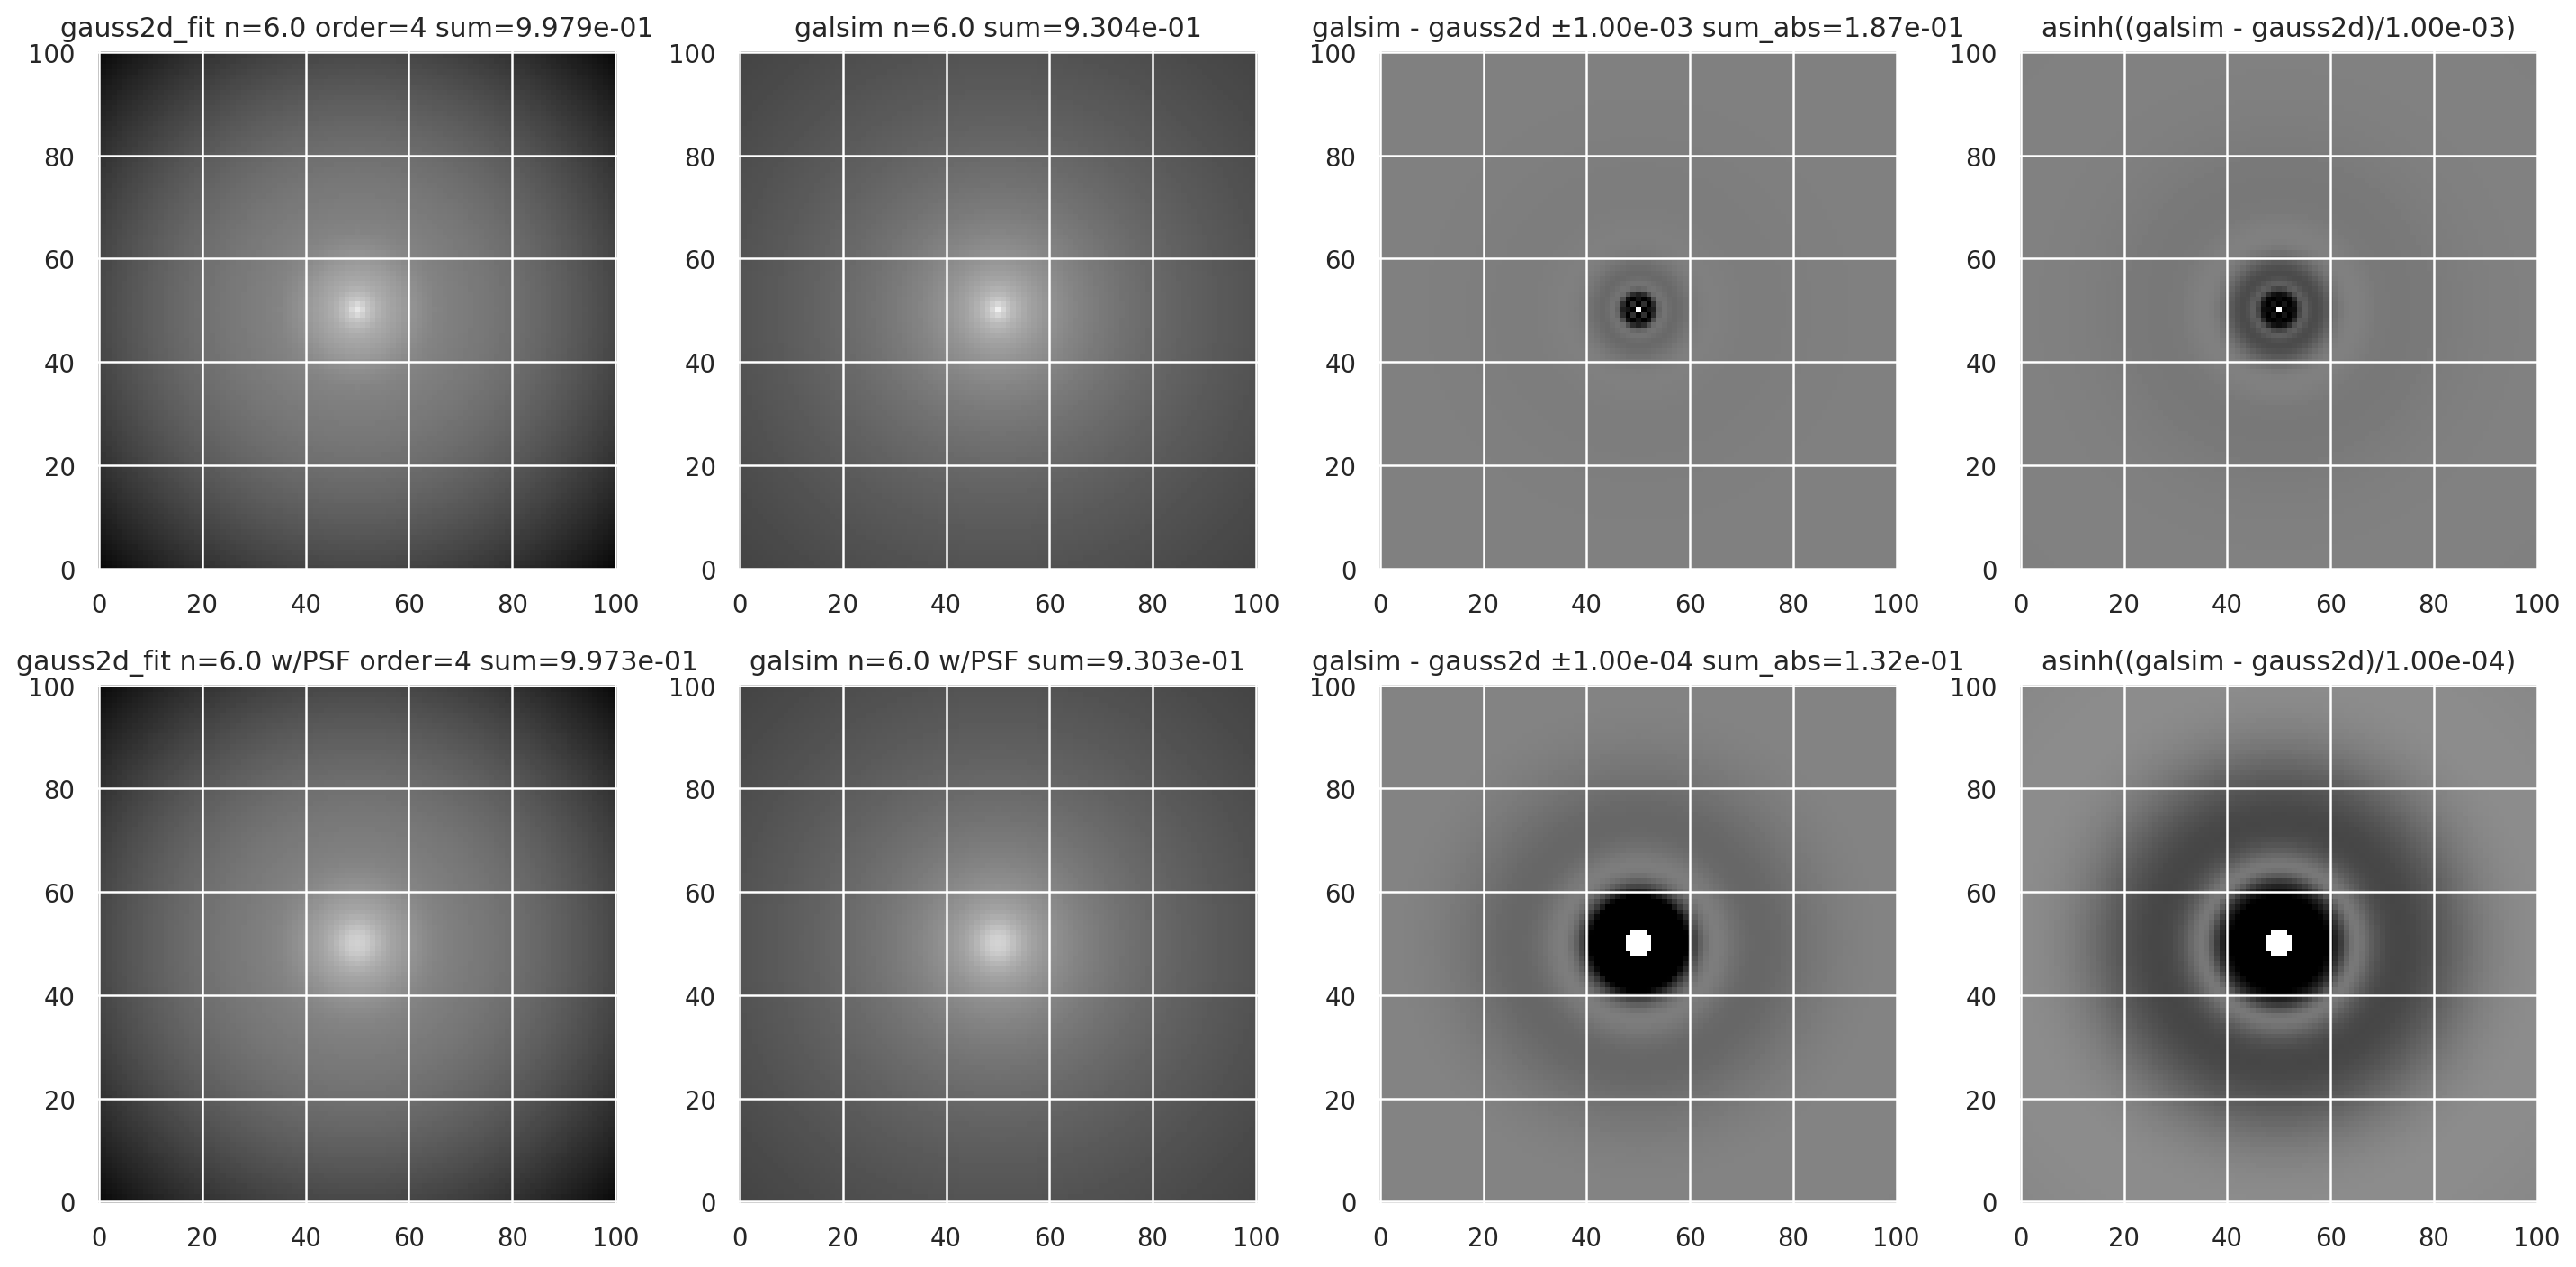

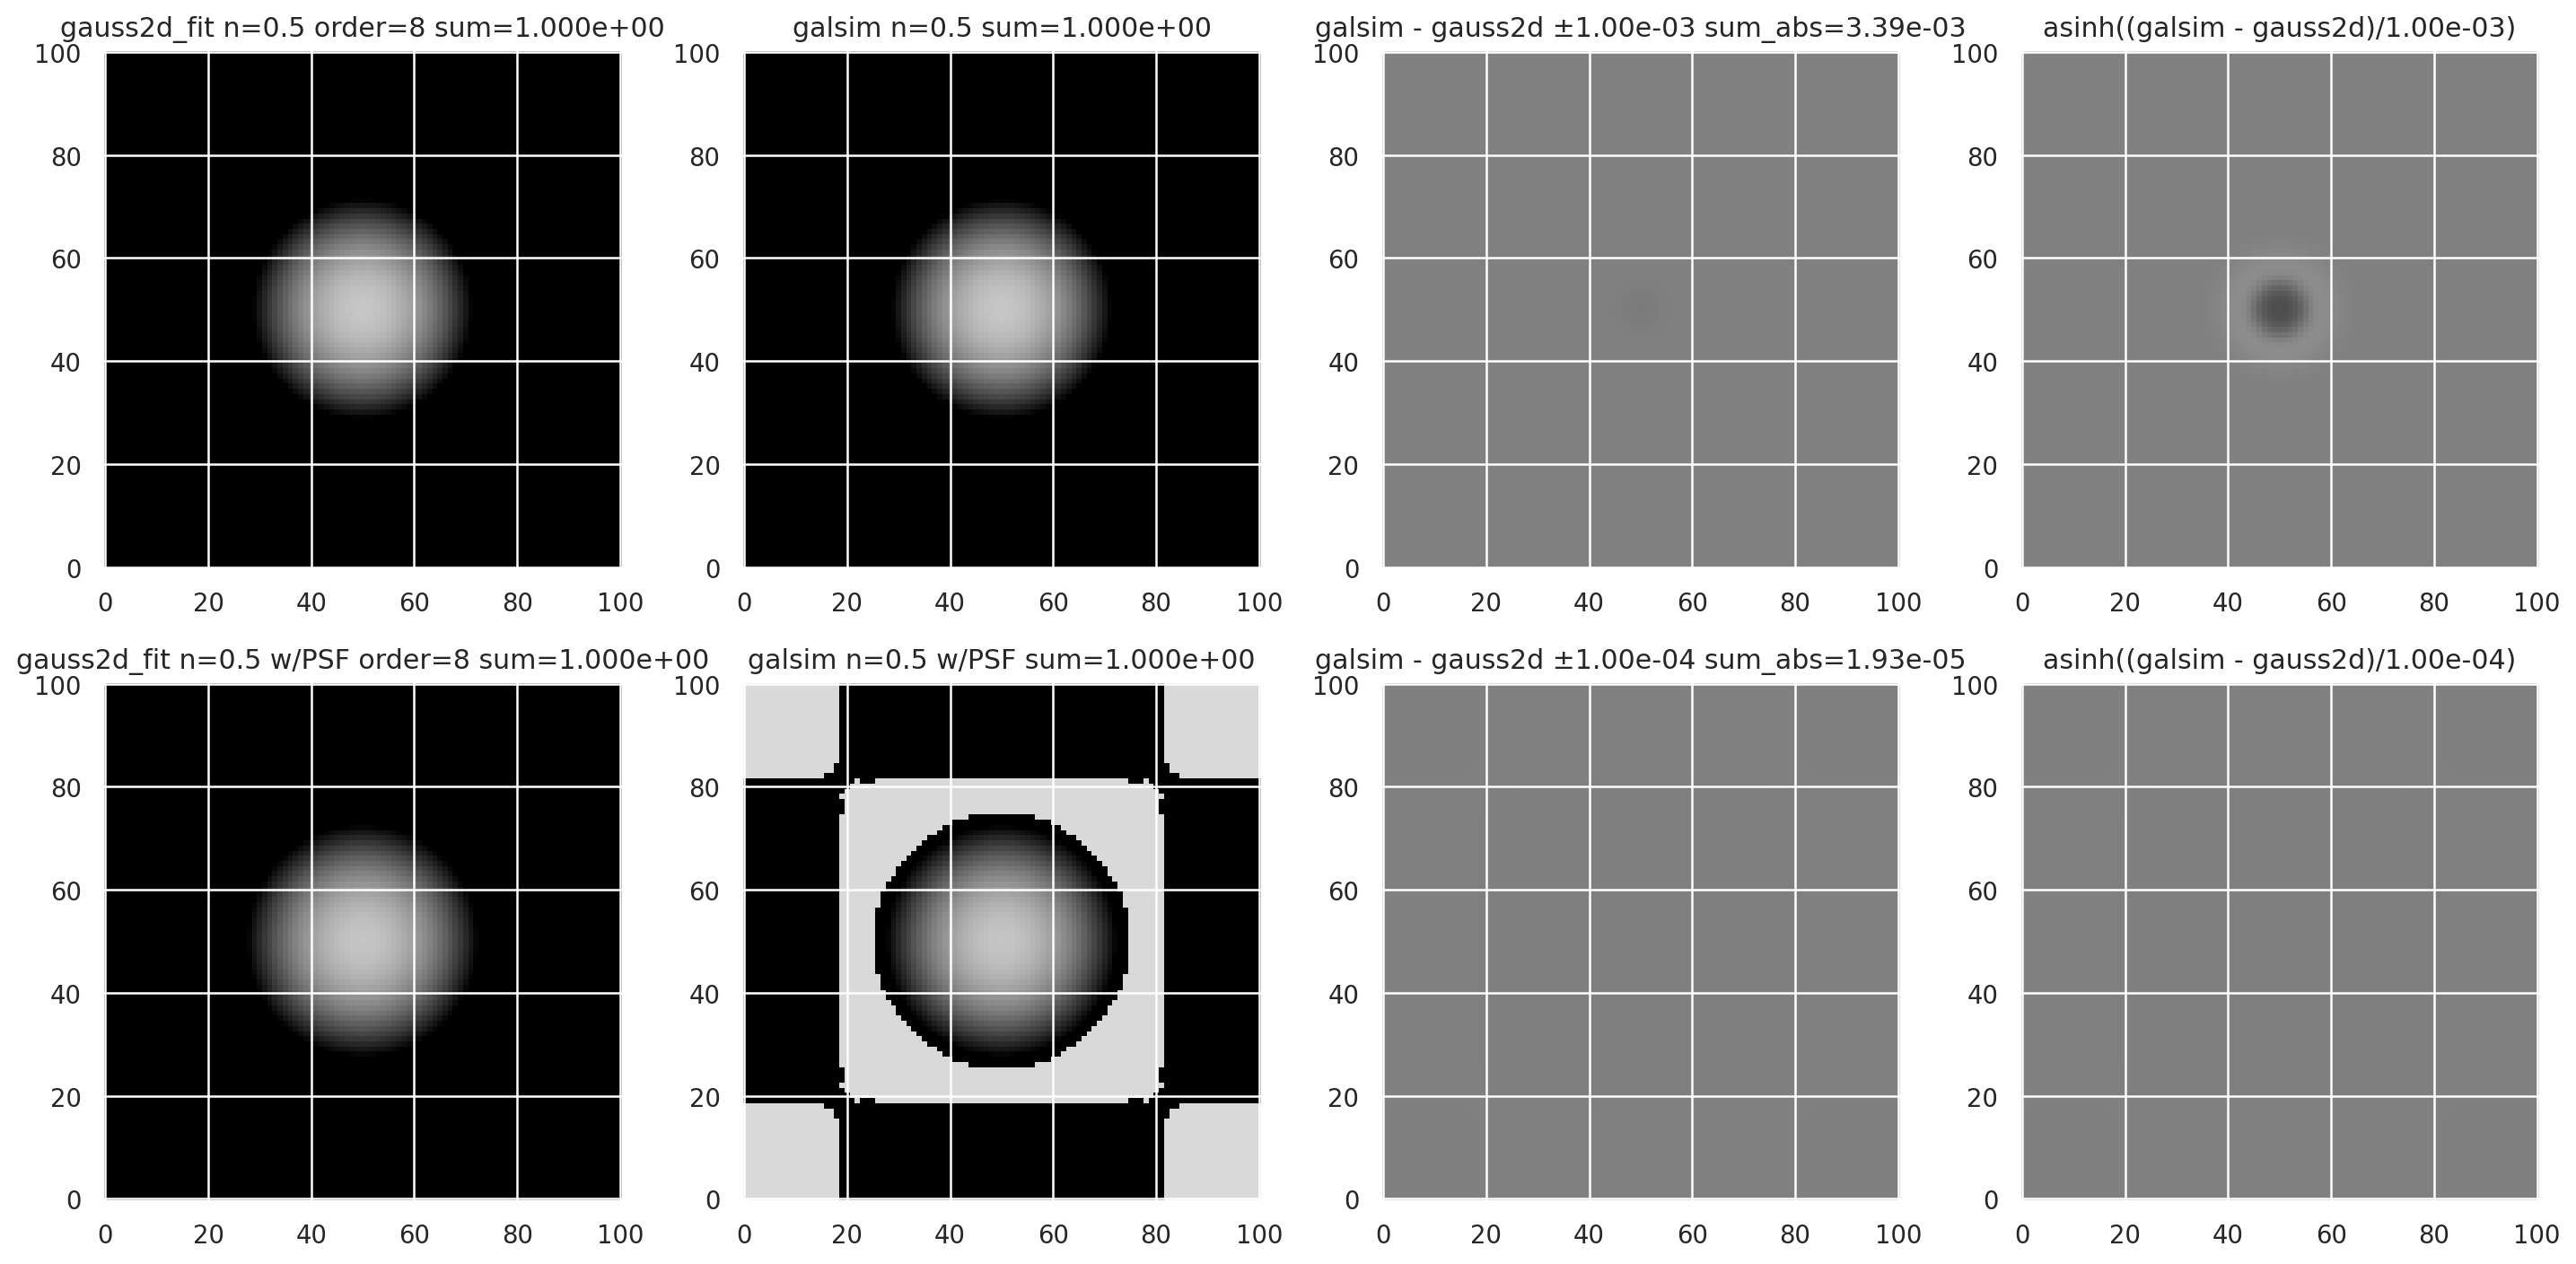

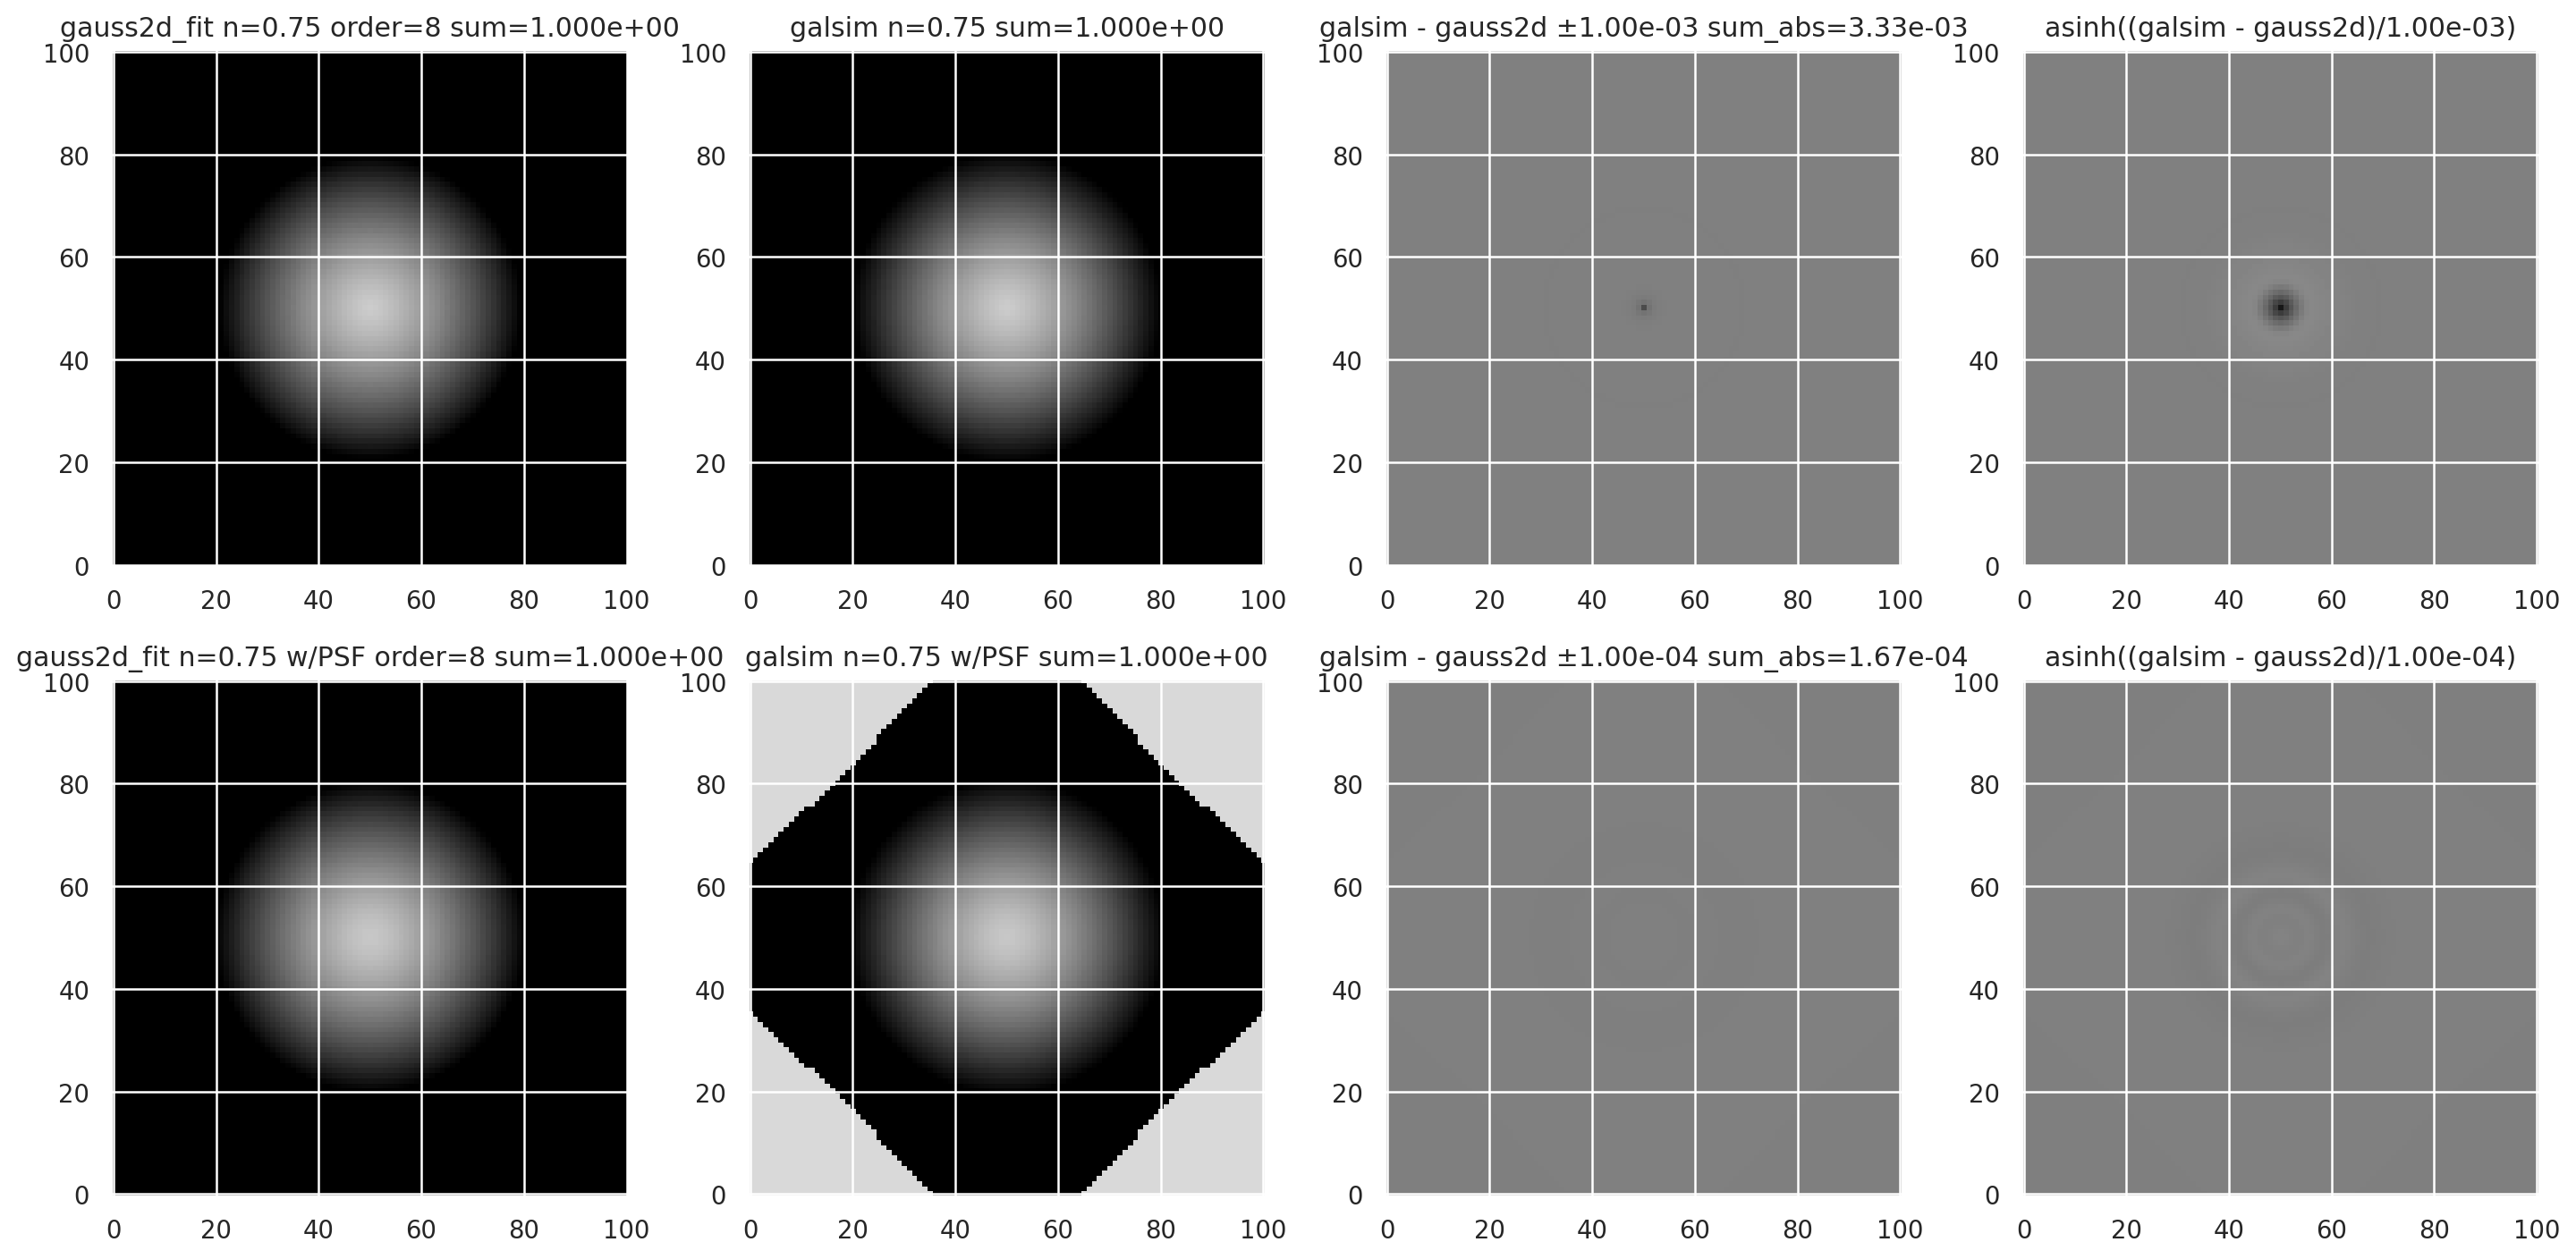

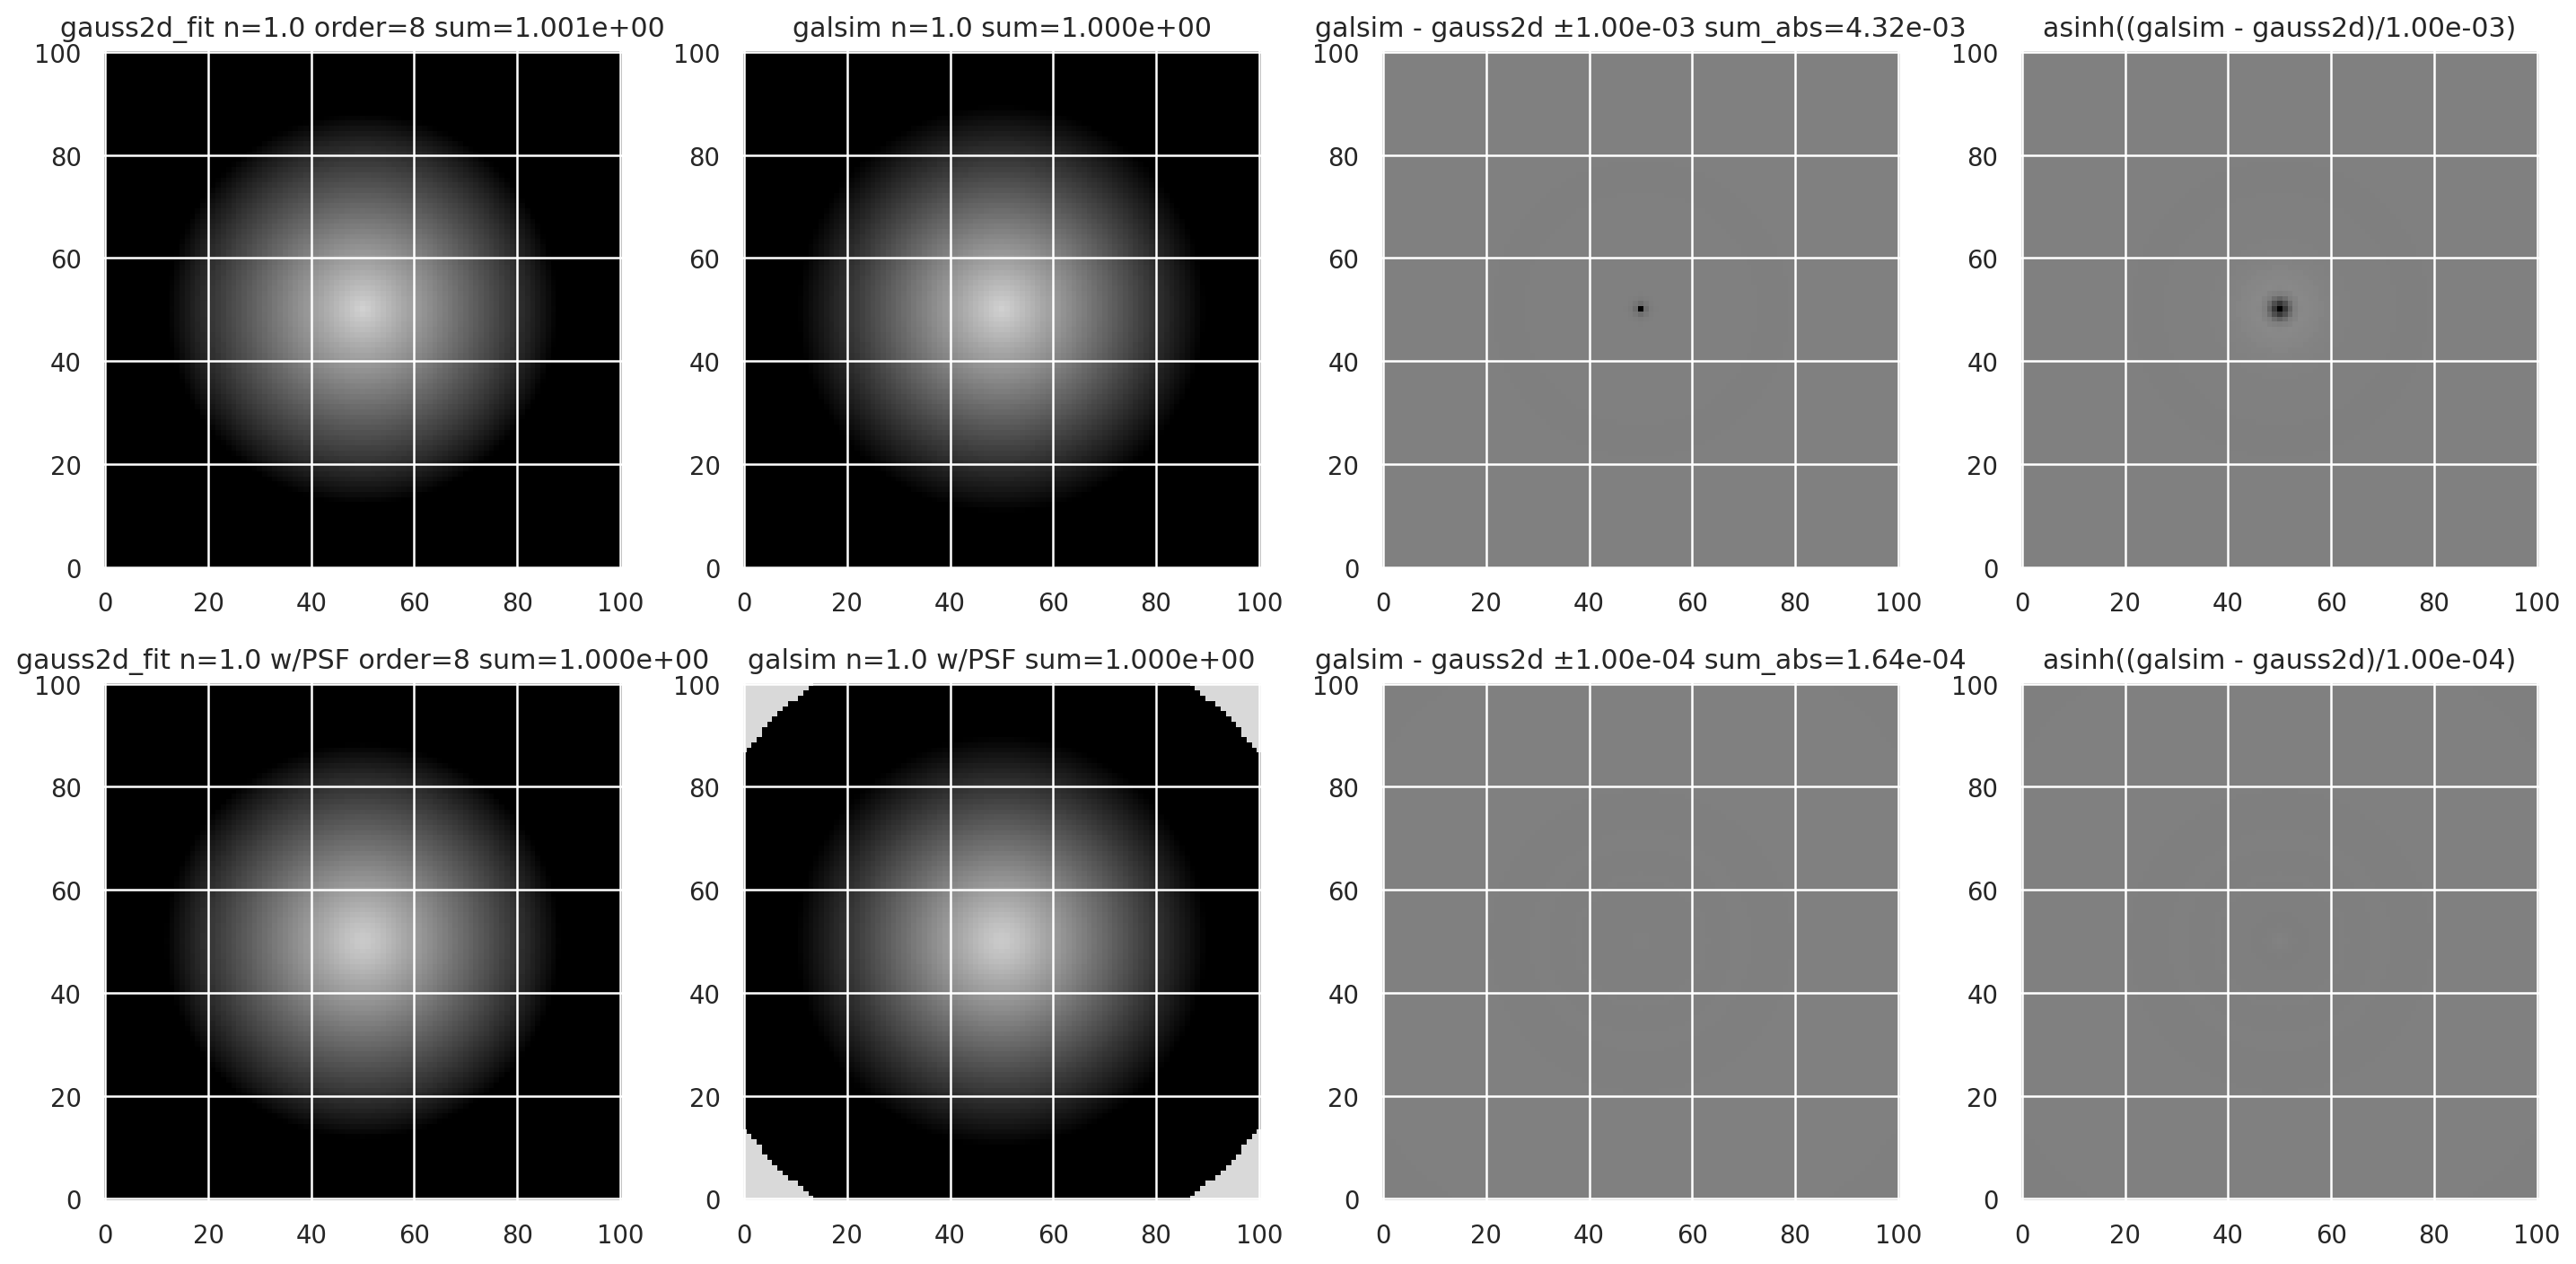

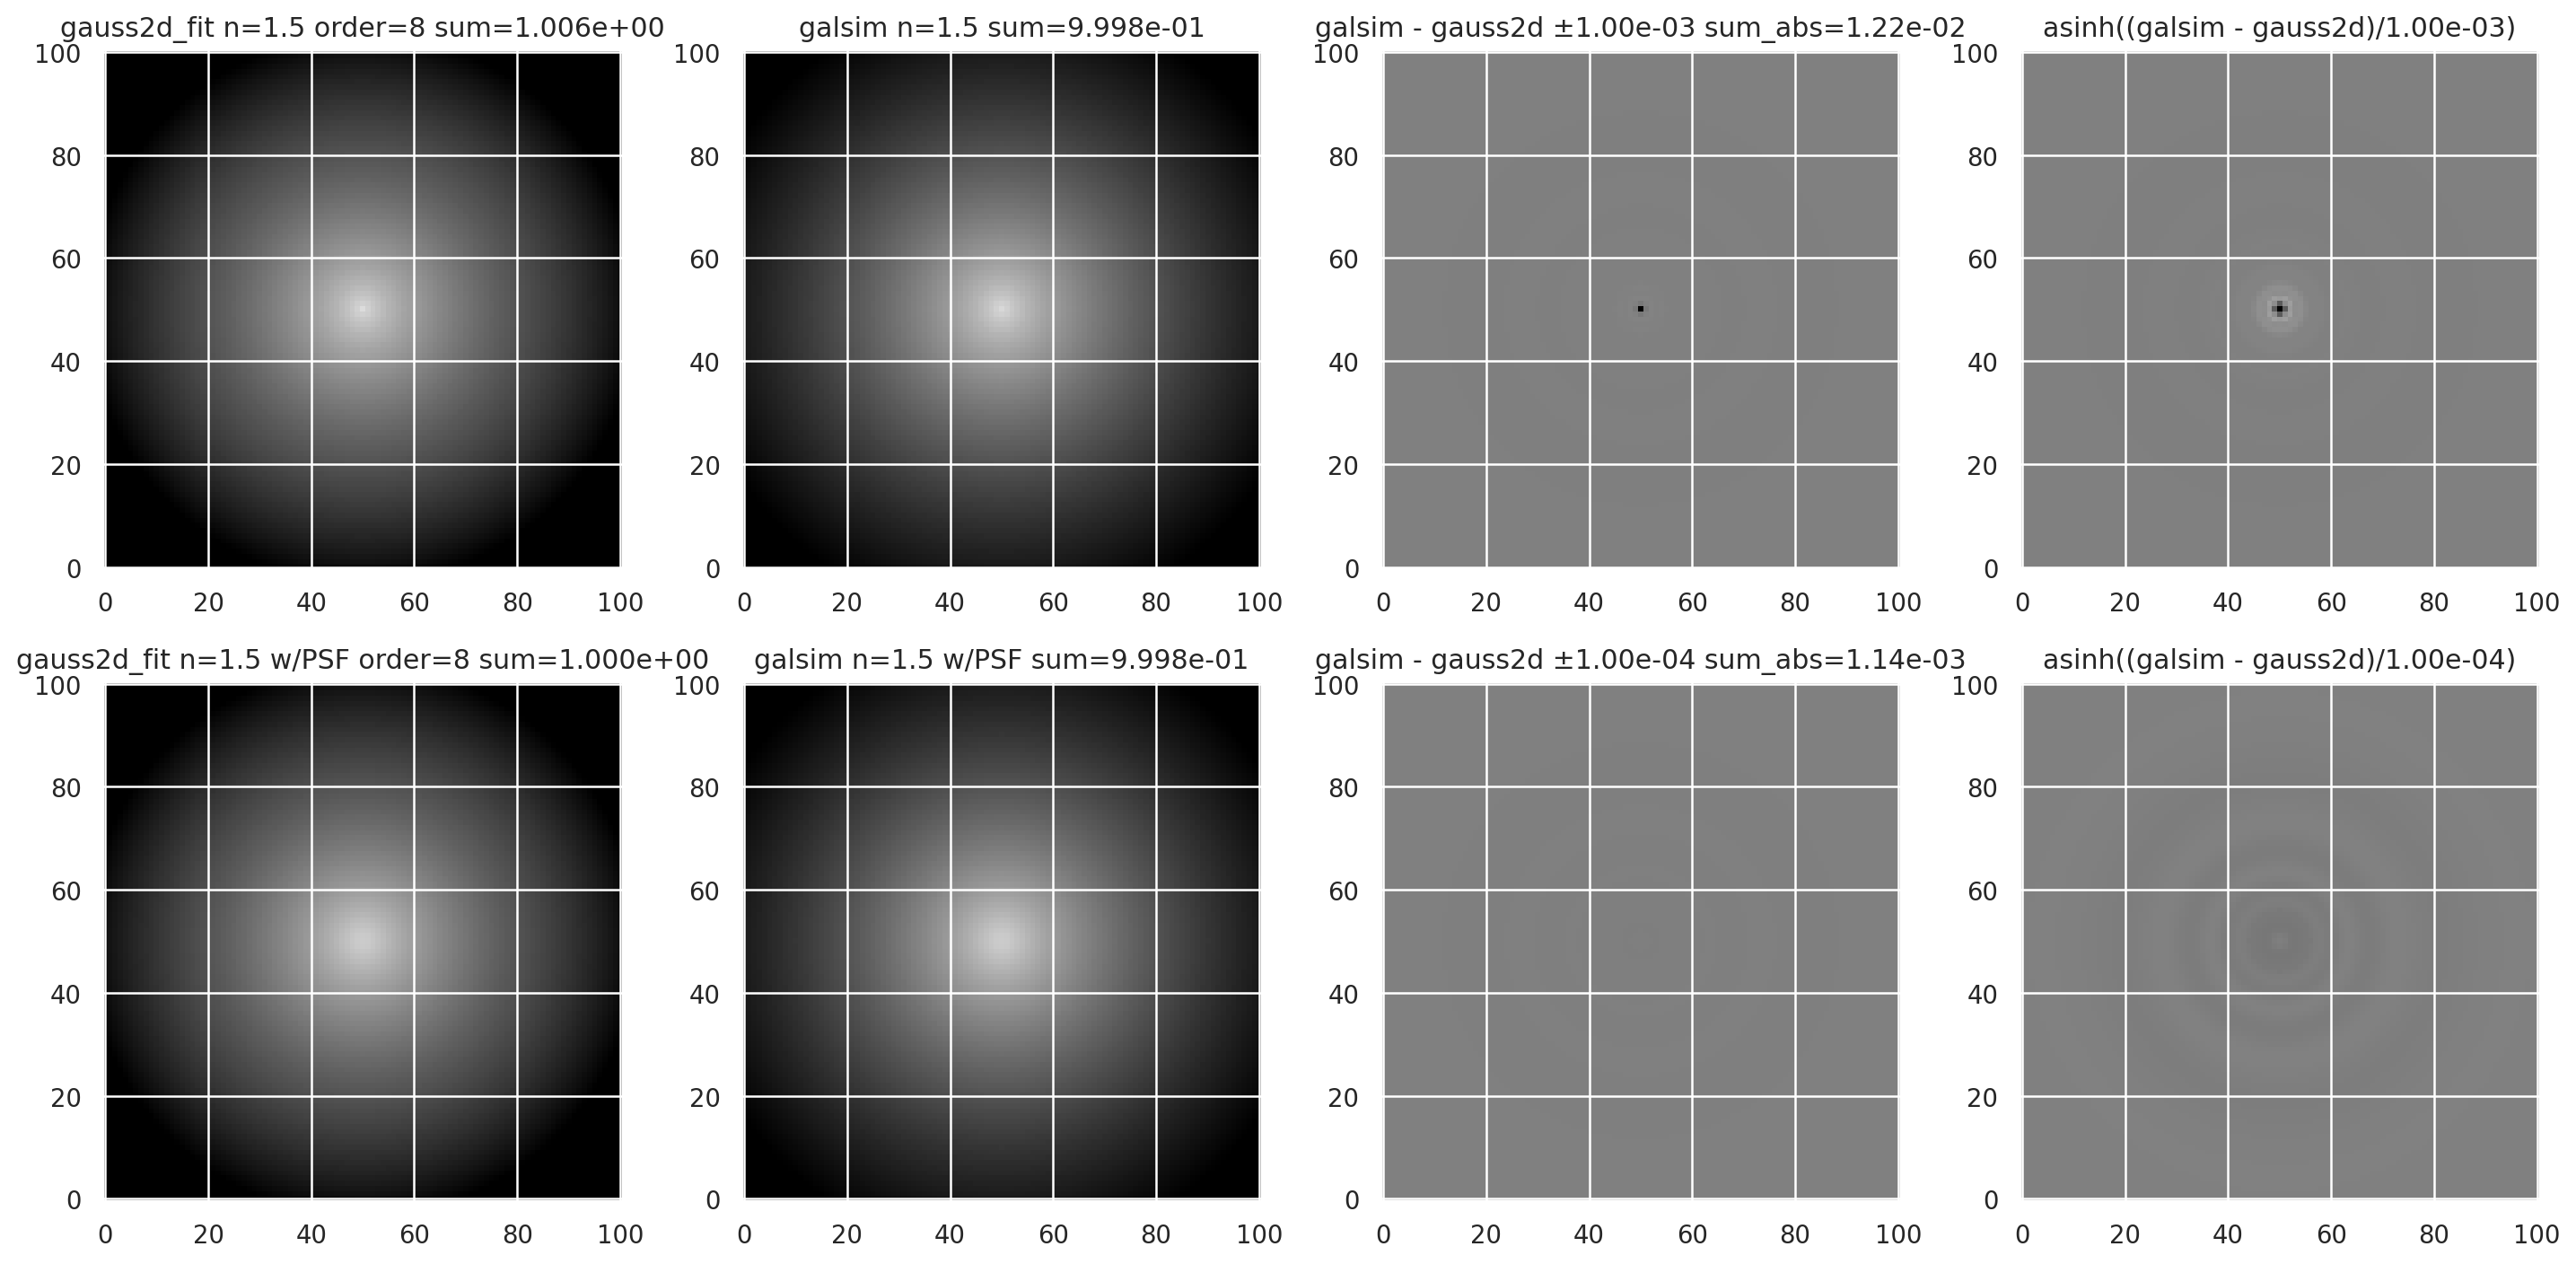

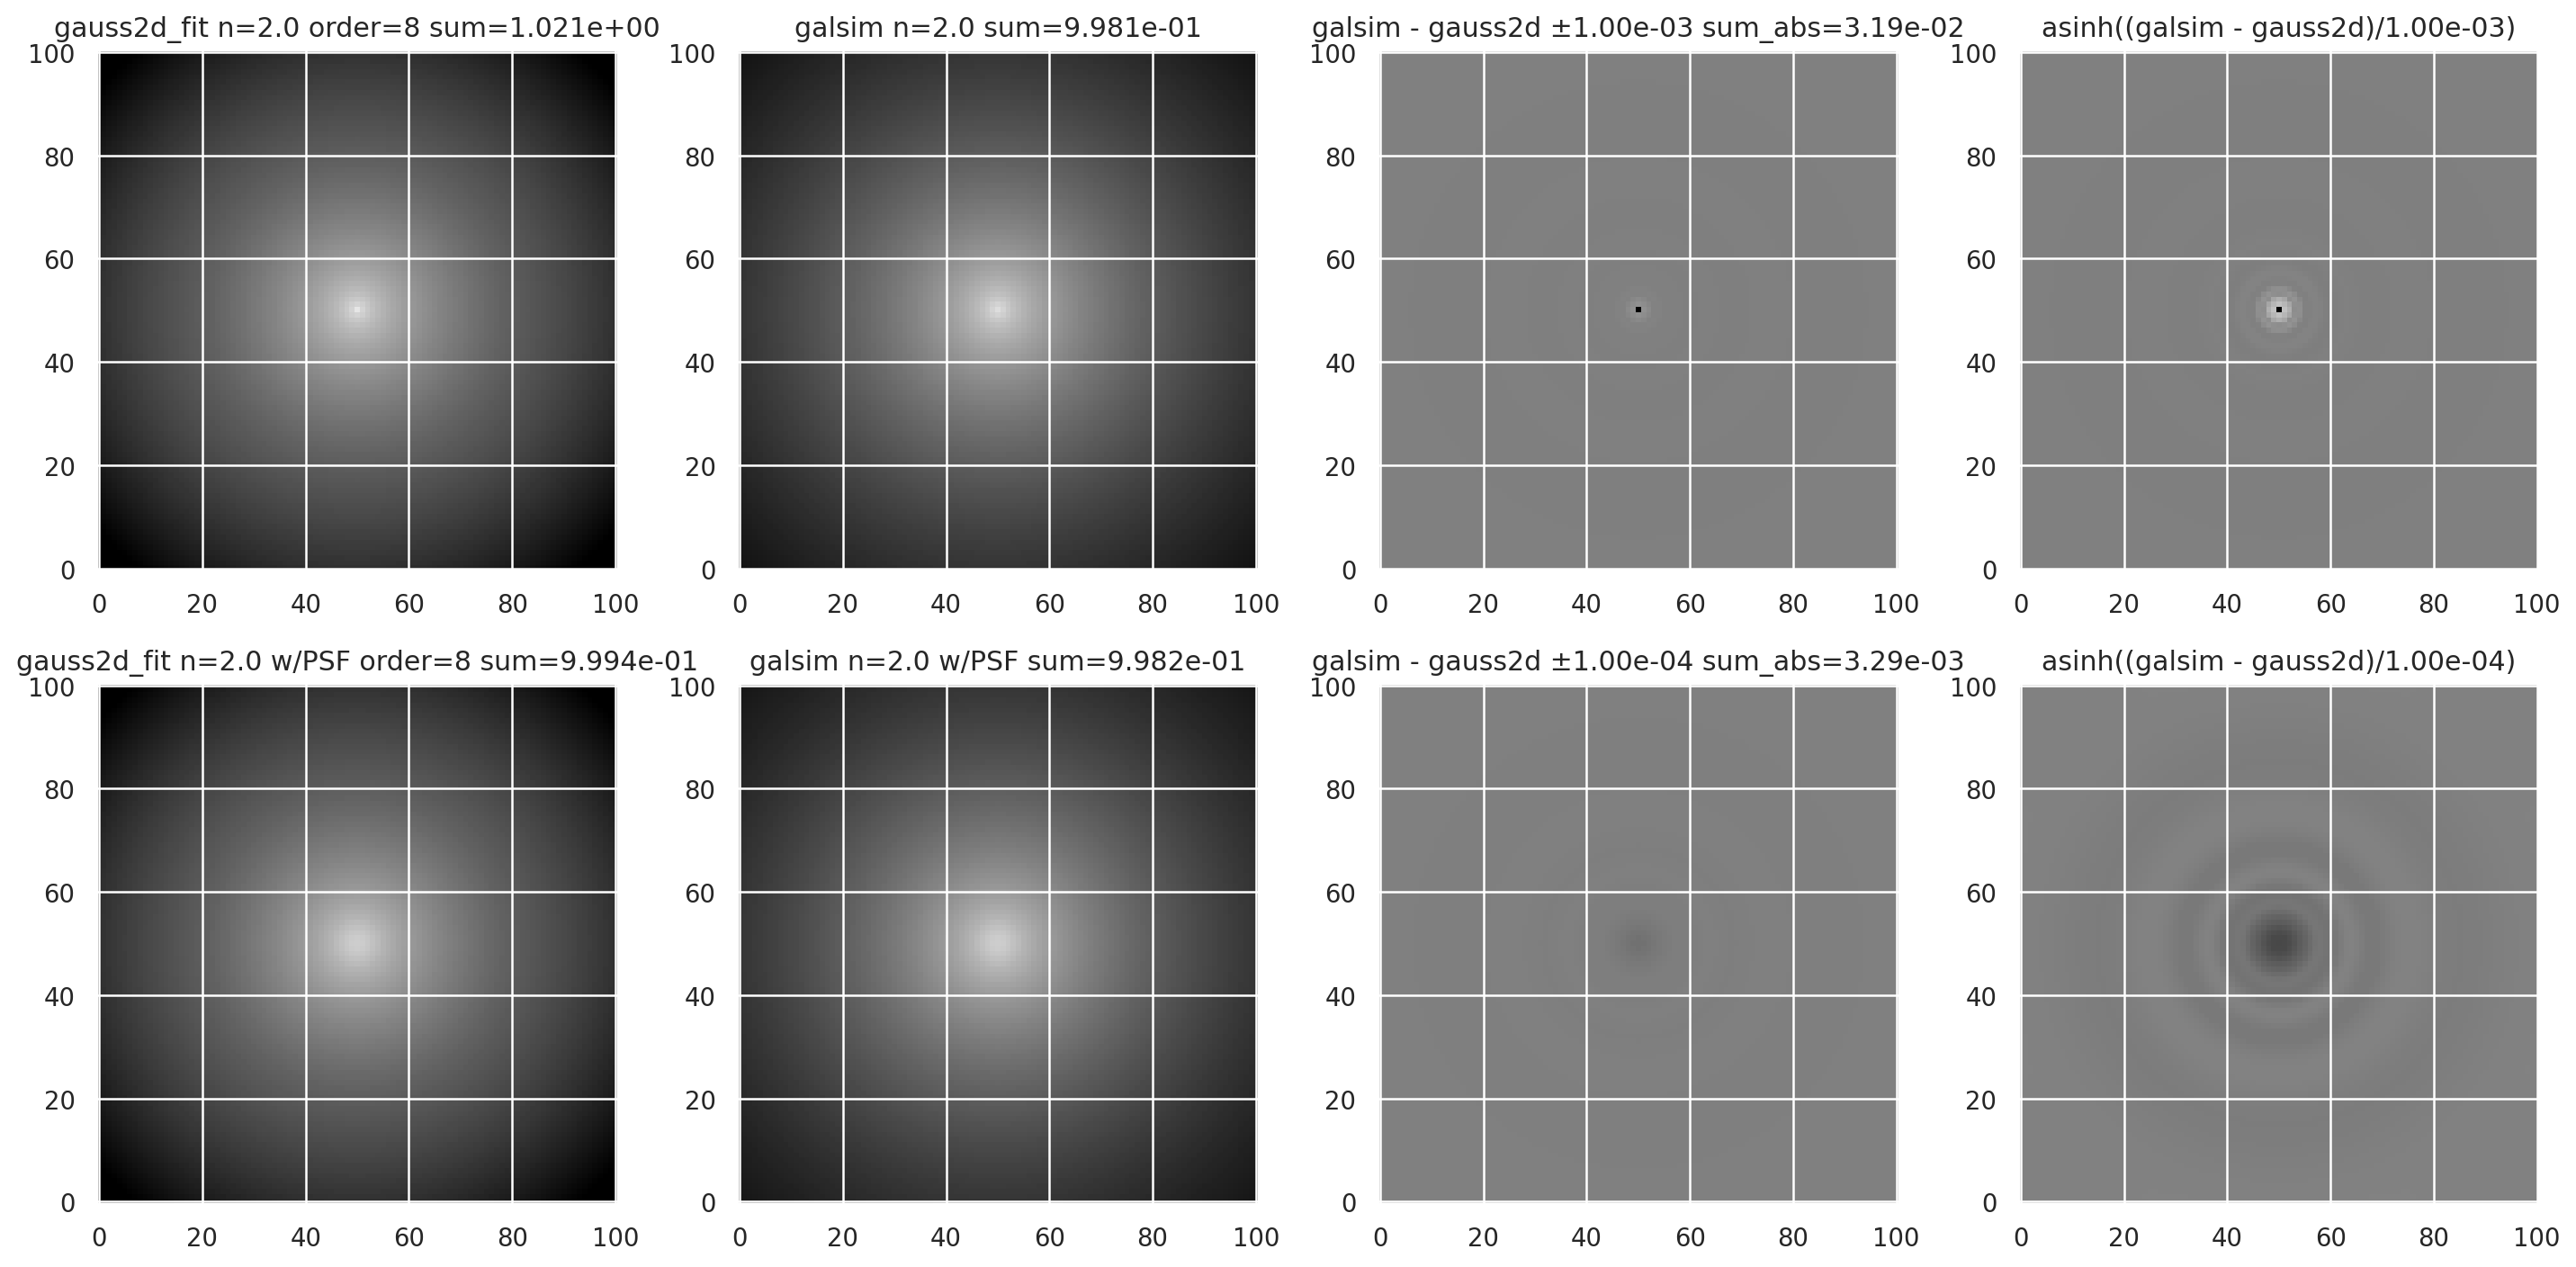

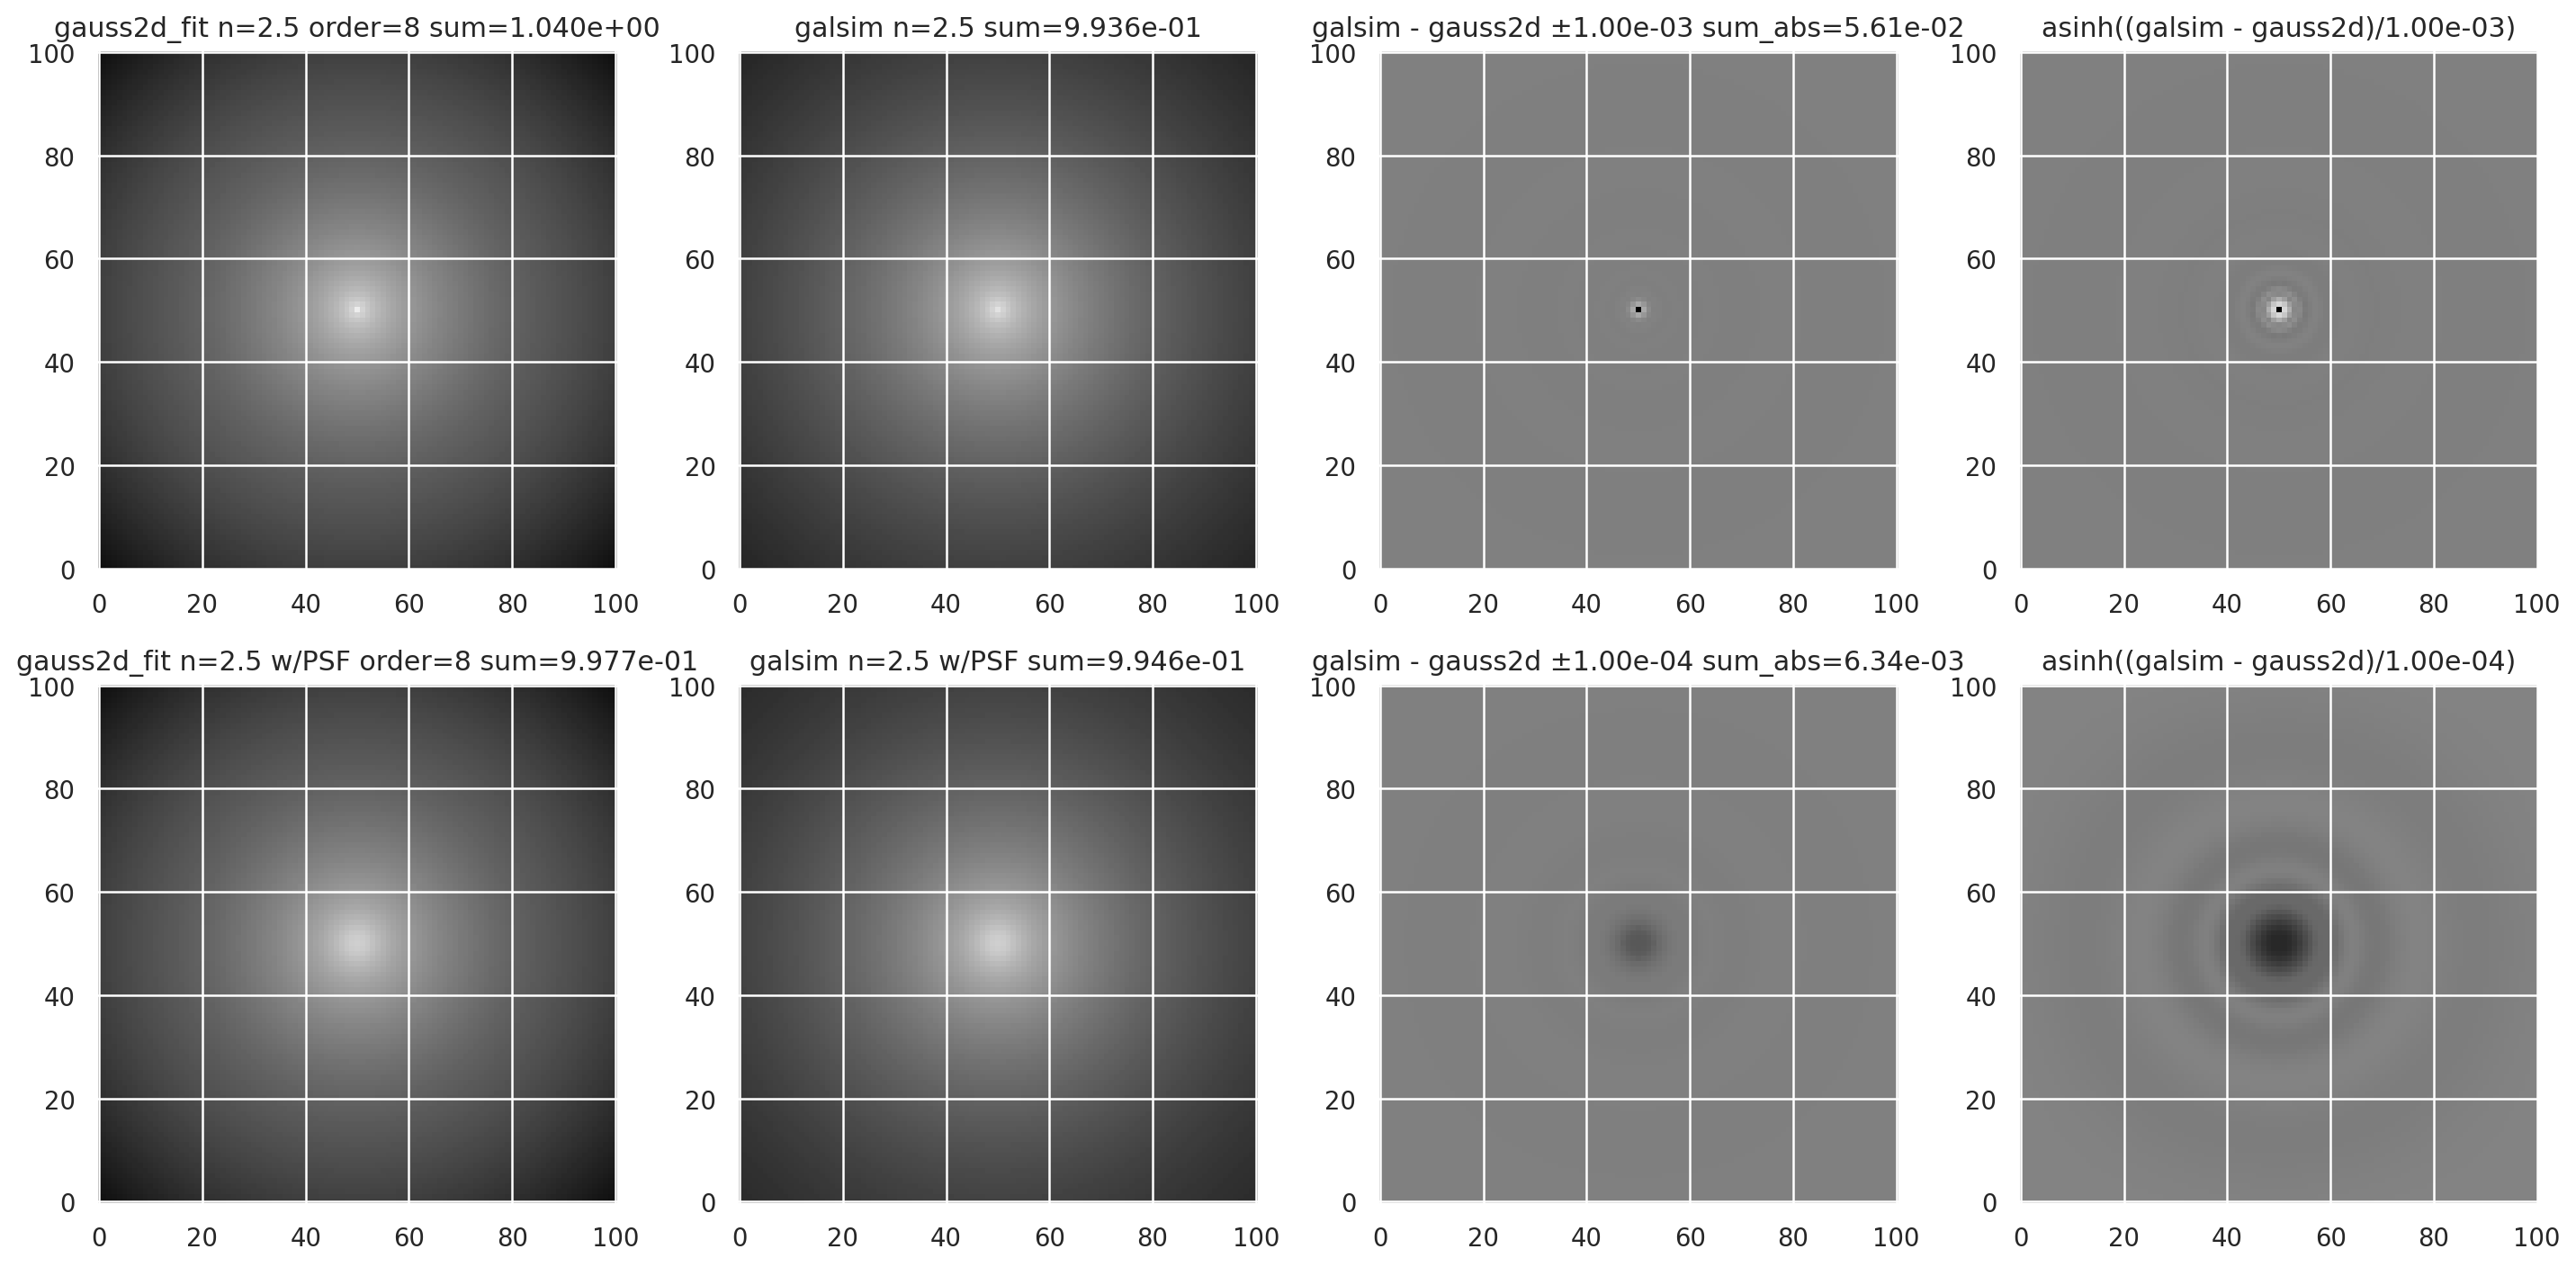

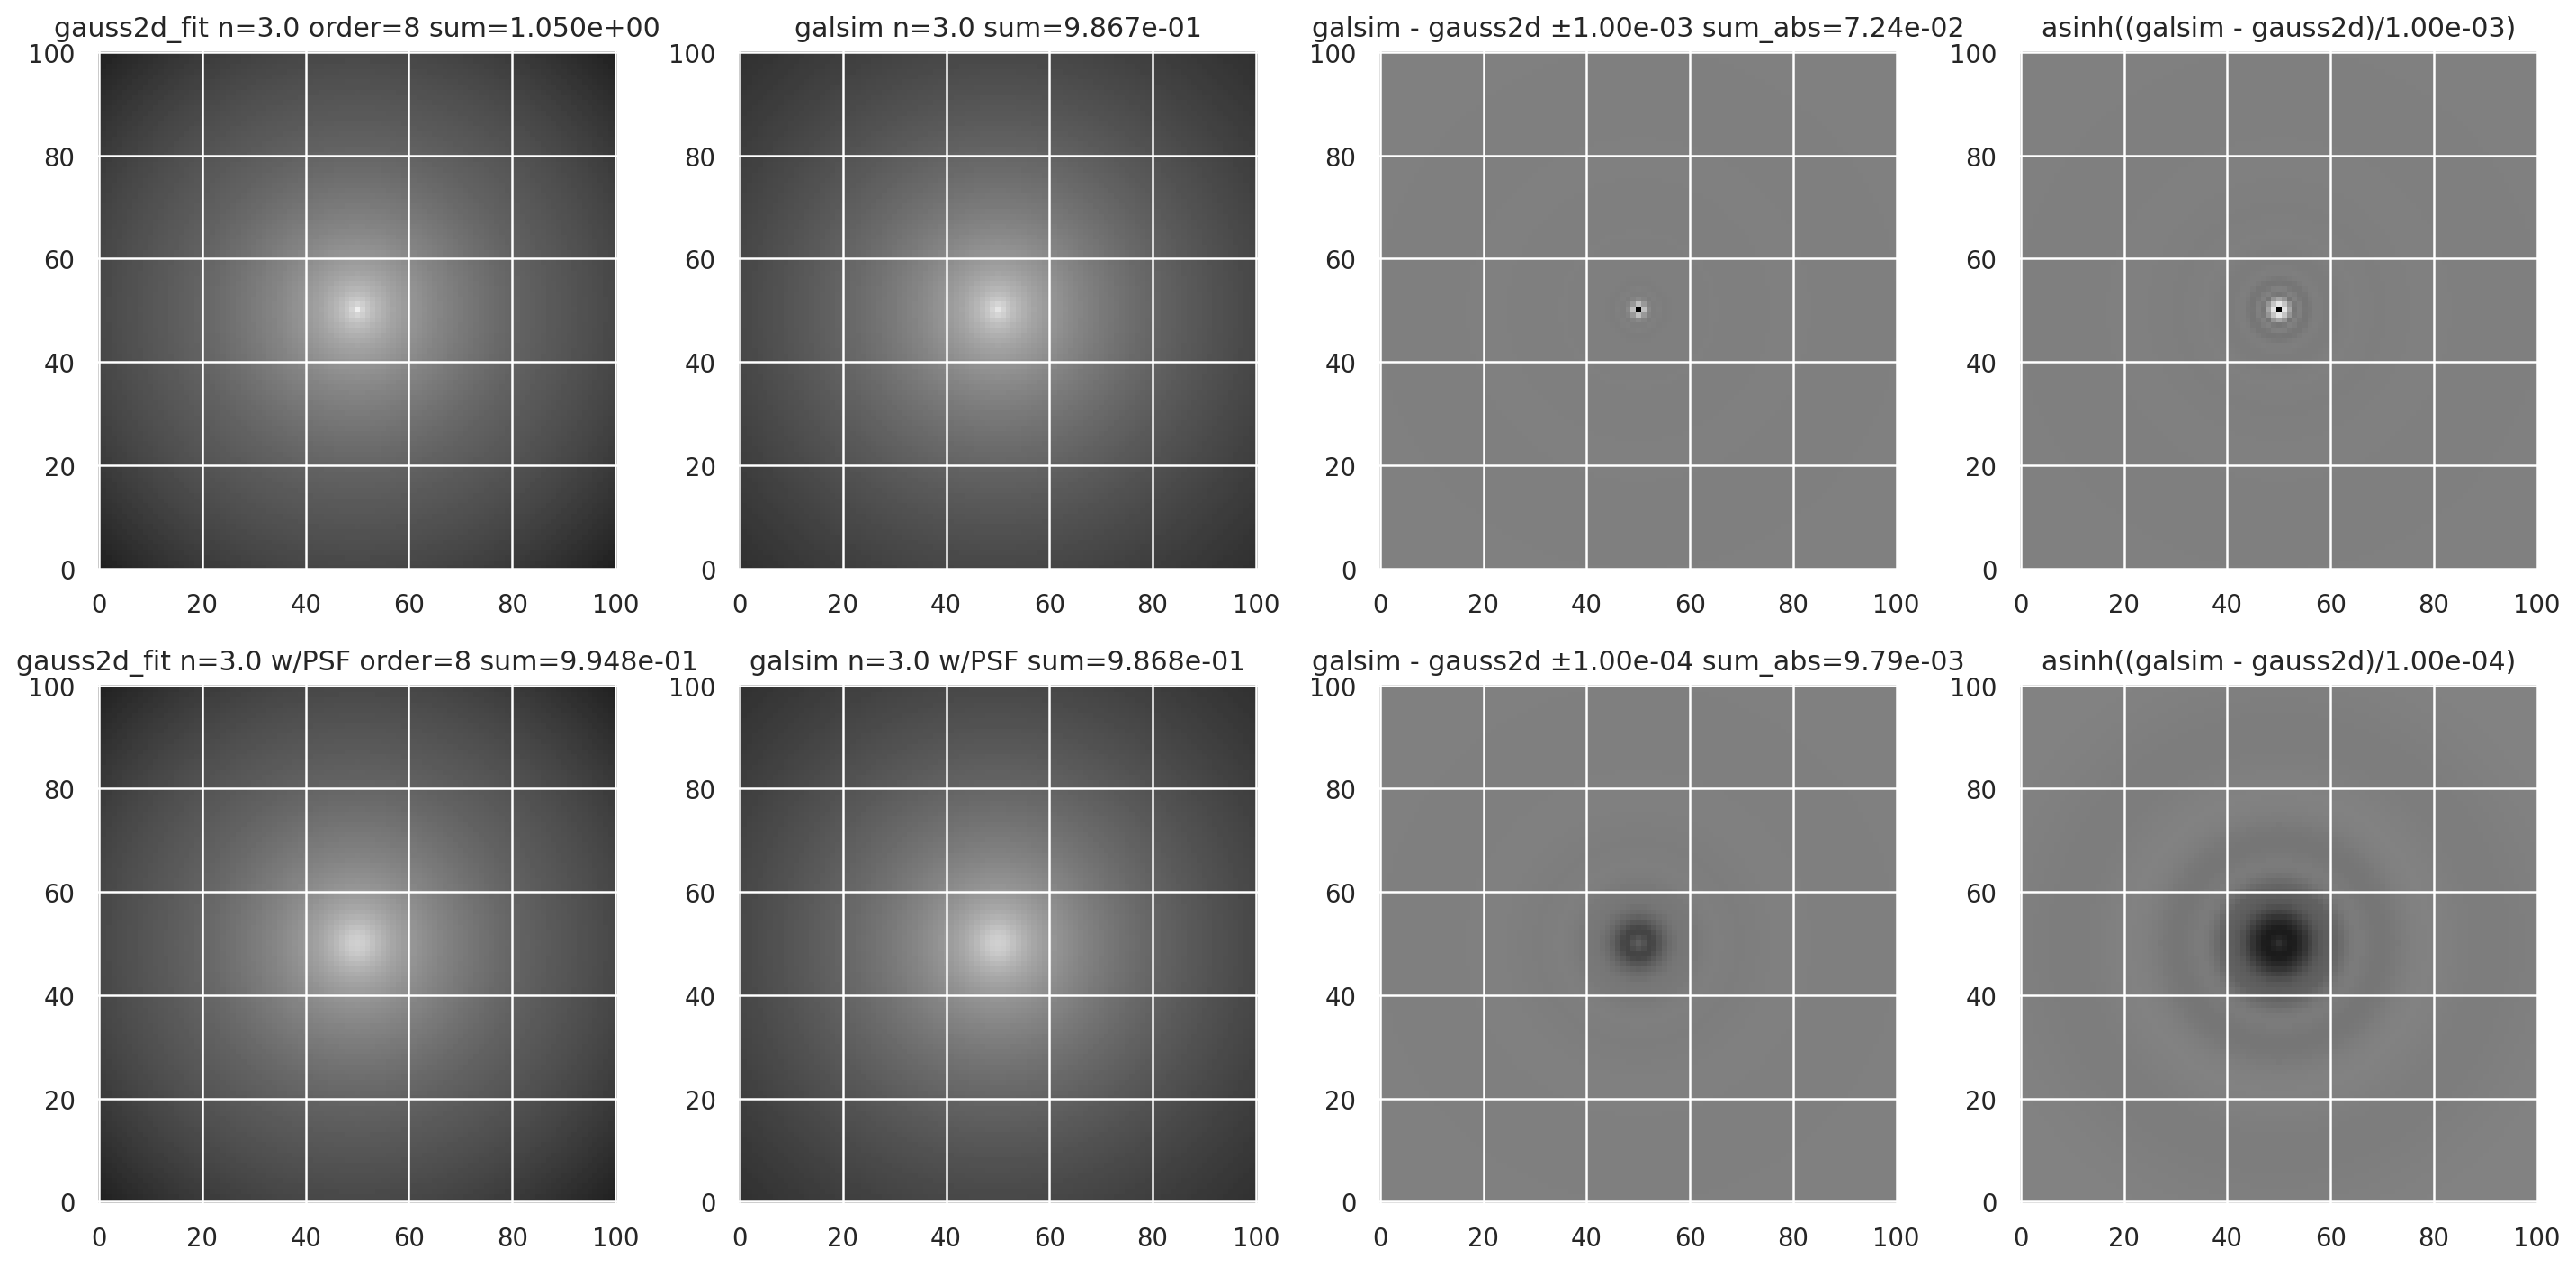

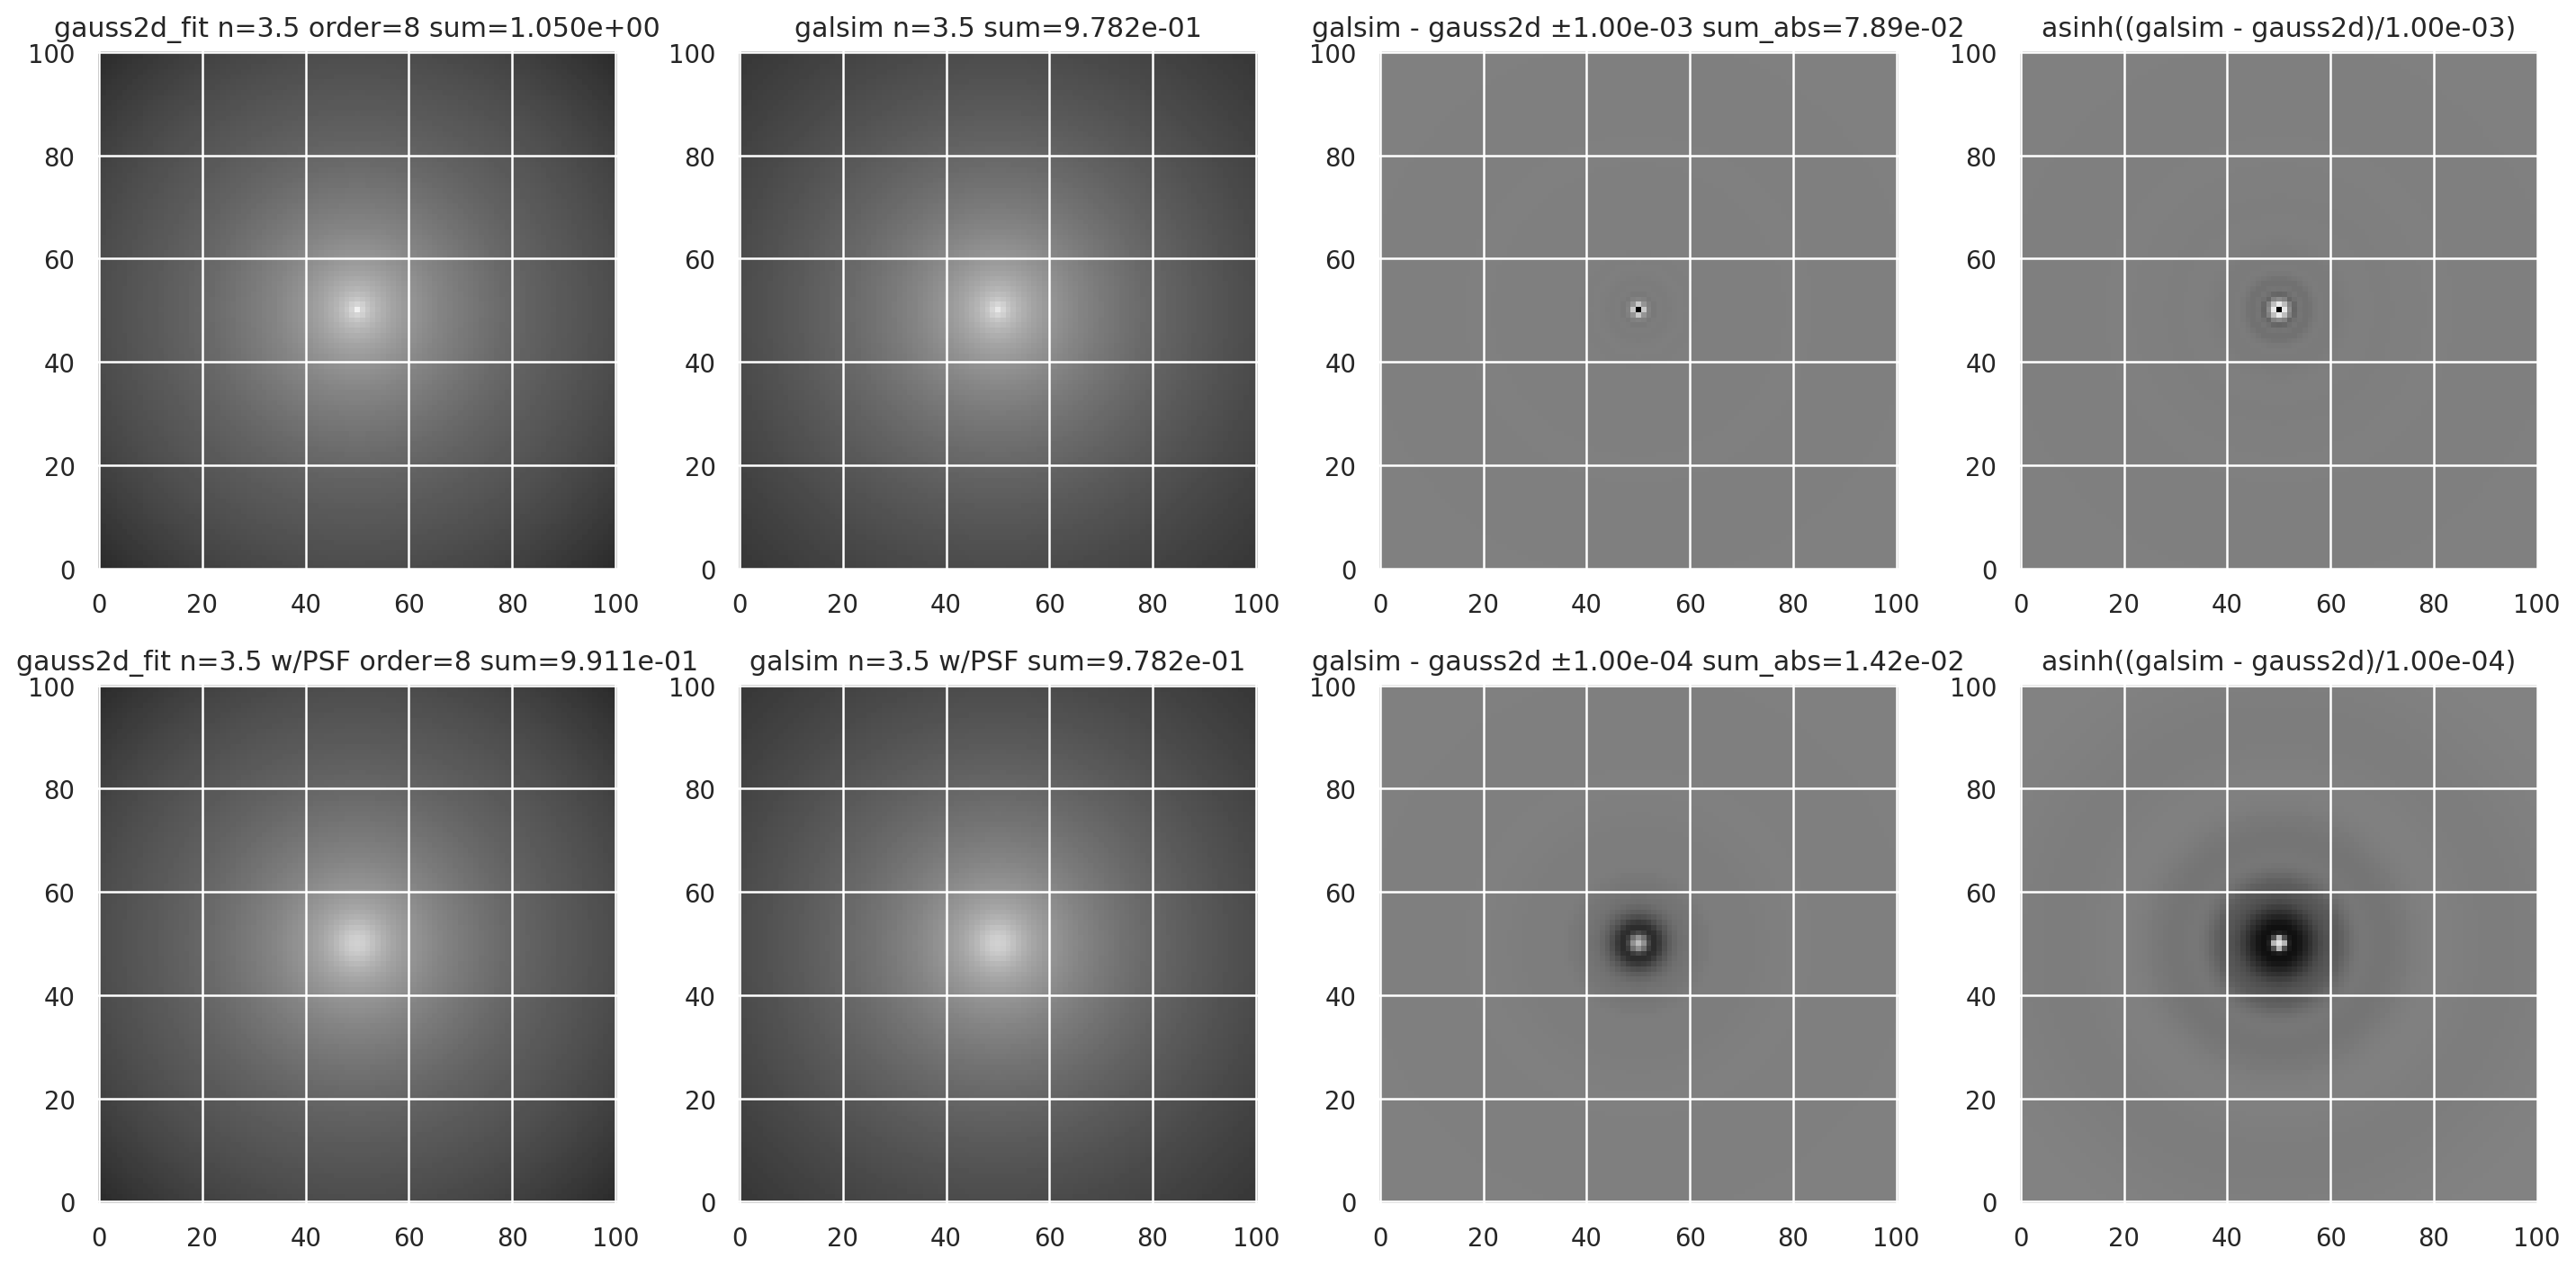

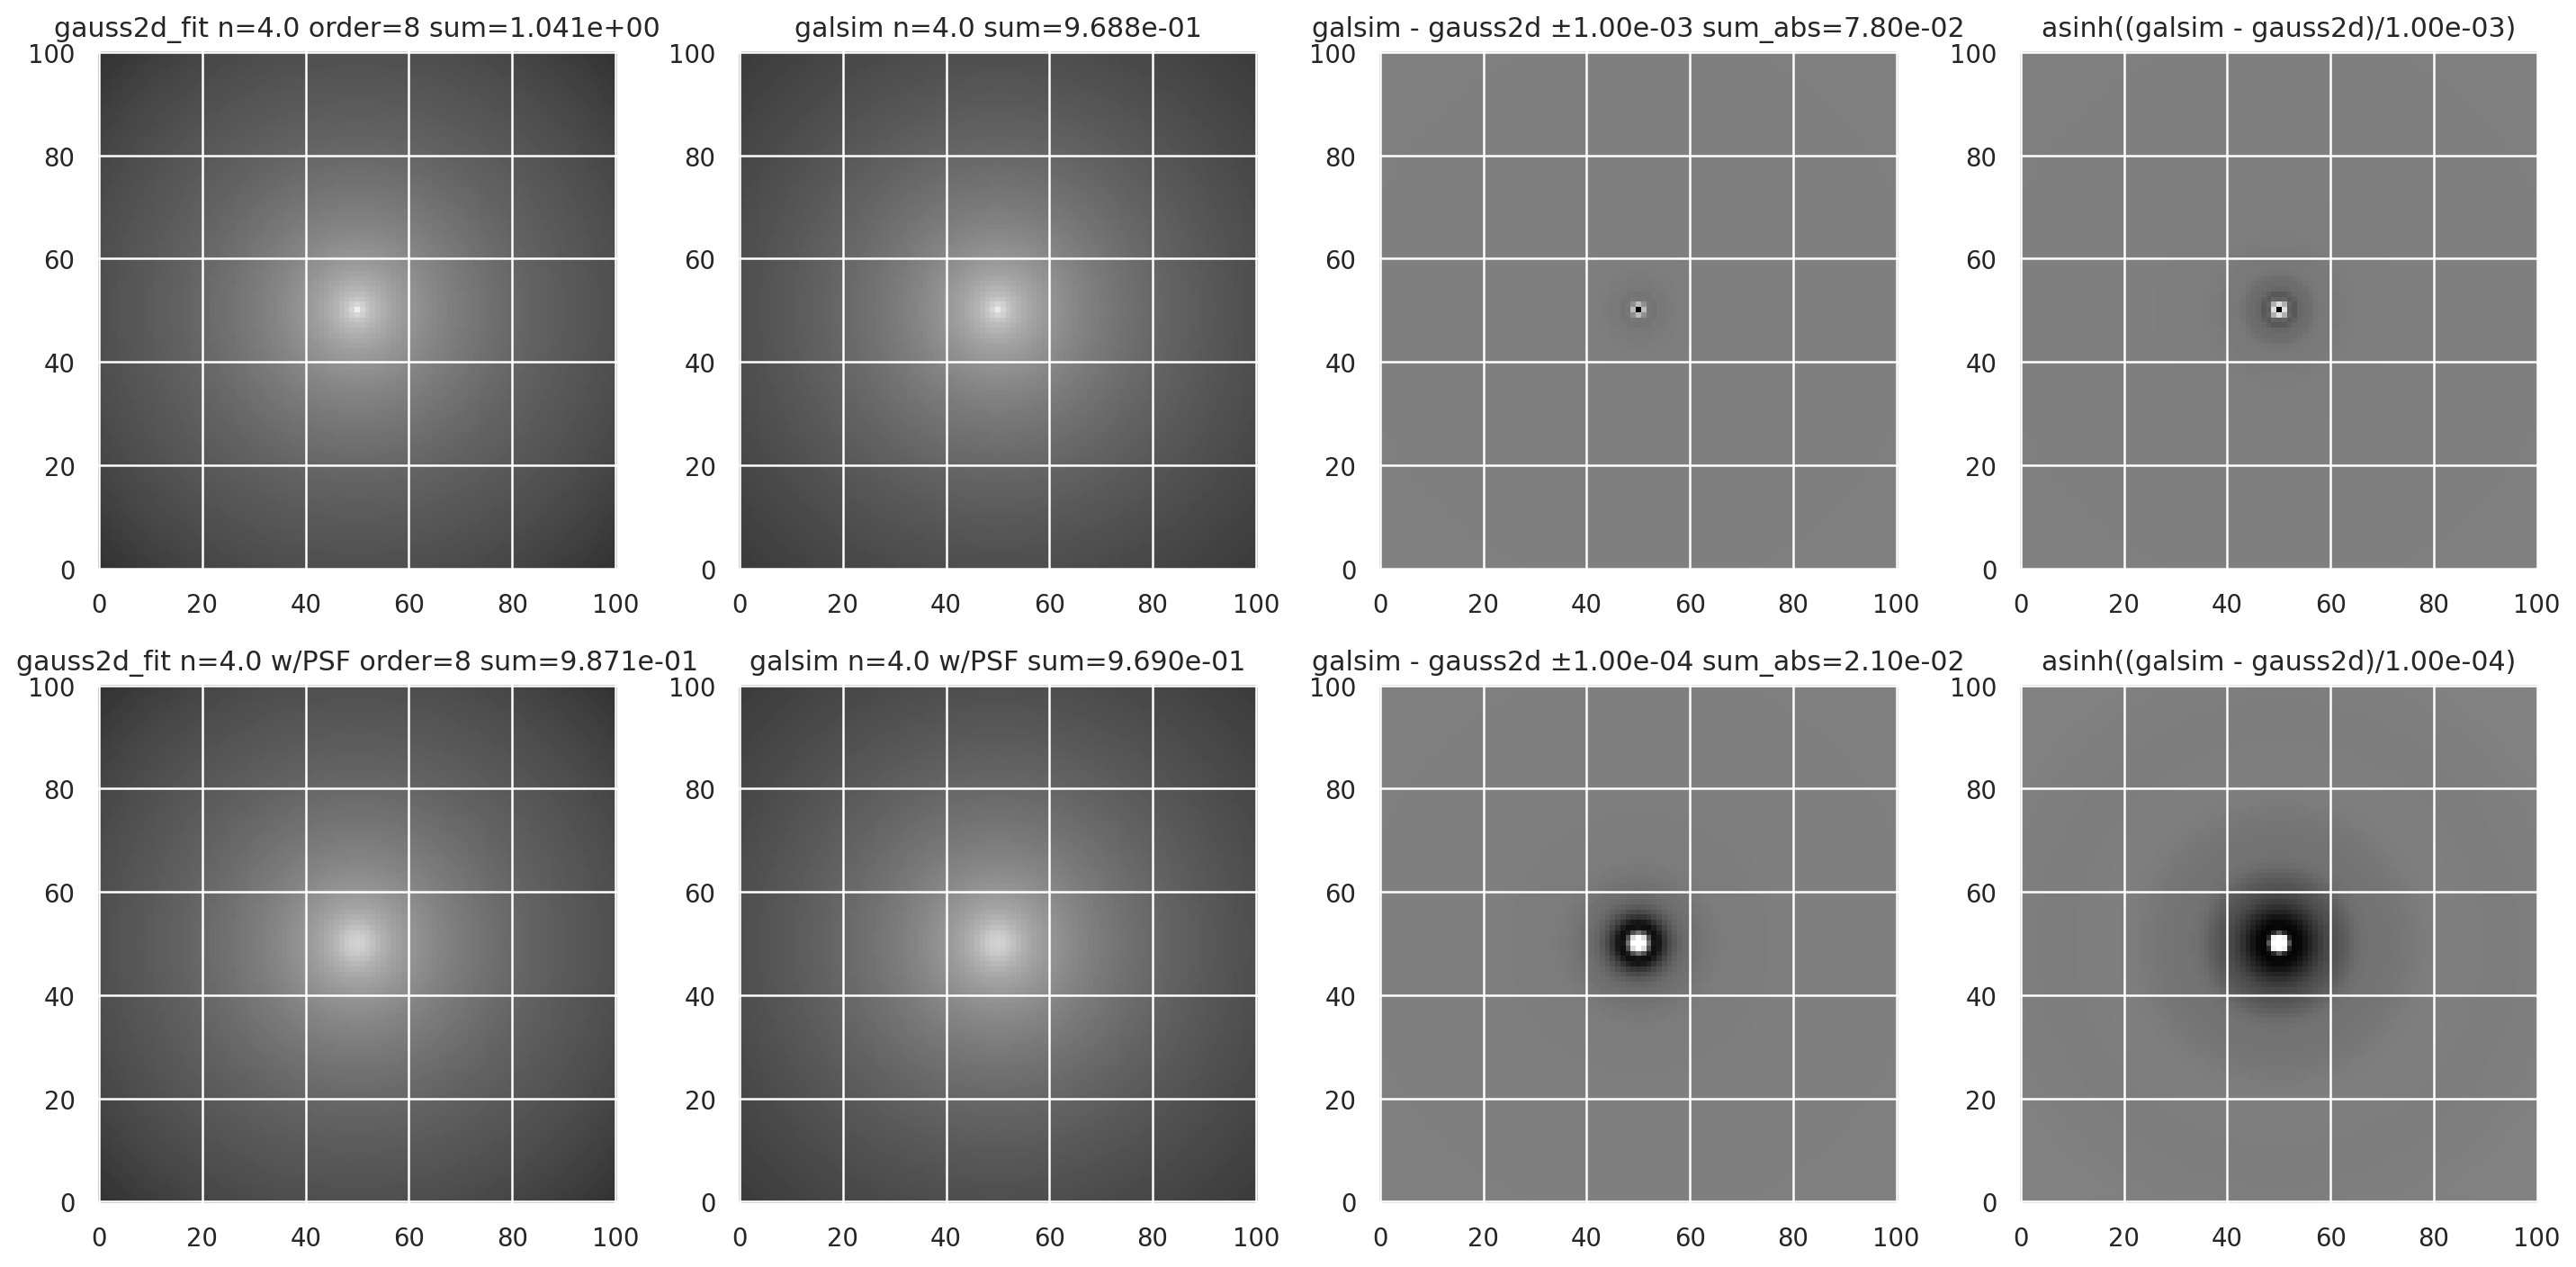

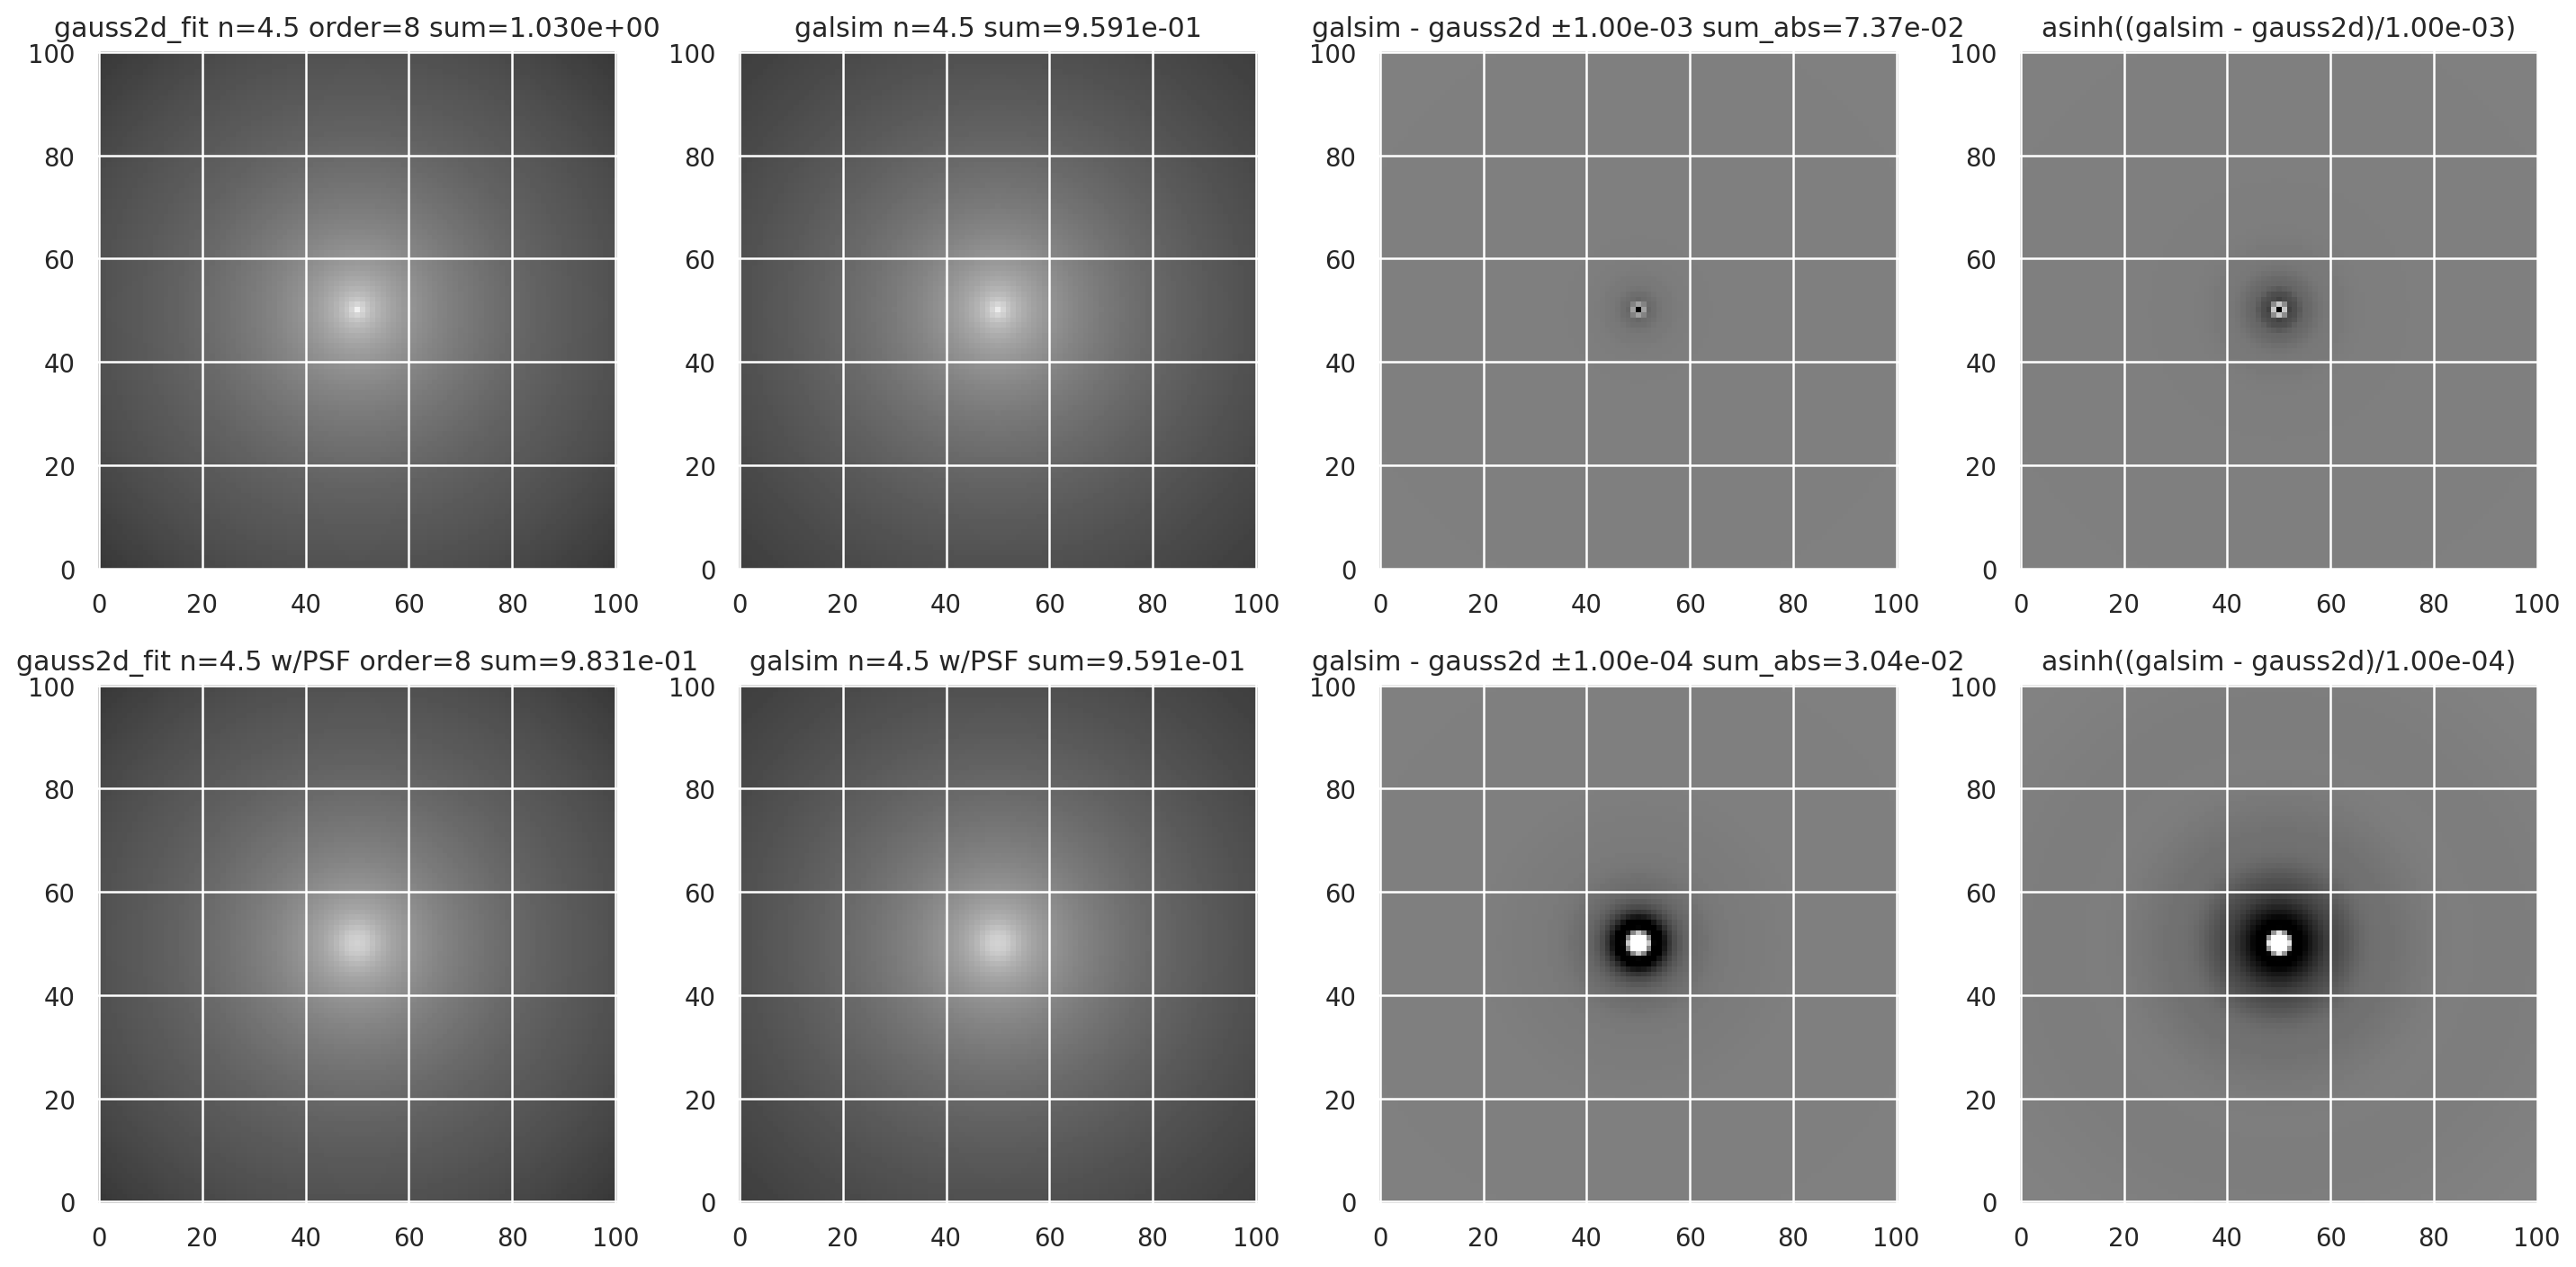

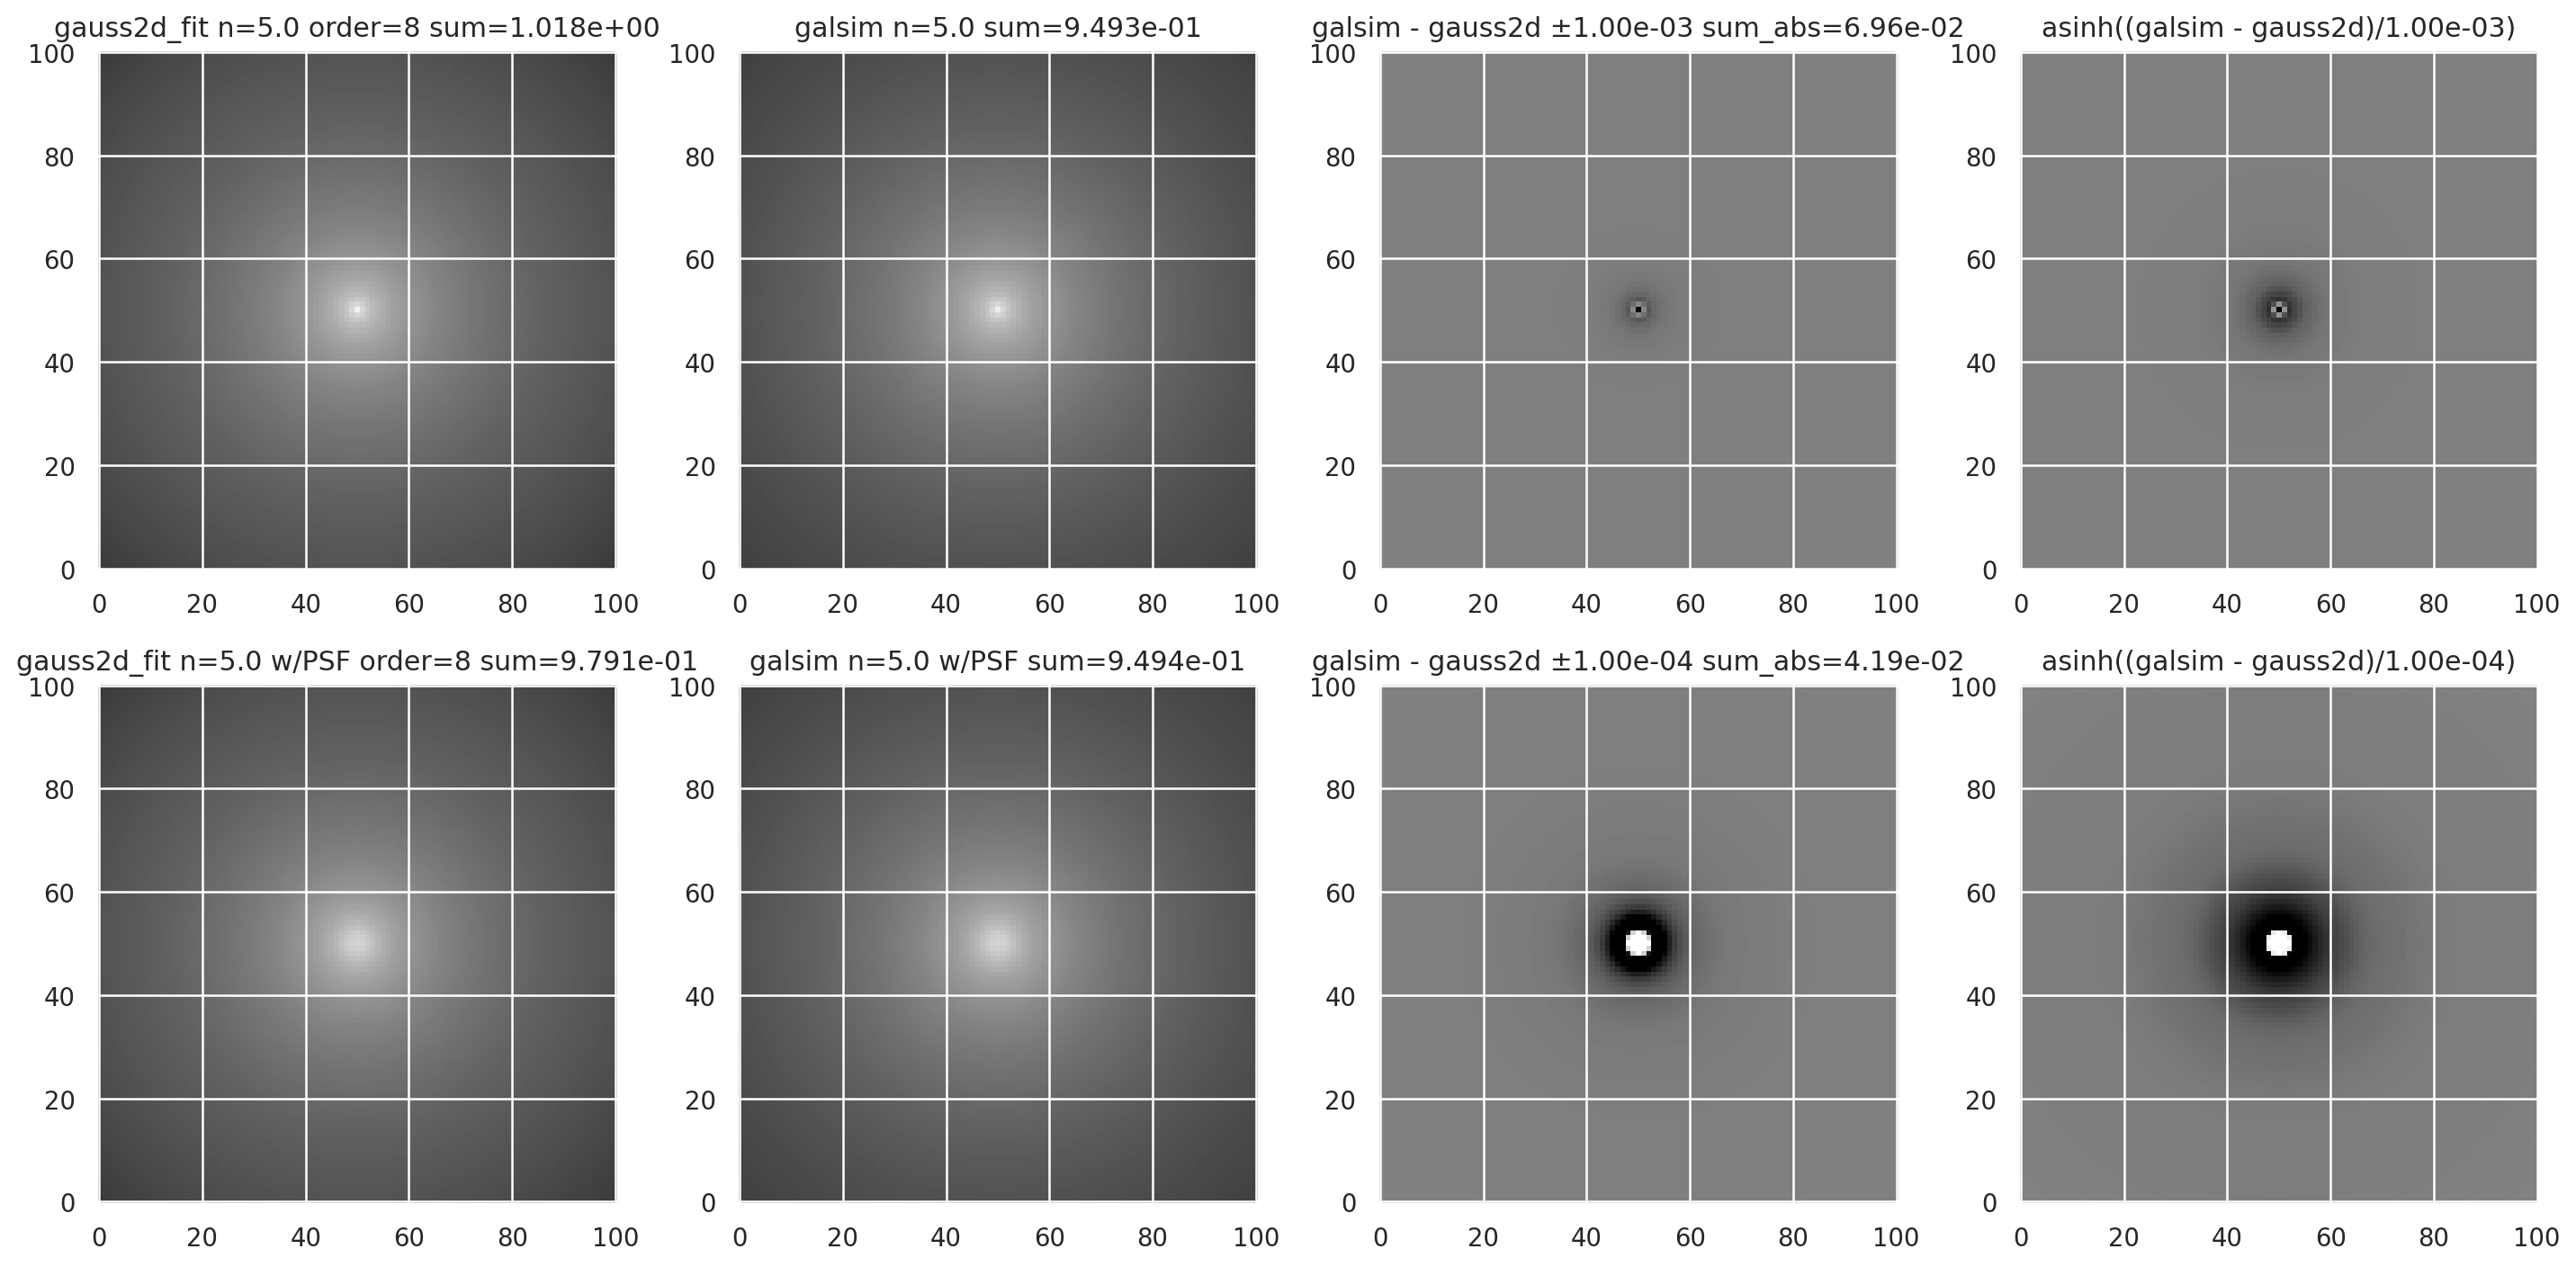

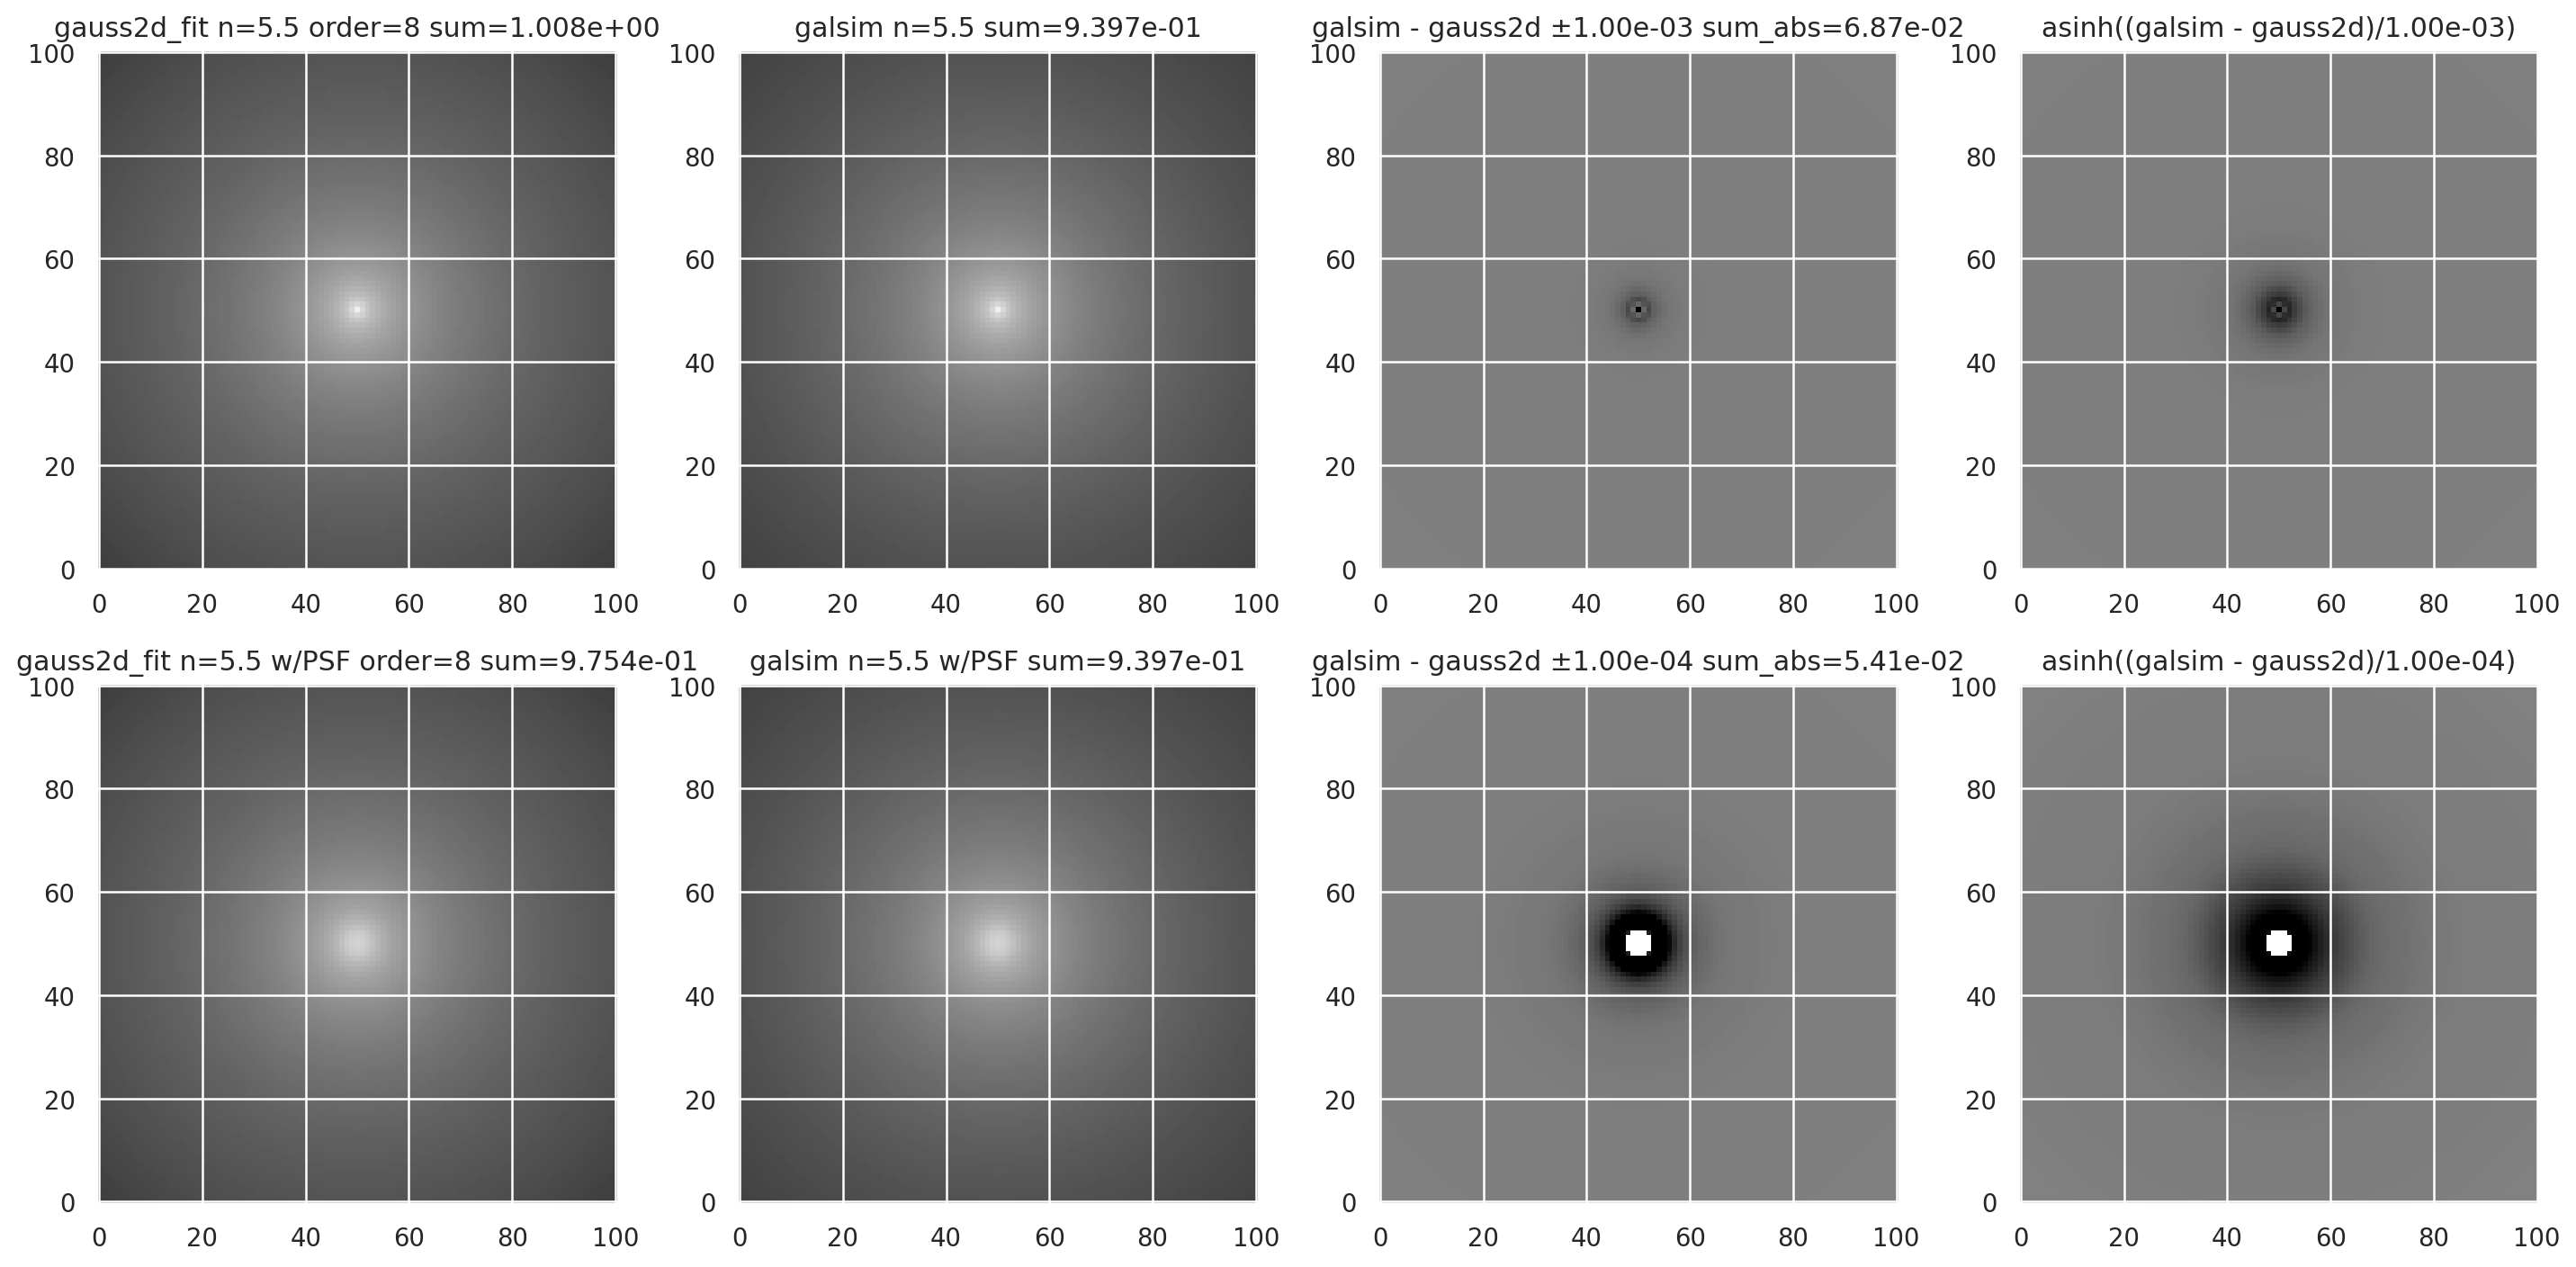

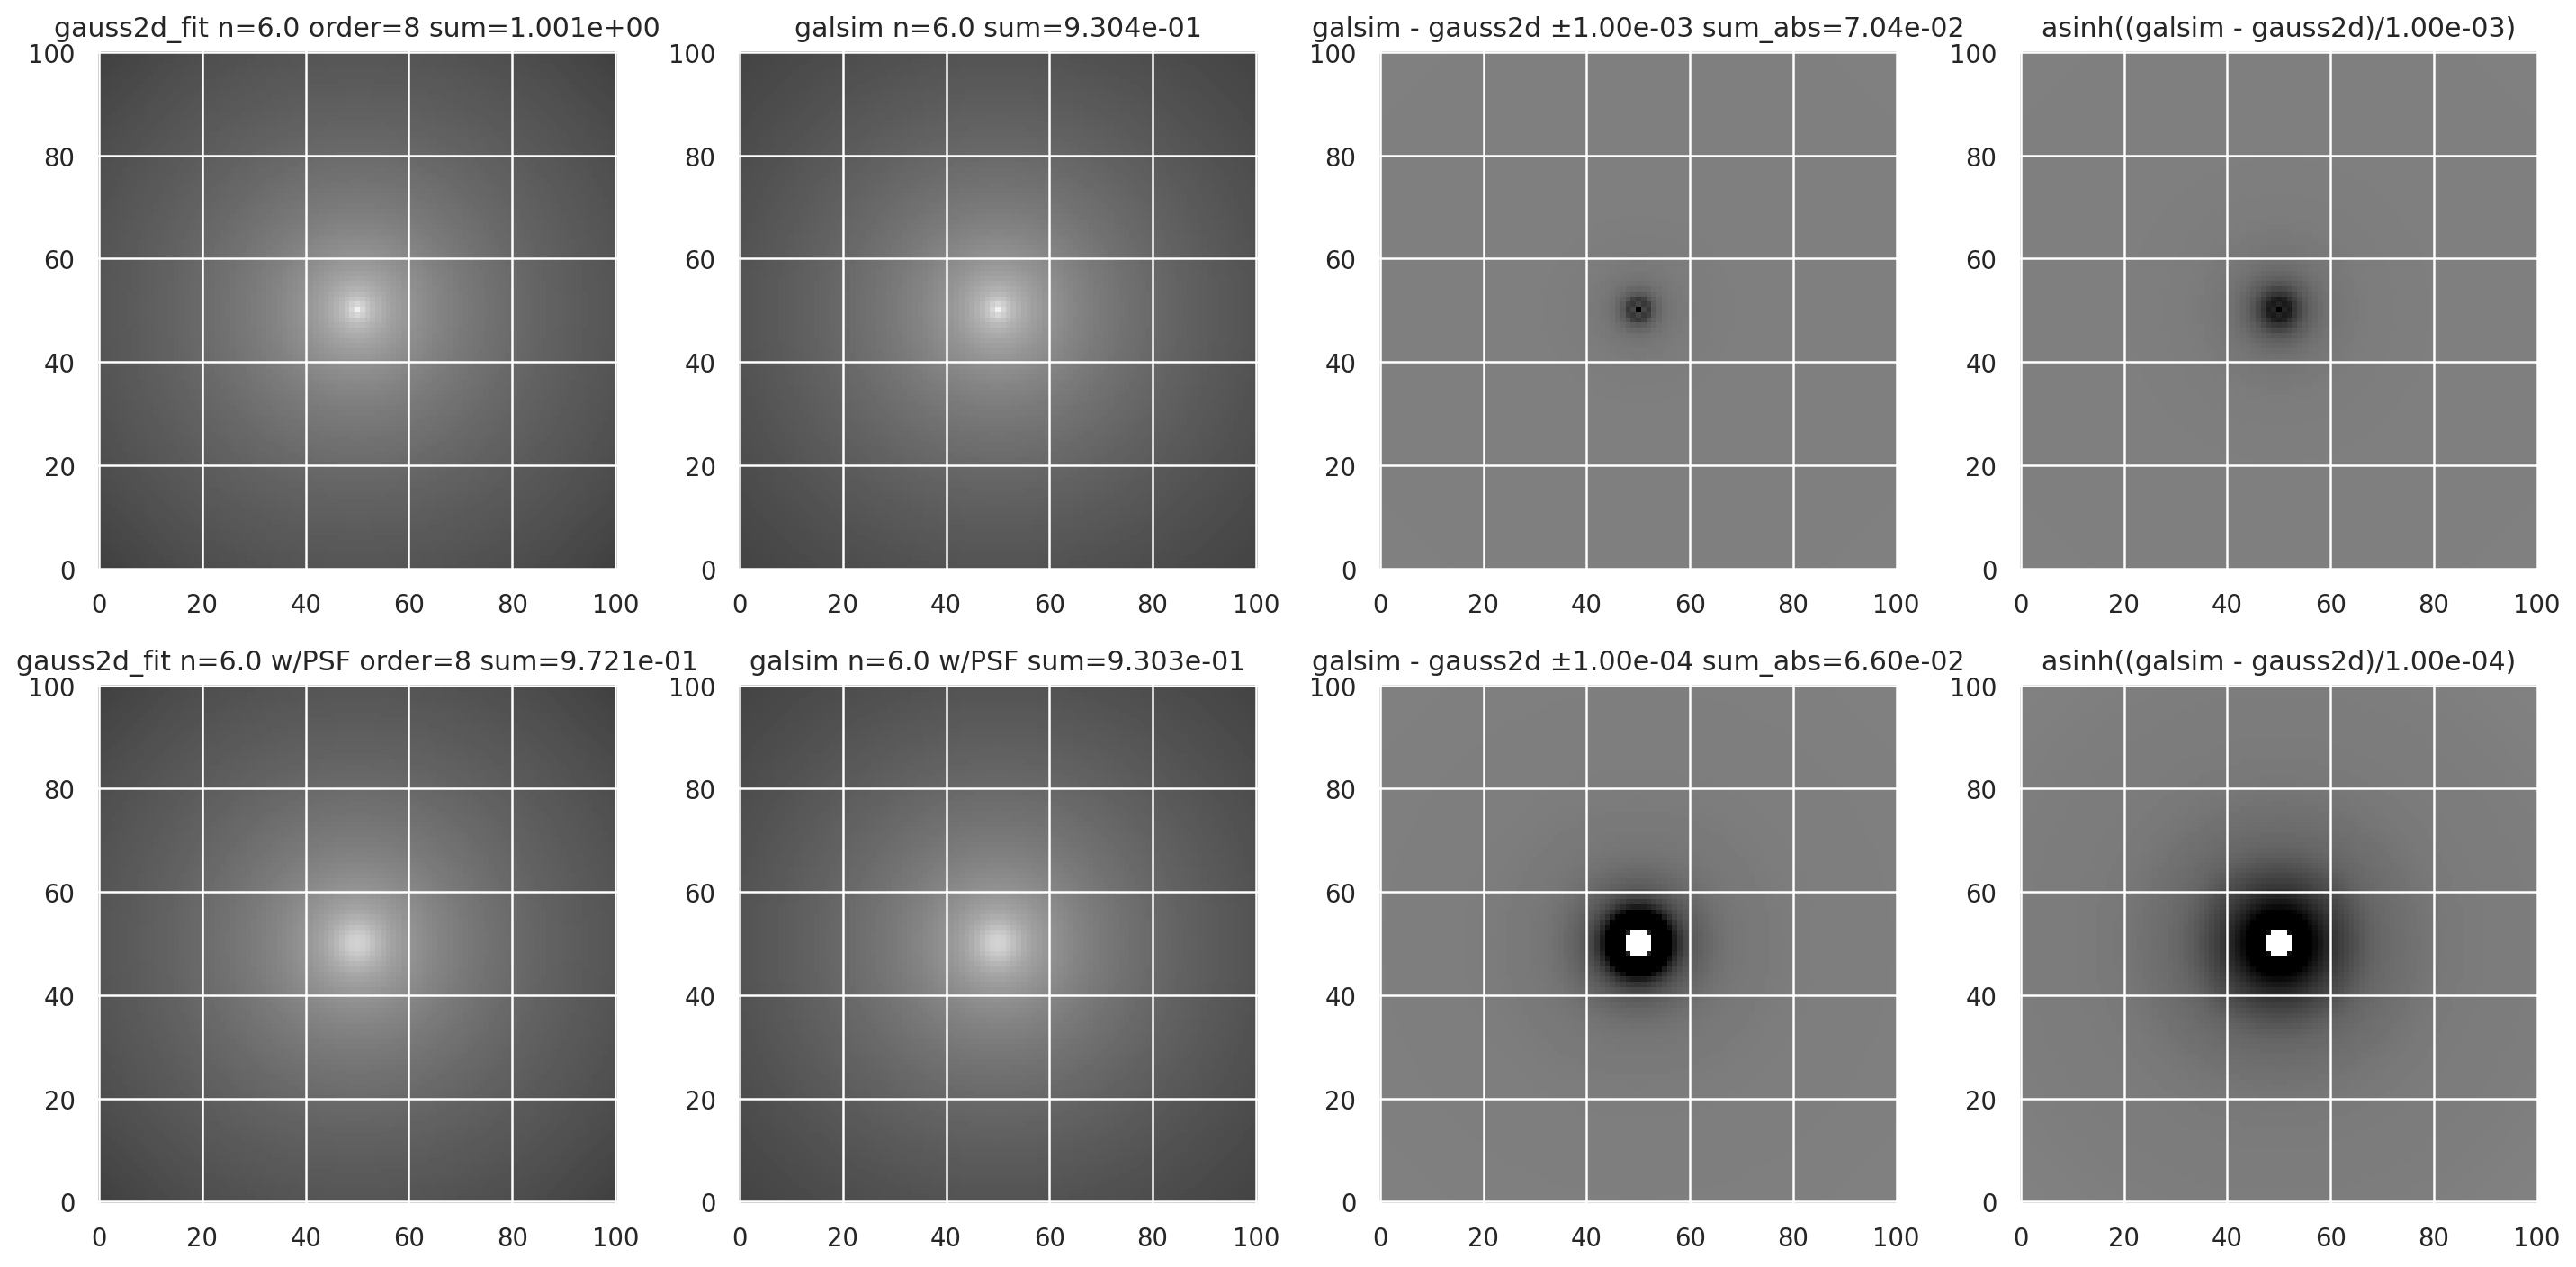

In [9]:
# 10 R_eff at the edges
nx = 101
ny = 101

data = get_gauss2d_data(nx=nx, ny=ny)

for order in (4, 8):
    _, model_sersic, model_sersic_conv = get_gauss2d_fit_models(
        data,
        psfmodel_none,
        psfmodel_gauss,
        half_light_radius=half_light_radius,
        nx=nx,
        ny=ny,
        interpolator=g2f.GSLSersicMixInterpolator(order)
    )
    model_sersic.setup_evaluators(evaluatormode=g2f.EvaluatorMode.image)
    model_sersic_conv.setup_evaluators(evaluatormode=g2f.EvaluatorMode.image)
    for sersic_index in (
        0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0,
    ):
        fig, ax = plot_sersicmix(
            sersic_index=sersic_index,
            half_light_radius=half_light_radius,
            model_sersic=model_sersic,
            model_sersic_conv=model_sersic_conv,
            galsim_module=gs,
            psf_galsim=psf_gs,
            vmax_resid=1e-3,
            vmax_resid_conv=1e-4,
            scale_arcsinh=50./sersic_index,
        )
        fig.tight_layout()
